# 04 — Entrenamiento y evaluación de modelos

## Actividad 2.14

La fase A fija el experimento y las particiones. No entrena modelos. La fase B, desde la sección 5, estima solo la regresión lineal y el polinomio de grado 2 con cresta. No elige un ganador de la actividad.

La selección de candidatos quedó cerrada en la actividad 2.13. Este cuaderno no la reabre. Mapping y surging siguen separados. La recta por condición, el bosque y el cociente respecto del agua no se estiman en esta fase.


## 4.1. Introducción

Se quiere predecir `dp2_3_psi`, el incremento de presión leído como el de la etapa 3, en psi. La certeza de ese enlace es media y está en el diccionario. El gas libre disminuye ese incremento. La actividad 2.13 vio, sin ajustar nada, que las curvas de agua bajan al subir el caudal y que la mayoría de los puntos con gas quedan por debajo del agua cercana. Eso no dice qué ecuación predice una curva dejada fuera.

El resultado útil será un error medido al reservar curvas completas. El error de entrenamiento no sirve para elegir el modelo.


## 4.2. Hipótesis

Siguen abiertas. Esta fase no las contrasta.

- **H1.** Un polinomio de grado 2, o una recta distinta por la condición ya escrita, tendrá menor error absoluto medio externo que la recta global. Si no ocurre, la recta global sigue siendo la referencia.
- **H2.** A velocidad y presión fijas, la predicción no sube de forma sistemática al aumentar el gas dentro del rango de la curva. Una subida local no se llamará cambio de régimen sin una comprobación aparte.
- **H3.** Con 30 y 18 curvas, el bosque poco profundo no mejora a la recta de manera estable.
- **H4.** En mapping, la curva de agua de la misma hoja y velocidad ayuda a leer la degradación. No es la presión normalizada de Zhu et al. (2018), porque falta la densidad.

La pregunta de la actividad es cuál candidato predice mejor cada protocolo. No se responde aquí.


## 4.3. Materiales y métodos

**Datos.** Mendeley Data, DOI 10.17632/fk2b4r69bs.1, licencia CC BY 4.0, serie sin isopropanol. Se leen los CSV de la actividad 2.12. No se reescriben.

**Objetivo.** `dp2_3_psi`.

**Predictores de mapping.** Caudal de líquido en bpd, indicador de `Single Phase`, Qgd sin rellenar el vacío, velocidad en rpm y presión del separador en psig.

**Predictores de surging.** `gvf0_porcentaje`, fracción de QBEP, velocidad y presión. La fracción es el bloque de líquido. GVF0 es el gas continuo. No son la misma variable.

**No son predictores.** Fila, archivo, posiciones de columna, identificador de curva y `origen_velocidad`. La hoja no entra como texto: la presión ya está en `psep_psig`.

**Semilla.** 214. El reparto externo no sortea curvas. La semilla queda para cualquier sorteo de una fase posterior.

**Validación prevista.** Tres pliegues externos por protocolo. La unidad es la curva. Dentro del entrenamiento de cada pliegue, un `GroupKFold` elegirá más adelante la penalización y la profundidad. Ese anillo no publica el error.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.model_selection import GroupKFold


def encontrar_raiz_laboratorio() -> Path:
    candidato = Path.cwd().resolve()
    for _ in range(6):
        if (candidato / "data" / "raw" / "mapping.xlsx").is_file() and (
            candidato / "data" / "raw" / "surging.xlsx"
        ).is_file():
            return candidato
        if candidato.parent == candidato:
            break
        candidato = candidato.parent
    raise FileNotFoundError("No se encontró el laboratorio.")


RAIZ = encontrar_raiz_laboratorio()
sys.path.insert(0, str(RAIZ / "src"))
from esp_datascience.particiones import SEMILLA
from esp_datascience.rutas import huella_sha256

HUELLAS = {
    "data/raw/mapping.xlsx": "3b933ca84911484f5d912a44b025f5589abaf5ebc2b0426bf80c083869762bda",
    "data/raw/surging.xlsx": "acdcc6c5fc3d8969280c8712c45657fbb863f163a60829584fece5abf75f28cd",
    "data/processed/mapping_long.csv": "ff68e36703d3d3901b8bd964008c49b062afa9d89a817b9d66e7849f9b400648",
    "data/processed/surging_long.csv": "f58e8e2cac74acdf2081479ec8769422f39c4e4665f5b3ff472df4a70b15bd96",
}
for relativo, esperada in HUELLAS.items():
    if huella_sha256(RAIZ / relativo) != esperada:
        raise RuntimeError(f"Cambió la huella de {relativo}.")
    print(f"{relativo}: huella igual")

mapping = pd.read_csv(RAIZ / "data" / "processed" / "mapping_long.csv")
surging = pd.read_csv(RAIZ / "data" / "processed" / "surging_long.csv")
if len(mapping) != 570 or len(surging) != 387:
    raise RuntimeError("Los conteos ya no son los de la actividad 2.12.")
print(f"numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}")
print(f"Semilla fijada: {SEMILLA}. Mapping {len(mapping)} filas. Surging {len(surging)} filas.")
print("Los CSV no se modifican.")


data/raw/mapping.xlsx: huella igual
data/raw/surging.xlsx: huella igual
data/processed/mapping_long.csv: huella igual
data/processed/surging_long.csv: huella igual
numpy 2.5.4, pandas 3.0.6, scikit-learn 1.9.1
Semilla fijada: 214. Mapping 570 filas. Surging 387 filas.
Los CSV no se modifican.


## 4.4. Preparación

Una curva es la terna hoja, velocidad y condición. En mapping la condición es `Single Phase` o un Qgd. En surging es la fracción de QBEP. Los puntos de una terna son un solo ensayo.

`qgd` vacío es agua. No es un caudal de gas igual a cero.


In [2]:
HOJAS = ("50psig", "100psig", "150psig")
FRACCIONES = ("0.75Qbep", "Qbep", "1.25Qbep")
PREDICTORES_MAPPING = ("ql_bpd", "es_monofasica", "qgd", "velocidad_rpm", "psep_psig")
PREDICTORES_SURGING = ("gvf0_porcentaje", "fraccion_qbep", "velocidad_rpm", "psep_psig")
PROHIBIDOS = {
    "archivo", "hoja", "fila", "columna_condicion", "columna_caudal", "columna_dp",
    "columna_gvf", "curva_id", "origen_velocidad", "fila_celda_velocidad",
    "columna_celda_velocidad", "valor_celda_velocidad", "pliegue",
}


def identificador_curva(tabla: pd.DataFrame) -> pd.Series:
    return (
        tabla["hoja"].astype(str)
        + "|"
        + tabla["velocidad_rpm"].astype(int).astype(str)
        + "|"
        + tabla["condicion"].astype(str)
    )


def entradas_mapping(tabla: pd.DataFrame) -> pd.DataFrame:
    es_monofasica = tabla["condicion"].eq("Single Phase")
    if not np.array_equal(es_monofasica.to_numpy(), tabla["qgd"].isna().to_numpy()):
        raise ValueError("El vacío de qgd ya no coincide con Single Phase.")
    entradas = pd.DataFrame(
        {
            "ql_bpd": tabla["ql_bpd"].to_numpy(),
            "es_monofasica": es_monofasica.to_numpy(),
            "qgd": tabla["qgd"].to_numpy(),
            "velocidad_rpm": tabla["velocidad_rpm"].to_numpy(),
            "psep_psig": tabla["psep_psig"].to_numpy(),
        }
    )
    if entradas.loc[entradas["es_monofasica"], "qgd"].notna().any():
        raise ValueError("qgd de agua fue rellenado.")
    return entradas


entradas_m = entradas_mapping(mapping)
entradas_s = surging.loc[:, list(PREDICTORES_SURGING)].copy()
if set(entradas_m.columns) & PROHIBIDOS or set(entradas_s.columns) & PROHIBIDOS:
    raise RuntimeError("Un metadato entró como predictor.")
print("Predictores de mapping:", list(entradas_m.columns))
print("Filas de agua con qgd vacío:", int(entradas_m["es_monofasica"].sum()))
print("Predictores de surging:", list(entradas_s.columns), "celdas vacías:", int(entradas_s.isna().sum().sum()))
print("Curvas:", identificador_curva(mapping).nunique(), "mapping;", identificador_curva(surging).nunique(), "surging.")
celda = mapping["origen_velocidad"].eq("celda")
print("Velocidad leída en la celda:", int(celda.sum()), "filas;", sorted(mapping.loc[celda, "hoja"].unique()))


Predictores de mapping: ['ql_bpd', 'es_monofasica', 'qgd', 'velocidad_rpm', 'psep_psig']
Filas de agua con qgd vacío: 87
Predictores de surging: ['gvf0_porcentaje', 'fraccion_qbep', 'velocidad_rpm', 'psep_psig'] celdas vacías: 0
Curvas: 30 mapping; 18 surging.
Velocidad leída en la celda: 186 filas; ['50psig']


## 4.5. Particiones

`GroupKFold` no parte una curva. Tampoco equilibra velocidad, presión y condición. En estas tablas, uno de sus cinco pliegues de mapping se queda sin 100 psig, y uno de sus tres pliegues de surging se queda sin la fracción 1,25. Esos cortes no servirían para decir que un modelo cubre el dominio. Se muestran para justificar otro reparto. No se usan para entrenar.

El reparto adoptado tiene tres pliegues. Cada curva va a uno solo. Mapping reserva 10 curvas por pliegue y surging reserva 6. Las filas no se equilibran, porque las curvas tienen distinto largo. La comparación futura pesará cada curva por igual.

En mapping, la curva de agua no cae en el mismo pliegue que el gas de su hoja y velocidad. Así, al predecir ese gas, el agua está del lado del entrenamiento. Al ajustar, solo la mitad de las curvas con gas del entrenamiento tienen su agua también en el entrenamiento. La otra mitad no podrá entrar en el cociente: su agua está en la prueba. Esta fase no calcula ese cociente.

En surging, cada pliegue ve las tres fracciones en la prueba y en el entrenamiento. Una recta por fracción se puede estimar. La fracción no se confunde con GVF0.

Dejar fuera todas las curvas de un mismo Qgd, para probar una condición nunca vista, es otro experimento. Ahí la recta de esa etiqueta no tiene coeficientes. No se ejecuta ahora.


In [3]:
def diagnostico_groupkfold(tabla: pd.DataFrame, n_splits: int, nombre: str) -> None:
    grupos = identificador_curva(tabla).to_numpy()
    print(f"GroupKFold de {nombre}, {n_splits} cortes. No es el reparto adoptado.")
    for indice, (_entrenamiento, prueba) in enumerate(GroupKFold(n_splits).split(tabla, groups=grupos)):
        sub = tabla.iloc[prueba]
        velocidades = sorted(int(v) for v in sub["velocidad_rpm"].unique())
        presiones = sorted(sub["hoja"].unique())
        motivos = []
        if set(velocidades) != {1800, 3500}:
            motivos.append("falta una velocidad")
        if set(presiones) != set(HOJAS):
            motivos.append("falta una presión")
        faltan = sorted(set(tabla["condicion"]) - set(sub["condicion"]))
        if faltan:
            motivos.append("faltan " + ", ".join(faltan))
        aviso = (" — " + "; ".join(motivos)) if motivos else ""
        print(
            f"  pliegue {indice}: {identificador_curva(sub).nunique()} curvas, "
            f"velocidades {velocidades}, hojas {presiones}{aviso}"
        )


diagnostico_groupkfold(mapping, 5, "mapping")
diagnostico_groupkfold(surging, 3, "surging")


GroupKFold de mapping, 5 cortes. No es el reparto adoptado.
  pliegue 0: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan Qgd=0.02, Qgd=0.03, Qgd=0.05
  pliegue 1: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan Qgd=0.005, Qgd=0.015, Qgd=0.04, Single Phase
  pliegue 2: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan Qgd=0.01, Qgd=0.04
  pliegue 3: 6 curvas, velocidades [1800, 3500], hojas ['150psig', '50psig'] — falta una presión; faltan Qgd=0.03, Qgd=0.04, Qgd=0.05
  pliegue 4: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan Qgd=0.005, Qgd=0.01, Qgd=0.015, Qgd=0.02
GroupKFold de surging, 3 cortes. No es el reparto adoptado.
  pliegue 0: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig']
  pliegue 1: 6 curvas, velocidades [1800, 3500], hojas ['100psig', '150psig', '50psig'] — faltan 1.25Qbep
  pliegue 2: 6 curvas, velocid

In [4]:
def pliegue_mapping(hoja: str, velocidad: int, condicion: str) -> int:
    indice = HOJAS.index(hoja)
    velocidad_binaria = 0 if int(velocidad) == 1800 else 1
    if condicion == "Single Phase":
        return (indice + velocidad_binaria) % 3
    if condicion == "Qgd=0.01":
        return (indice + velocidad_binaria + 1) % 3
    if condicion == "Qgd=0.005":
        return (indice + 1) % 3
    if condicion == "Qgd=0.015":
        return (indice + 2) % 3
    if condicion in {"Qgd=0.02", "Qgd=0.04"}:
        return indice % 3
    if condicion in {"Qgd=0.03", "Qgd=0.05"}:
        return (indice + 2) % 3
    raise ValueError(condicion)


def pliegue_surging(hoja: str, condicion: str) -> int:
    return (FRACCIONES.index(condicion) - HOJAS.index(hoja)) % 3


def marcar(tabla: pd.DataFrame, protocolo: str) -> pd.DataFrame:
    copia = tabla.copy()
    copia["curva_id"] = identificador_curva(copia)
    if protocolo == "mapping":
        pares = zip(copia["hoja"], copia["velocidad_rpm"], copia["condicion"], strict=True)
        copia["pliegue"] = [pliegue_mapping(h, v, c) for h, v, c in pares]
    else:
        pares = zip(copia["hoja"], copia["condicion"], strict=True)
        copia["pliegue"] = [pliegue_surging(h, c) for h, c in pares]
    return copia


def curvas_de(tabla: pd.DataFrame) -> pd.DataFrame:
    return (
        tabla.groupby("curva_id", sort=False)
        .agg(
            pliegue=("pliegue", "first"),
            n_pliegues=("pliegue", "nunique"),
            hoja=("hoja", "first"),
            velocidad_rpm=("velocidad_rpm", "first"),
            condicion=("condicion", "first"),
            n_filas=("curva_id", "size"),
            origen_velocidad=("origen_velocidad", "first"),
        )
        .reset_index()
    )


def revisar(curvas: pd.DataFrame, prueba: set[str], entrenamiento: set[str]) -> dict:
    compartidas = prueba & entrenamiento
    if compartidas:
        raise RuntimeError(f"Fuga de curva: {sorted(compartidas)[0]}")
    lado_prueba = curvas[curvas["curva_id"].isin(prueba)]
    lado_entrenamiento = curvas[curvas["curva_id"].isin(entrenamiento)]
    faltan = sorted(set(lado_prueba["condicion"]) - set(lado_entrenamiento["condicion"]))
    return {
        "n_curvas_prueba": len(prueba),
        "n_curvas_entrenamiento": len(entrenamiento),
        "n_filas_prueba": int(lado_prueba["n_filas"].sum()),
        "velocidades": sorted(int(v) for v in lado_prueba["velocidad_rpm"].unique()),
        "hojas": sorted(lado_prueba["hoja"].unique()),
        "n_condiciones": int(lado_prueba["condicion"].nunique()),
        "condiciones_ausentes_en_entrenamiento": faltan,
    }


mapping_p = marcar(mapping, "mapping")
surging_p = marcar(surging, "surging")
curvas_m = curvas_de(mapping_p)
curvas_s = curvas_de(surging_p)
if (curvas_m["n_pliegues"] != 1).any() or (curvas_s["n_pliegues"] != 1).any():
    raise RuntimeError("Una curva quedó partida.")

filas_resumen = []
for nombre, curvas in (("mapping", curvas_m), ("surging", curvas_s)):
    for pliegue, grupo in curvas.groupby("pliegue"):
        prueba = set(grupo["curva_id"])
        entrenamiento = set(curvas.loc[curvas["pliegue"] != pliegue, "curva_id"])
        filas_resumen.append({"protocolo": nombre, "pliegue": int(pliegue), **revisar(curvas, prueba, entrenamiento)})
resumen = pd.DataFrame(filas_resumen)
if resumen["condiciones_ausentes_en_entrenamiento"].map(len).any():
    raise RuntimeError("Hay una condición de prueba que el entrenamiento no vio.")
if not resumen["velocidades"].map(lambda valores: valores == [1800, 3500]).all():
    raise RuntimeError("Un pliegue perdió una velocidad.")
if not resumen["hojas"].map(lambda valores: set(valores) == set(HOJAS)).all():
    raise RuntimeError("Un pliegue perdió una presión.")
display(resumen)
print("Curvas de prueba, suma por protocolo:", resumen.groupby("protocolo")["n_curvas_prueba"].sum().to_dict())

from esp_datascience.particiones import pliegue_mapping as pliegue_mapping_modulo
from esp_datascience.particiones import pliegue_surging as pliegue_surging_modulo

igual_m = all(
    pliegue_mapping(h, v, c) == pliegue_mapping_modulo(h, v, c)
    for h, v, c in curvas_m[["hoja", "velocidad_rpm", "condicion"]].itertuples(index=False)
)
igual_s = all(
    pliegue_surging(h, c) == pliegue_surging_modulo(h, c)
    for h, c in curvas_s[["hoja", "condicion"]].itertuples(index=False)
)
if not igual_m or not igual_s:
    raise RuntimeError("El cuaderno y el módulo no asignan el mismo pliegue.")
print("El módulo src/esp_datascience/particiones.py asigna los mismos pliegues.")


,protocolo,pliegue,n_curvas_prueba,n_curvas_entrenamiento,n_filas_prueba,velocidades,hojas,n_condiciones,condiciones_ausentes_en_entrenamiento
0,mapping,0,10,20,200,"[1800, 3500]","[100psig, 150psig, 50psig]",8,[]
1,mapping,1,10,20,192,"[1800, 3500]","[100psig, 150psig, 50psig]",8,[]
2,mapping,2,10,20,178,"[1800, 3500]","[100psig, 150psig, 50psig]",8,[]
3,surging,0,6,12,130,"[1800, 3500]","[100psig, 150psig, 50psig]",3,[]
4,surging,1,6,12,132,"[1800, 3500]","[100psig, 150psig, 50psig]",3,[]
5,surging,2,6,12,125,"[1800, 3500]","[100psig, 150psig, 50psig]",3,[]


Curvas de prueba, suma por protocolo: {'mapping': 30, 'surging': 18}
El módulo src/esp_datascience/particiones.py asigna los mismos pliegues.


In [5]:
def internos(curvas: pd.DataFrame, pliegue_externo: int, n_cortes: int) -> pd.DataFrame:
    entrenamiento = curvas[curvas["pliegue"] != pliegue_externo].reset_index(drop=True)
    grupos = entrenamiento["curva_id"].to_numpy()
    salida = []
    cortes = GroupKFold(n_splits=n_cortes).split(np.zeros((len(entrenamiento), 1)), groups=grupos)
    for indice, (_tr, te) in enumerate(cortes):
        prueba = set(entrenamiento.iloc[te]["curva_id"])
        resto = set(entrenamiento["curva_id"]) - prueba
        salida.append({"pliegue_externo": pliegue_externo, "pliegue_interno": indice, **revisar(entrenamiento, prueba, resto)})
    return pd.DataFrame(salida)


internos_m = pd.concat([internos(curvas_m, pliegue, 4) for pliegue in range(3)], ignore_index=True)
internos_s = pd.concat([internos(curvas_s, pliegue, 3) for pliegue in range(3)], ignore_index=True)
for nombre, tabla in (("mapping", internos_m), ("surging", internos_s)):
    if tabla["condiciones_ausentes_en_entrenamiento"].map(len).any():
        raise RuntimeError(f"Corte interno de {nombre} sin la condición de prueba.")
    if not tabla["velocidades"].map(lambda valores: valores == [1800, 3500]).all():
        raise RuntimeError(f"Corte interno de {nombre} sin una velocidad.")
    if not tabla["hojas"].map(lambda valores: set(valores) == set(HOJAS)).all():
        raise RuntimeError(f"Corte interno de {nombre} sin una presión.")
print(f"Internos de mapping: {len(internos_m)} cortes, {sorted(internos_m['n_curvas_prueba'].unique())} curvas de prueba.")
print(f"Internos de surging: {len(internos_s)} cortes, {sorted(internos_s['n_curvas_prueba'].unique())} curvas de prueba.")
print("Ningún corte interno pierde velocidad, presión ni la condición que evalúa.")


Internos de mapping: 12 cortes, [np.int64(5)] curvas de prueba.
Internos de surging: 9 cortes, [np.int64(4)] curvas de prueba.
Ningún corte interno pierde velocidad, presión ni la condición que evalúa.


,pliegue_de_prueba,curvas_con_gas_en_prueba,su_agua_esta_en_entrenamiento,curvas_con_gas_en_entrenamiento,su_agua_tambien_en_entrenamiento
0,0,8,8,16,8
1,1,8,8,16,8
2,2,8,8,16,8


Las 24 curvas con gas se predicen, en este diseño, con el agua de su hoja y velocidad dentro del entrenamiento. Para ajustar el cociente solo hay 8 de 16 curvas con gas cuya agua también está en el entrenamiento. Las otras 8 quedan fuera de ese ajuste, porque su agua es una curva de prueba. No se calculó ningún cociente.

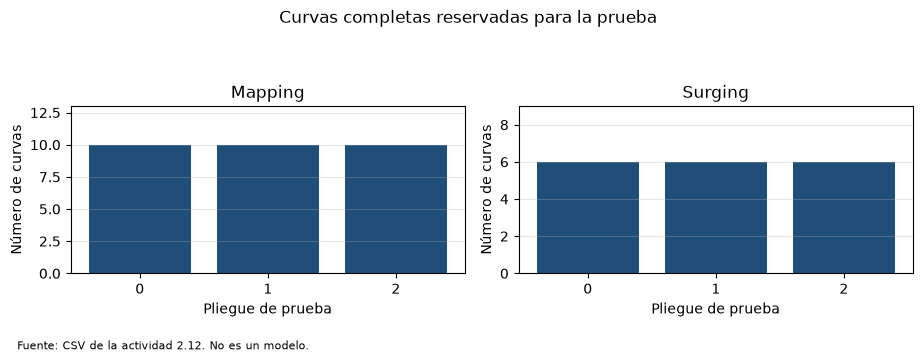

In [6]:
agua = curvas_m.loc[curvas_m["condicion"].eq("Single Phase"), ["hoja", "velocidad_rpm", "pliegue"]]
agua = agua.rename(columns={"pliegue": "pliegue_agua"})
gas = curvas_m.loc[~curvas_m["condicion"].eq("Single Phase")].merge(agua, on=["hoja", "velocidad_rpm"])
if (gas["pliegue"] == gas["pliegue_agua"]).any():
    raise RuntimeError("Gas y agua de la misma hoja y velocidad cayeron en el mismo pliegue.")

conteos = []
for pliegue in range(3):
    prueba = gas[gas["pliegue"].eq(pliegue)]
    entreno = gas[~gas["pliegue"].eq(pliegue)]
    conteos.append(
        {
            "pliegue_de_prueba": pliegue,
            "curvas_con_gas_en_prueba": len(prueba),
            "su_agua_esta_en_entrenamiento": int((prueba["pliegue_agua"] != pliegue).sum()),
            "curvas_con_gas_en_entrenamiento": len(entreno),
            "su_agua_tambien_en_entrenamiento": int((entreno["pliegue_agua"] != pliegue).sum()),
        }
    )
display(pd.DataFrame(conteos))
display(Markdown(
    "Las 24 curvas con gas se predicen, en este diseño, con el agua de su hoja y velocidad "
    "dentro del entrenamiento. Para ajustar el cociente solo hay 8 de 16 curvas con gas cuya agua "
    "también está en el entrenamiento. Las otras 8 quedan fuera de ese ajuste, porque su agua es una curva de prueba. "
    "No se calculó ningún cociente."
))

fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.5))
for eje, curvas, titulo in ((ejes[0], curvas_m, "Mapping"), (ejes[1], curvas_s, "Surging")):
    cuenta = curvas.groupby("pliegue").size()
    eje.bar(cuenta.index.astype(str), cuenta.to_numpy(), color="#1f4e79")
    eje.set_xlabel("Pliegue de prueba")
    eje.set_ylabel("Número de curvas")
    eje.set_title(titulo)
    eje.set_ylim(0, float(cuenta.max()) + 3)
    eje.grid(True, axis="y", alpha=0.3)
fig.suptitle("Curvas completas reservadas para la prueba")
fig.text(0.01, 0.01, "Fuente: CSV de la actividad 2.12. No es un modelo.", fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 0.90))
plt.show()


## Cierre de la fase A

Queda comprobado en esta ejecución:

- 570 y 387 filas, 30 y 18 curvas, huellas iguales a las publicadas.
- Ninguna curva está en entrenamiento y en prueba a la vez, ni en el pliegue externo ni en el interno.
- Cada pliegue externo tiene 1800 y 3500 rpm, las tres presiones y todas las condiciones de su protocolo en ambos lados.
- El anillo interno hereda esa cobertura: 4 cortes de 5 curvas en mapping y 3 cortes de 4 curvas en surging.
- `qgd` sigue vacío en las 87 filas de agua. `origen_velocidad` no es predictor.
- La repetición solo con velocidad de celda usará 186 filas de `50psig`. Cambia el dominio: ya no hay tres presiones. No se ejecuta ahora.

En la fase A no se ajustó la recta, ni el polinomio, ni la recta por condición, ni el bosque, ni el cociente respecto del agua.

## Riesgos para la fase siguiente

- Los pliegues de mapping tienen 200, 192 y 178 filas. Un promedio por fila favorece a las curvas largas. La comparación principal debe promediar curvas.
- Qgd de 0,005 y de 0,015 solo existen a 1800 rpm. Llevar esa etiqueta a 3500 rpm sería extrapolación.
- La velocidad de mapping en 100 y 150 psig viene del diseño. Una conclusión sobre la velocidad tendrá que repetirse sin esas filas, sabiendo que entonces solo queda 50 psig.
- El cociente de agua no es todavía un competidor: el ajuste solo verá 8 curvas con gas por pliegue.
- Probar un Qgd completamente nuevo es otro diseño. Estos pliegues no lo hacen.

La fase B está autorizada y empieza en la sección 5. Estima la recta y el polinomio con cresta sobre estos mismos cortes.


## 4.6. Protocolo congelado

Esta sección cierra la fase A. No estima coeficientes.

**Alcance de la validación principal.** Se predice una curva nueva cuya velocidad, presión de separador y condición ya están en otras curvas del entrenamiento. Acertar ahí no demuestra extrapolación: no autoriza otra velocidad, otra presión ni una condición de gas que el entrenamiento no haya visto.

**Evaluación complementaria, no ejecutada.** Se puede reservar después todas las curvas de una misma etiqueta. En mapping la etiqueta es Qgd o el agua. En surging es la fracción de QBEP, no un tramo de GVF0: partir el GVF0 de una curva mezclaría entrenamiento y prueba. La recta de esa etiqueta no puede predecirla. Si el Qgd reservado está en el borde de los valores del archivo, un modelo numérico estaría extrapolando. Si está entre otros Qgd, todavía puede no existir en las dos velocidades: 0,015 solo está a 1800 rpm. Esa reserva no reemplaza los tres pliegues ni se corre ahora.

**Métrica principal, fijada antes de ver un error de la bomba.** Error absoluto medio en psi, con el mismo peso para cada curva de prueba. El promedio por fila queda como dato auxiliar, porque las curvas no tienen el mismo número de puntos.

**Complementarias.** Raíz del error cuadrático medio y sesgo, también en psi y con el mismo peso por curva. El sesgo es predicción menos medición.

**Comparación.** Los modelos se restan curva por curva, en los mismos pliegues externos. No se elige un ganador en esta fase. Sigue vigente la regla de la actividad 2.13: hace falta superar a la recta, sin un sesgo que cambie de signo entre velocidades o presiones, y en mapping la ventaja tiene que sobrevivir al quitar la velocidad asignada por el diseño.

**Agua y Qgd.** El CSV conserva el vacío. El indicador `es_monofasica` dice que la fila es agua. Dentro del pipeline, y solo ahí, `qgd_tecnico` pone un cero en esas filas para que la matriz numérica sea finita. Ese cero no es un caudal de gas medido y no se escribe en el archivo.

**Tipo de variable, para M1 y M2.** Caudal, Qgd técnico, velocidad y presión entran como números ordenados. No se crean columnas ficticias de velocidad ni de presión. La condición de mapping, y la fracción de QBEP en la recta por bloque, son factores. GVF0 sigue siendo continuo.

**Congelación.** La versión del protocolo es `2.14-A`. Los pliegues externos, el anillo interno, el alcance, las métricas y el tratamiento de Qgd quedan fijos antes del primer entrenamiento. Un cambio posterior es una modificación metodológica: hay que anotar por qué se hace y qué comparaciones dejan de valer.


In [7]:
from esp_datascience.metricas import error_absoluto_medio, media_por_curva
from esp_datascience.particiones import auditar_particiones, qgd_tecnico
from esp_datascience.protocolo import (
    ALCANCE,
    COMPARACION,
    CONGELADO,
    METRICA_PRINCIPAL,
    TRATAMIENTO,
    VERSION,
    condiciones_no_vistas,
    huella_pliegues,
)

informe_mapping = auditar_particiones(mapping, "mapping", 4)
informe_surging = auditar_particiones(surging, "surging", 3)
print("Versión congelada:", VERSION, "congelado:", CONGELADO)
print("Auditoría mapping:", informe_mapping)
print("Auditoría surging:", informe_surging)
print("Huella mapping:", huella_pliegues(mapping, "mapping"))
print("Huella surging:", huella_pliegues(surging, "surging"))
print("Alcance:", ALCANCE)
print("Métrica principal:", METRICA_PRINCIPAL)
print("Comparación:", COMPARACION)

ausencias = int(mapping["qgd"].isna().sum())
tecnico = qgd_tecnico(mapping["qgd"], mapping["condicion"].eq("Single Phase"))
if int(mapping["qgd"].isna().sum()) != ausencias:
    raise RuntimeError("qgd_tecnico modificó el dato original.")
print("Qgd ausente en el CSV:", ausencias, "ceros solo en la copia técnica:", int((tecnico == 0).sum()))

ejemplo_filas = error_absoluto_medio([0.0, 0.0, 0.0], [10.0, 0.0, 0.0])
ejemplo_curvas = media_por_curva([0.0, 0.0, 0.0], [10.0, 0.0, 0.0], ["a", "b", "b"], error_absoluto_medio)
print(f"Ejemplo didáctico, no es la bomba: MAE por fila {ejemplo_filas:.3f} psi; MAE por curva {ejemplo_curvas:.1f} psi.")

display(condiciones_no_vistas(mapping, "mapping"))
display(condiciones_no_vistas(surging, "surging"))
print("Tratamiento mapping:", TRATAMIENTO["mapping"])
print("Tratamiento surging:", TRATAMIENTO["surging"])
print("Ninguna etiqueta no vista fue ejecutada. No hay modelo ajustado.")


Versión congelada: 2.14-A congelado: True
Auditoría mapping: {'protocolo': 'mapping', 'n_curvas': 30, 'n_pliegues': 3, 'sin_fuga': True, 'reproducible': True, 'dominio_en_cada_pliegue': True}
Auditoría surging: {'protocolo': 'surging', 'n_curvas': 18, 'n_pliegues': 3, 'sin_fuga': True, 'reproducible': True, 'dominio_en_cada_pliegue': True}
Huella mapping: f35be865a01a6255cc08afdccb96863184ad394a550d9a5249d42b4041a8d948
Huella surging: 71c4818c4b3a5bce0d363c5df658e04141ce1c1301e72f754d5805a52c9dc742
Alcance: Predicción de curvas nuevas dentro del dominio ya medido: la velocidad, la presión del separador y la condición de la curva de prueba aparecen en otras curvas del entrenamiento. No demuestra que el modelo valga en una velocidad, una presión o una condición de gas que el entrenamiento no vio.
Métrica principal: MAE en psi, media no ponderada del MAE de cada curva de prueba
Comparación: pareada, sobre los mismos pliegues externos
Qgd ausente en el CSV: 87 ceros solo en la copia técnic

,protocolo,etiqueta_reservada,n_curvas,velocidades,hojas,que_probaria,posicion_numerica,la_recta_por_etiqueta_puede_predecirla,es_la_evaluacion_principal,ejecutada
0,mapping,Qgd=0.005,3,[1800],"[100psig, 150psig, 50psig]",condición de gas no vista,en el borde de los valores del archivo,False,False,False
1,mapping,Qgd=0.01,6,"[1800, 3500]","[100psig, 150psig, 50psig]",condición de gas no vista,entre otros valores del archivo,False,False,False
2,mapping,Qgd=0.015,3,[1800],"[100psig, 150psig, 50psig]",condición de gas no vista,entre otros valores del archivo,False,False,False
3,mapping,Qgd=0.02,3,[3500],"[100psig, 150psig, 50psig]",condición de gas no vista,entre otros valores del archivo,False,False,False
4,mapping,Qgd=0.03,3,[3500],"[100psig, 150psig, 50psig]",condición de gas no vista,entre otros valores del archivo,False,False,False
5,mapping,Qgd=0.04,3,[3500],"[100psig, 150psig, 50psig]",condición de gas no vista,entre otros valores del archivo,False,False,False
6,mapping,Qgd=0.05,3,[3500],"[100psig, 150psig, 50psig]",condición de gas no vista,en el borde de los valores del archivo,False,False,False
7,mapping,Single Phase,6,"[1800, 3500]","[100psig, 150psig, 50psig]",condición de gas no vista,sin valor numérico de gas,False,False,False


,protocolo,etiqueta_reservada,n_curvas,velocidades,hojas,que_probaria,posicion_numerica,la_recta_por_etiqueta_puede_predecirla,es_la_evaluacion_principal,ejecutada
0,surging,0.75Qbep,6,"[1800, 3500]","[100psig, 150psig, 50psig]",fracción de QBEP no vista; no es un GVF0 no visto,en el borde de los valores del archivo,False,False,False
1,surging,1.25Qbep,6,"[1800, 3500]","[100psig, 150psig, 50psig]",fracción de QBEP no vista; no es un GVF0 no visto,en el borde de los valores del archivo,False,False,False
2,surging,Qbep,6,"[1800, 3500]","[100psig, 150psig, 50psig]",fracción de QBEP no vista; no es un GVF0 no visto,entre otros valores del archivo,False,False,False


Tratamiento mapping: {'ql_bpd': 'numérica, caudal de líquido en bpd', 'es_monofasica': 'indicador de agua; no es una medición de gas', 'qgd': 'numérica y ausente en agua; el CSV no se rellena', 'qgd_tecnico': 'cero solo dentro del pipeline cuando es agua; no es un Qgd medido', 'velocidad_rpm': 'numérica ordenada, 1800 o 3500; no se parte en variables ficticias', 'psep_psig': 'numérica ordenada, 50, 100 o 150; no se parte en variables ficticias', 'condicion': 'categórica, solo para la recta por condición'}
Tratamiento surging: {'gvf0_porcentaje': 'numérica continua; es el gas', 'fraccion_qbep': 'numérica ordenada en M1 y M2; factor en la recta por bloque', 'velocidad_rpm': 'numérica ordenada, 1800 o 3500', 'psep_psig': 'numérica ordenada, 50, 100 o 150'}
Ninguna etiqueta no vista fue ejecutada. No hay modelo ajustado.


## 5. Fase B. Fundamentos matemáticos

La fase A queda como estaba: versión `2.14-A`, mismas huellas y misma métrica. Esta fase estima solo dos modelos. Mapping y surging no se juntan. No entran la recta por condición, el bosque ni el cociente respecto del agua.

La variable objetivo es `dp2_3_psi`. Se interpreta como el incremento de presión de la etapa 3, en psi, con la certeza media del diccionario: la toma corresponde a la etapa 3 y los números están en ese orden de magnitud, pero el rótulo `DP2-3` no aparece en la tesis ni en los artículos. No es la presión absoluta.

**Hipótesis.** Sirven para orientar la comparación. No implican, por sí solas, una prueba de significación.

- **H0.** M2 no mejora el error absoluto medio de predicción respecto de M1.
- **H1.** M2 reduce el error absoluto medio respecto de M1 sobre curvas independientes.

La cifra que se compara es el MAE en psi, con el mismo peso para cada curva de prueba. La diferencia pareada es

ΔMAE = MAE(M2) − MAE(M1).

Un valor negativo indica que, en esa curva, el polinomio con cresta se equivocó menos que la recta. Las hipótesis de la sección 4.2 sobre el bosque y sobre el cociente de agua siguen abiertas: esos modelos no se estiman aquí.

**M1, regresión lineal.** Con los predictores x1…xp,

ŷ = β0 + β1 x1 + … + βp xp.

ŷ es el incremento de presión predicho, en psi. β0 es el intercepto: el valor de ŷ cuando todos los predictores valen cero. Ese punto no ocurre en el ensayo, así que β0 no es una medición. βj es el cambio de ŷ, en psi, asociado a aumentar una unidad de xj con los demás predictores fijos. El residuo de cada fila es predicción menos medición. Si es positivo, el modelo queda por encima del dato.

En mapping los predictores son el caudal de líquido (bpd), el indicador de agua, el Qgd técnico, la velocidad (rpm) y la presión del separador (psig). En surging son GVF0 (porcentaje), la fracción de QBEP, la velocidad y la presión del separador. No se usan el identificador de curva, la fila, el nombre del archivo ni `origen_velocidad`.

La limitación es de forma. Una curva hidráulica puede cambiar de pendiente al pasar de un régimen a otro. Una sola recta deja ese cambio dentro del residuo.

**M2, polinomio de grado 2 con cresta.** El grado se fijó en 2 en la actividad 2.13, antes de ver el error de estas curvas. A los predictores se les añaden los cuadrados y los productos dos a dos. Después, cada término se centra y se escala con la media y la desviación del entrenamiento de ese pliegue. La predicción sigue siendo una combinación lineal, pero de esos términos transformados:

ŷ = β0 + Σ βj zj.

La cresta añade a la suma de residuos al cuadrado una penalización alpha por la suma de βj². El intercepto no se penaliza. Alpha grande encoge los coeficientes hacia cero. Alpha se elige solo con las curvas de entrenamiento, en el anillo interno. Los coeficientes resultantes no se leen como una ley de la etapa: están en el espacio escalado del polinomio, y el cuadrado de un indicador 0/1 repite a ese indicador.


## 6. Diseño del entrenamiento

Para cada protocolo, y para cada uno de los tres pliegues externos:

1. Se reservan las curvas de prueba de ese pliegue.
2. M1 se ajusta solo con las curvas restantes.
3. Para M2, alpha se elige entre 0,01, 0,1, 1, 10 y 100. En cada candidato se recorren los cortes internos de la fase A y se promedia el MAE de las curvas internas, con igual peso por curva. Si dos alphas empatan a menos de 10⁻⁹ psi, se conserva el mayor. Ese empate es numérico, no una regla nueva de superioridad.
4. El M2 de ese pliegue se vuelve a ajustar con todo el entrenamiento externo y con el alpha ya elegido.
5. Se predicen solo las curvas del pliegue externo.
6. Se repite hasta que cada curva haya sido prueba una vez.

El orden de M2 es fijo: preparar las entradas, expandir el polinomio, quitar la columna idénticamente nula, escalar y ajustar la cresta. La media y la desviación salen del entrenamiento de ese ajuste, nunca de la prueba externa. En mapping, preparar copia `qgd` y pone cero solo donde el indicador de agua es verdadero. El CSV no se rellena y ese cero no es un Qgd medido.

El error de entrenamiento se guarda aparte. No se usa para elegir el modelo ni para elegir alpha.


In [8]:
from esp_datascience.entrenamiento import (
    ALPHAS,
    GRADO_POLINOMIO,
    ORDEN_M1,
    ORDEN_M2,
    pipeline_m1,
    pipeline_m2,
)
from esp_datascience.protocolo import VERSION, huella_pliegues

if VERSION != "2.14-A":
    raise RuntimeError(VERSION)
for nombre, tabla, huella in (
    ("mapping", mapping, "f35be865a01a6255cc08afdccb96863184ad394a550d9a5249d42b4041a8d948"),
    ("surging", surging, "71c4818c4b3a5bce0d363c5df658e04141ce1c1301e72f754d5805a52c9dc742"),
):
    if huella_pliegues(tabla, nombre) != huella:
        raise RuntimeError(nombre)
print("Versión", VERSION)
print("Grado del polinomio, fijado antes del error externo:", GRADO_POLINOMIO)
print("Rejilla de alpha, fijada antes del error externo:", ALPHAS)
print("Orden M1:", ORDEN_M1)
print("Orden M2:", ORDEN_M2)
print("Pasos M1 mapping:", list(pipeline_m1("mapping").named_steps))
print("Pasos M2 mapping:", list(pipeline_m2("mapping", 1.0).named_steps))
print("Qgd ausente en el CSV:", int(mapping["qgd"].isna().sum()))
print("Aún no se ha usado la prueba externa para elegir alpha.")


Versión 2.14-A
Grado del polinomio, fijado antes del error externo: 2
Rejilla de alpha, fijada antes del error externo: (0.01, 0.1, 1.0, 10.0, 100.0)
Orden M1: ('preparar', 'linea')
Orden M2: ('preparar', 'polinomio', 'columnas_estructurales', 'escala', 'cresta')
Pasos M1 mapping: ['preparar', 'linea']
Pasos M2 mapping: ['preparar', 'polinomio', 'columnas_estructurales', 'escala', 'cresta']
Qgd ausente en el CSV: 87
Aún no se ha usado la prueba externa para elegir alpha.


## 7. Implementación de M1

El pipeline de M1 tiene dos pasos. El primero arma la matriz numérica. El segundo es la regresión lineal de scikit-learn, sin penalización y sin escalar: así cada coeficiente queda en psi por unidad del predictor.

En mapping la matriz lleva `ql_bpd`, `es_monofasica`, `qgd_tecnico`, `velocidad_rpm` y `psep_psig`. `qgd_tecnico` vale 0 en el agua y el Qgd medido en el gas. El indicador distingue el agua; el cero técnico solo evita un hueco en la matriz. En surging la matriz lleva `gvf0_porcentaje`, `fraccion_qbep`, `velocidad_rpm` y `psep_psig`. GVF0 sigue en porcentaje, como en el archivo. La fracción de QBEP entra como número ordenado, 0,75, 1 y 1,25, no como tres columnas ficticias.

Los coeficientes se estiman de nuevo en cada pliegue. No hay un único vector β para todo el archivo.


## 8. Implementación de M2

El pipeline de M2 usa las mismas entradas que M1. Después:

1. `PolynomialFeatures` de grado 2, sin columna de unos. El intercepto lo pone la cresta.
2. Se elimina la columna que no varía en el entrenamiento. En mapping es el producto del indicador de agua por el Qgd técnico, que es cero por la forma en que se codificó el agua. En surging no se elimina ninguna. Si apareciera otra columna nula, el ajuste se detiene.
3. `StandardScaler` resta la media y divide por la desviación de las filas con las que se está ajustando ese pipeline. Hace falta porque el caudal al cuadrado y el Qgd al cuadrado no tienen la misma escala, y la penalización trataría distinto a esos coeficientes si no se escalan.
4. `Ridge` con solucionador SVD, determinista también cuando el polinomio deja columnas repetidas. El cuadrado del indicador 0/1 es una de esas repeticiones. Por eso un coeficiente suelto de M2 no se interpreta como un efecto físico.

Alpha no entra al pipeline hasta que el anillo interno lo eligió.


## 9. Validación anidada

La celda siguiente ajusta M1 y M2 en los tres pliegues. Cada predicción externa sale de un modelo que no vio esa curva. La tabla de búsqueda muestra el MAE interno de cada alpha. La tabla de entrenamiento no es el resultado de generalización: es el error del mismo pliegue sobre las curvas que sí entraron al ajuste.


In [9]:
from esp_datascience.entrenamiento import evaluar_protocolo
from esp_datascience.rutas import huella_sha256

resultado_mapping = evaluar_protocolo(mapping, "mapping")
resultado_surging = evaluar_protocolo(surging, "surging")
resultados = [resultado_mapping, resultado_surging]

if int(mapping["qgd"].isna().sum()) != 87:
    raise RuntimeError("El entrenamiento modificó el Qgd del agua.")
for relativo, esperada in HUELLAS.items():
    if huella_sha256(RAIZ / relativo) != esperada:
        raise RuntimeError(relativo)
for resultado, n_filas in ((resultado_mapping, 570), (resultado_surging, 387)):
    pred = resultado["predicciones"]
    if len(pred) != n_filas or pred[["prediccion_m1", "prediccion_m2"]].isna().any().any():
        raise RuntimeError(resultado["protocolo"])
    if resultado["huella"] not in {
        "f35be865a01a6255cc08afdccb96863184ad394a550d9a5249d42b4041a8d948",
        "71c4818c4b3a5bce0d363c5df658e04141ce1c1301e72f754d5805a52c9dc742",
    }:
        raise RuntimeError(resultado["huella"])
    print("Protocolo", resultado["protocolo"], "huella", resultado["huella"])
    display(resultado["alphas"])
    display(resultado["busqueda_alpha"])
    display(resultado["entrenamiento"])
print("Cada fila tiene una predicción externa de M1 y otra de M2.")


Protocolo mapping huella f35be865a01a6255cc08afdccb96863184ad394a550d9a5249d42b4041a8d948


,pliegue,alpha,n_filas_entrenamiento,n_filas_prueba
0,0,0.1,370,200
1,1,0.1,378,192
2,2,0.1,392,178


,pliegue_externo,alpha,mae_interno_por_curva
0,0,0.01,1.459347
1,0,0.10,1.439828
2,0,1.00,1.588130
3,0,10.00,2.549486
4,0,100.00,4.184284
5,1,0.01,1.517718
6,1,0.10,1.494273
7,1,1.00,1.545110
8,1,10.00,2.417286
9,1,100.00,4.135150


,pliegue,modelo,mae_curva_entrenamiento,mae_curva_externo
0,0,M1,4.058656,3.968141
1,0,M2,1.291070,1.296274
2,1,M1,3.950972,4.103291
3,1,M2,1.270784,1.350633
4,2,M1,3.986484,3.924531
5,2,M2,1.252141,1.445685


Protocolo surging huella 71c4818c4b3a5bce0d363c5df658e04141ce1c1301e72f754d5805a52c9dc742


,pliegue,alpha,n_filas_entrenamiento,n_filas_prueba
0,0,0.01,257,130
1,1,1.00,255,132
2,2,0.01,262,125


,pliegue_externo,alpha,mae_interno_por_curva
0,0,0.01,1.986948
1,0,0.10,2.345161
2,0,1.00,2.529433
3,0,10.00,2.386230
4,0,100.00,2.727743
5,1,0.01,2.484472
6,1,0.10,2.128188
7,1,1.00,2.081861
8,1,10.00,2.621126
9,1,100.00,2.795997


,pliegue,modelo,mae_curva_entrenamiento,mae_curva_externo
0,0,M1,2.191242,2.467544
1,0,M2,0.702385,1.335276
2,1,M1,2.414974,2.189921
3,1,M2,0.989647,0.985922
4,2,M1,2.315380,2.279744
5,2,M2,0.802248,1.019996


Cada fila tiene una predicción externa de M1 y otra de M2.


## 10. Resultados de mapping

El MAE por curva es la métrica principal. El MAE por fila es secundario, porque las curvas no tienen el mismo número de puntos. RMSE y sesgo también pesan igual a cada curva. El sesgo es predicción menos medición. R² se calcula sobre las observaciones externas juntas, así que las curvas largas pesan más: no es la cifra con la que se compara.


In [10]:
print("Métricas externas de mapping")
display(resultado_mapping["externo"])
print("Diferencia pareada, M2 menos M1. Negativo: M2 tiene menor MAE en esa curva.")
display(resultado_mapping["diferencias"].sort_values("delta_mae"))
print("Error por velocidad, presión y condición")
display(resultado_mapping["desglose"])
print("Coeficientes de M1 por pliegue, en las unidades de cada predictor. No son una ley de afinidad.")
display(resultado_mapping["coeficientes_m1"])


Métricas externas de mapping


,protocolo,modelo,mae_fila,mae_curva,rmse_curva,rmse_fila,sesgo_curva,sesgo_fila,r2_observaciones
0,mapping,M1,4.381772,3.998655,4.865071,5.929712,0.042785,-0.006919,0.542993
1,mapping,M2,1.462404,1.364197,1.707243,2.153970,0.025131,0.003661,0.939698


Diferencia pareada, M2 menos M1. Negativo: M2 tiene menor MAE en esa curva.


,curva_id,pliegue,hoja,condicion,velocidad_rpm,psep_psig,n_puntos,mae_m1,mae_m2,delta_mae
14,150psig|3500|Qgd=0.01,1,150psig,Qgd=0.01,3500,150.0,20,7.666228,2.527469,-5.138759
17,150psig|3500|Qgd=0.04,2,150psig,Qgd=0.04,3500,150.0,21,6.132675,1.121091,-5.011584
6,100psig|3500|Qgd=0.03,0,100psig,Qgd=0.03,3500,100.0,22,6.717696,1.798625,-4.919072
26,50psig|3500|Qgd=0.03,2,50psig,Qgd=0.03,3500,50.0,21,6.283382,1.659756,-4.623626
7,100psig|3500|Qgd=0.04,1,100psig,Qgd=0.04,3500,100.0,20,5.606117,1.073747,-4.532370
4,100psig|3500|Qgd=0.01,0,100psig,Qgd=0.01,3500,100.0,30,6.734011,2.340270,-4.393741
25,50psig|3500|Qgd=0.02,0,50psig,Qgd=0.02,3500,50.0,21,6.415210,2.102774,-4.312435
18,150psig|3500|Qgd=0.05,1,150psig,Qgd=0.05,3500,150.0,20,5.168078,0.922733,-4.245345
15,150psig|3500|Qgd=0.02,2,150psig,Qgd=0.02,3500,150.0,23,6.560539,2.476150,-4.084389
16,150psig|3500|Qgd=0.03,1,150psig,Qgd=0.03,3500,150.0,19,5.788870,1.748575,-4.040294


Error por velocidad, presión y condición


,modelo,factor,nivel,n_curvas,mae_curva,sesgo_curva
0,M1,velocidad_rpm,1800,12,1.429951,0.154186
1,M1,velocidad_rpm,3500,18,5.711124,-0.031482
2,M1,psep_psig,50.0,10,3.644188,0.001433
3,M1,psep_psig,100.0,10,3.981205,0.317991
4,M1,psep_psig,150.0,10,4.370571,-0.191067
5,M1,condicion,Qgd=0.005,3,1.398840,0.326856
6,M1,condicion,Qgd=0.01,6,4.301312,0.587550
7,M1,condicion,Qgd=0.015,3,1.679374,-0.685761
8,M1,condicion,Qgd=0.02,3,6.198847,-1.224613
9,M1,condicion,Qgd=0.03,3,6.263316,-0.391546


Coeficientes de M1 por pliegue, en las unidades de cada predictor. No son una ley de afinidad.


,pliegue,intercepto_psi,ql_bpd,es_monofasica,qgd_tecnico,velocidad_rpm,psep_psig
0,0,-8.419741,-0.002343,0.901978,-188.516999,0.010100,-0.010754
1,1,-7.766843,-0.002586,0.800414,-194.103456,0.010235,-0.014277
2,2,-8.286303,-0.002617,0.989241,-183.689945,0.010305,-0.011314


## 11. Resultados de surging

La misma lectura que en mapping. GVF0 es el gas continuo. La fracción de QBEP es el bloque de líquido, no un GVF.


In [11]:
print("Métricas externas de surging")
display(resultado_surging["externo"])
print("Diferencia pareada, M2 menos M1.")
display(resultado_surging["diferencias"].sort_values("delta_mae"))
print("Error por velocidad, presión y condición")
display(resultado_surging["desglose"])
print("Coeficientes de M1 por pliegue.")
display(resultado_surging["coeficientes_m1"])


Métricas externas de surging


,protocolo,modelo,mae_fila,mae_curva,rmse_curva,rmse_fila,sesgo_curva,sesgo_fila,r2_observaciones
0,surging,M1,2.131530,2.312403,2.734172,2.708962,0.135745,-0.032534,0.894262
1,surging,M2,1.225031,1.113731,1.353299,1.632833,0.145525,0.019142,0.961584


Diferencia pareada, M2 menos M1.


,curva_id,pliegue,hoja,condicion,velocidad_rpm,psep_psig,n_puntos,mae_m1,mae_m2,delta_mae
0,100psig|1800|0.75Qbep,2,100psig,0.75Qbep,1800,100.0,10,3.854556,0.476556,-3.378000
6,150psig|1800|0.75Qbep,1,150psig,0.75Qbep,1800,150.0,20,4.354352,1.349032,-3.005320
12,50psig|1800|0.75Qbep,0,50psig,0.75Qbep,1800,50.0,8,4.151365,1.688290,-2.463075
1,100psig|1800|1.25Qbep,1,100psig,1.25Qbep,1800,100.0,12,2.809861,0.357048,-2.452813
8,150psig|1800|Qbep,2,150psig,Qbep,1800,150.0,16,2.362864,0.720940,-1.641924
7,150psig|1800|1.25Qbep,0,150psig,1.25Qbep,1800,150.0,13,2.363985,0.910673,-1.453312
2,100psig|1800|Qbep,0,100psig,Qbep,1800,100.0,14,1.638713,0.289341,-1.349372
16,50psig|3500|1.25Qbep,2,50psig,1.25Qbep,3500,50.0,27,2.298124,1.281033,-1.017091
13,50psig|1800|1.25Qbep,2,50psig,1.25Qbep,1800,50.0,14,2.016697,1.106651,-0.910045
14,50psig|1800|Qbep,1,50psig,Qbep,1800,50.0,16,1.727970,0.834621,-0.893349


Error por velocidad, presión y condición


,modelo,factor,nivel,n_curvas,mae_curva,sesgo_curva
0,M1,velocidad_rpm,1800,9,2.808929,0.180933
1,M1,velocidad_rpm,3500,9,1.815877,0.090557
2,M1,psep_psig,50.0,6,2.404608,0.345788
3,M1,psep_psig,100.0,6,2.335831,-0.000727
4,M1,psep_psig,150.0,6,2.196770,0.062174
5,M1,condicion,0.75Qbep,6,2.930588,1.207394
6,M1,condicion,1.25Qbep,6,2.101026,-0.102878
7,M1,condicion,Qbep,6,1.905595,-0.697281
8,M2,velocidad_rpm,1800,9,0.859239,0.116776
9,M2,velocidad_rpm,3500,9,1.368224,0.174274


Coeficientes de M1 por pliegue.


,pliegue,intercepto_psi,gvf0_porcentaje,fraccion_qbep,velocidad_rpm,psep_psig
0,0,13.715085,-1.168241,-17.337699,0.007374,0.008783
1,1,14.209115,-1.265482,-18.385173,0.007676,0.012014
2,2,14.390886,-1.197078,-17.643966,0.007569,0.003173


## 12. Comparación de errores

La tabla junta los dos protocolos. No declara un ganador de la actividad 2.14. La sección 15 dice qué se puede sostener con estas cifras y qué queda para la fase D.


In [12]:
from esp_datascience.entrenamiento import tabla_comparativa

comparacion = tabla_comparativa(resultados)
display(comparacion)
prosa = {("mapping", "M1"): 3.999, ("mapping", "M2"): 1.364, ("surging", "M1"): 2.312, ("surging", "M2"): 1.114}
for _, fila in comparacion.iterrows():
    obtenido = round(float(fila["mae_curva"]), 3)
    esperado = prosa[(fila["protocolo"], fila["modelo"])]
    if obtenido != esperado:
        raise RuntimeError((fila["protocolo"], fila["modelo"], obtenido, esperado))
for resultado in resultados:
    delta = resultado["diferencias"]["delta_mae"]
    print(
        resultado["protocolo"],
        "media de ΔMAE",
        float(delta.mean()),
        "mediana",
        float(delta.median()),
        "mínimo",
        float(delta.min()),
        "máximo",
        float(delta.max()),
        "curvas con ΔMAE negativo",
        int((delta < 0).sum()),
        "de",
        int(len(delta)),
    )


,protocolo,modelo,mae_curva,rmse_curva,sesgo_curva,r2_observaciones,mae_fila
0,mapping,M1,3.998655,4.865071,0.042785,0.542993,4.381772
1,mapping,M2,1.364197,1.707243,0.025131,0.939698,1.462404
2,surging,M1,2.312403,2.734172,0.135745,0.894262,2.131530
3,surging,M2,1.113731,1.353299,0.145525,0.961584,1.225031


mapping media de ΔMAE -2.634457258741763 mediana -2.883006023585494 mínimo -5.13875915349703 máximo 0.4509097667084707 curvas con ΔMAE negativo 29 de 30
surging media de ΔMAE -1.1986714385431698 mediana -0.9016972122578278 mínimo -3.3779995961349614 máximo 0.26530232639753293 curvas con ΔMAE negativo 17 de 18


## 13. Gráficos

Cada punto de una predicción es el valor del modelo en una observación medida. La línea que une esas predicciones sigue el orden de la abscisa experimental. No es un suavizado. La recta y = medición y la línea de residuo cero son referencias visuales, no modelos.

Las curvas dibujadas se eligen con el MAE de M1, sin mirar si M2 gana: la más cercana a la mediana de M1 dentro de cada velocidad, y la de mayor MAE de M1 en el protocolo.


Curvas de la figura de mapping : {'100psig|1800|Qgd=0.005': ['cerca de la mediana de M1 a 1800 rpm'], '150psig|3500|Single Phase': ['cerca de la mediana de M1 a 3500 rpm'], '150psig|3500|Qgd=0.01': ['mayor MAE de M1']}


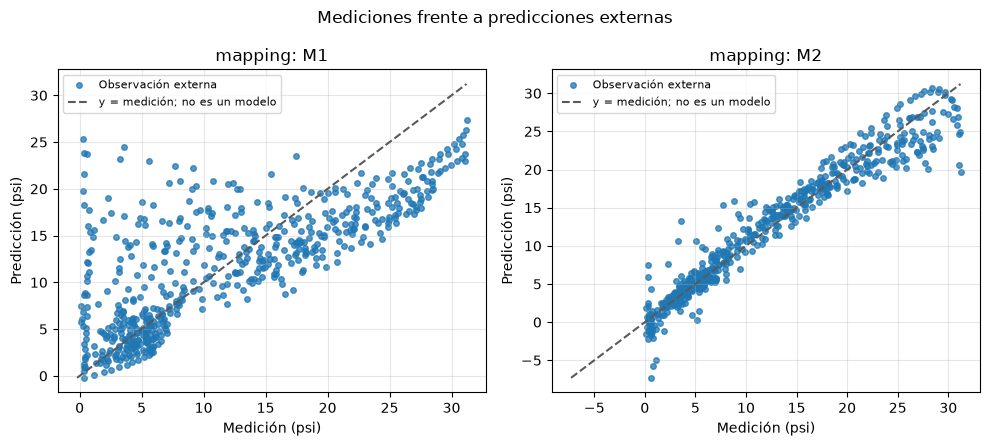

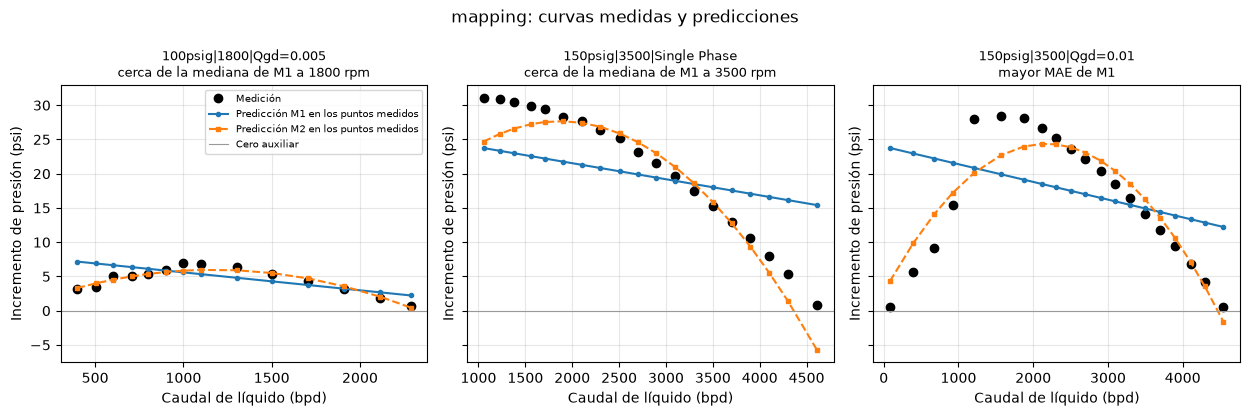

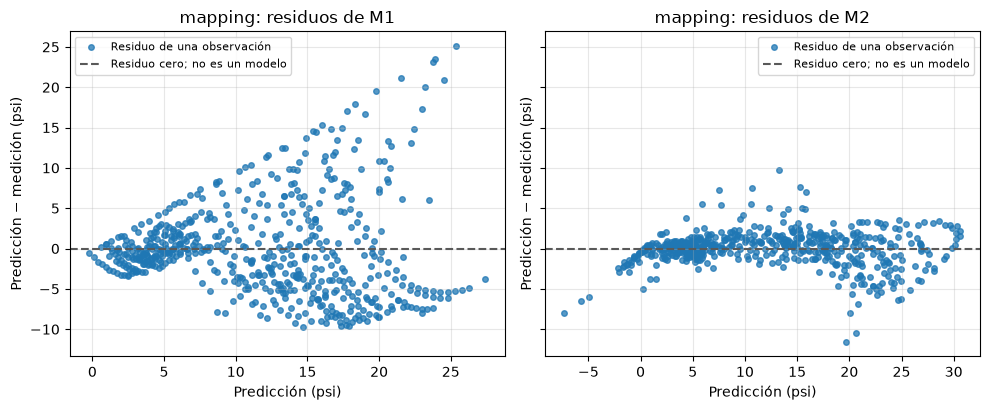

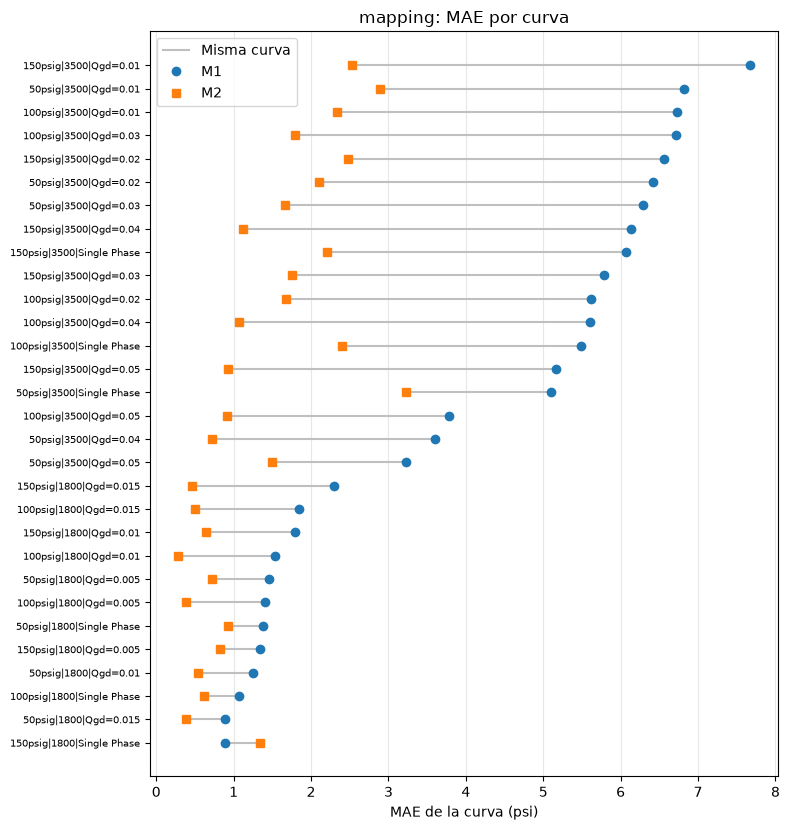

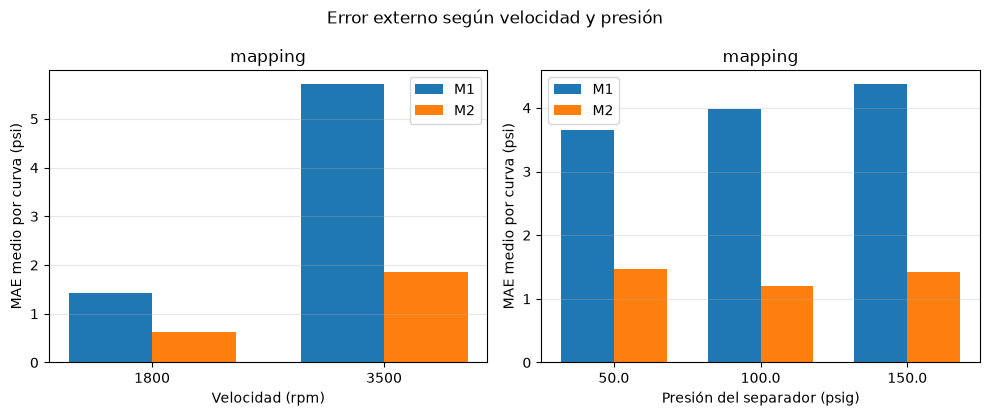

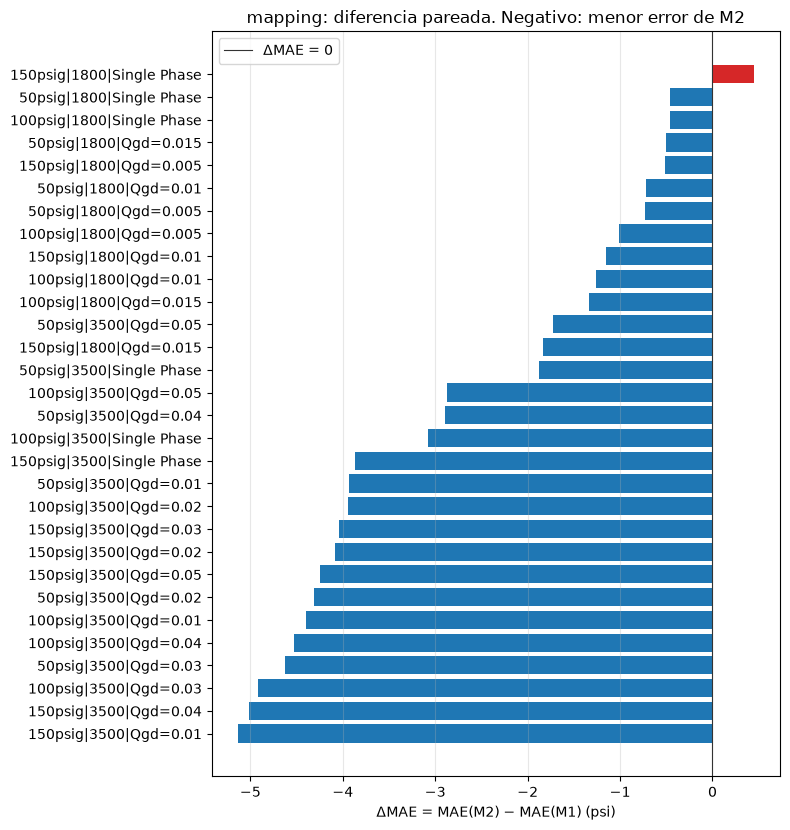

Curvas de la figura de surging : {'150psig|1800|1.25Qbep': ['cerca de la mediana de M1 a 1800 rpm'], '100psig|3500|0.75Qbep': ['cerca de la mediana de M1 a 3500 rpm'], '150psig|1800|0.75Qbep': ['mayor MAE de M1']}


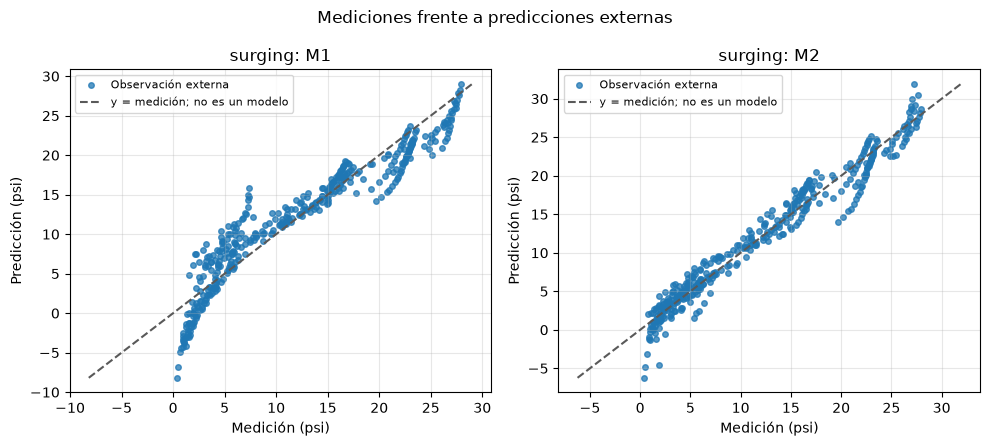

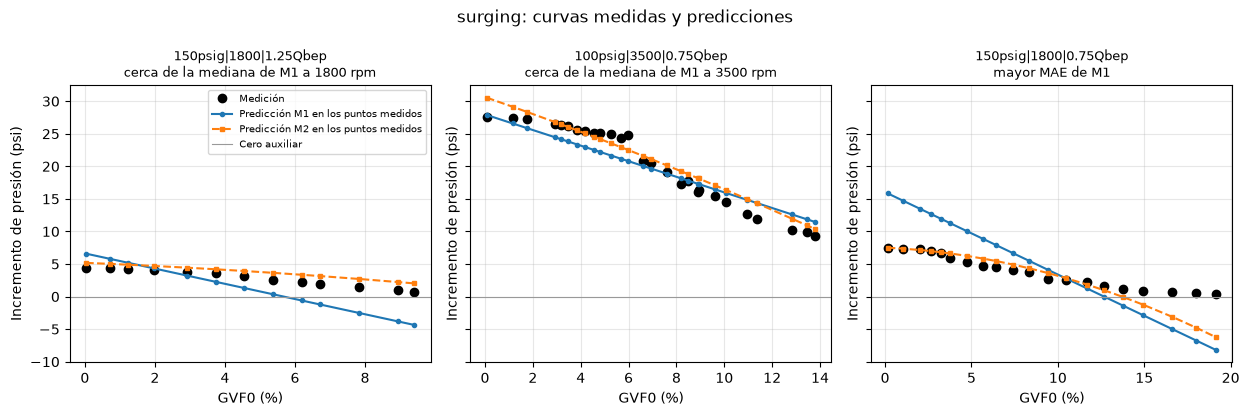

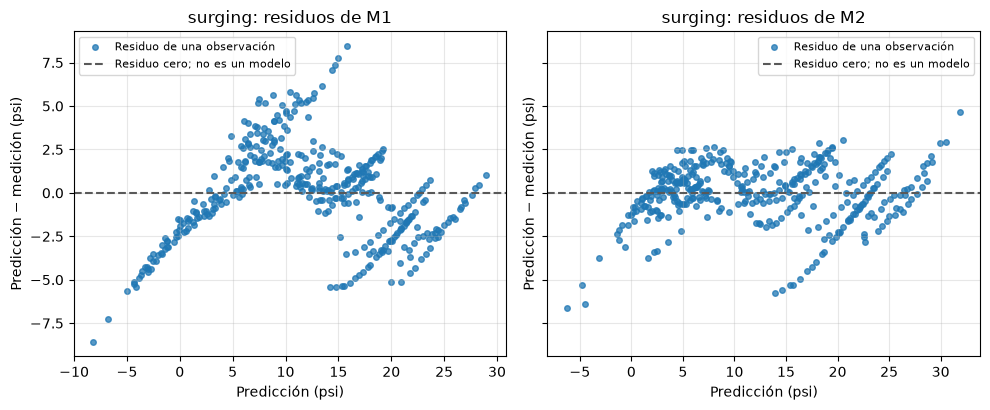

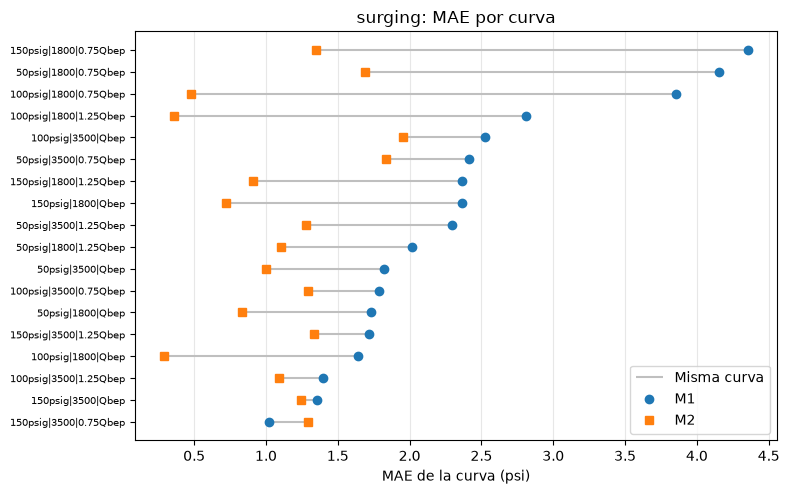

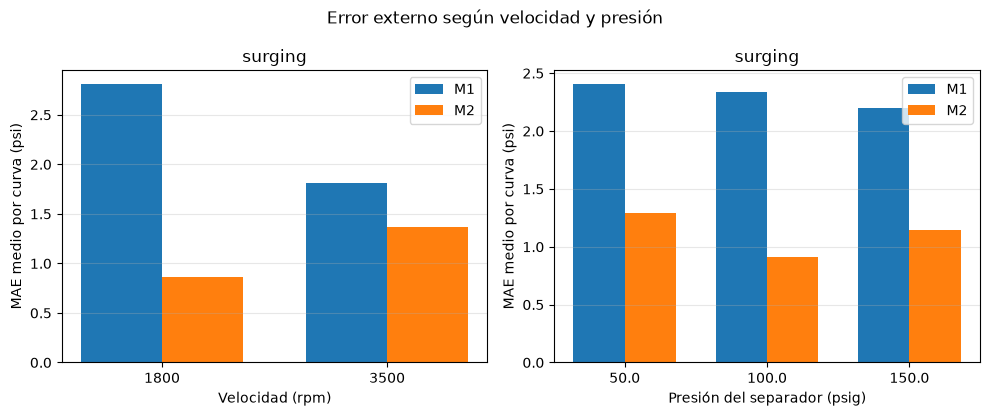

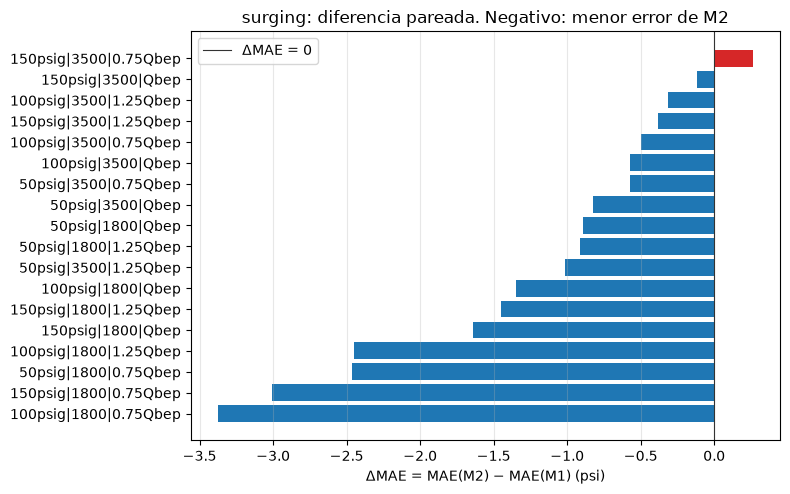

In [13]:
def curvas_de_figura(resultado):
    ejemplos = resultado["ejemplos"]
    papeles = {}
    for curva, texto in (
        (ejemplos["tipica_1800"], "cerca de la mediana de M1 a 1800 rpm"),
        (ejemplos["tipica_3500"], "cerca de la mediana de M1 a 3500 rpm"),
        (ejemplos["dificil"], "mayor MAE de M1"),
    ):
        papeles.setdefault(curva, []).append(texto)
    return papeles


def figura_medicion(pred, protocolo):
    fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5))
    for eje, columna, nombre in zip(ejes, ("prediccion_m1", "prediccion_m2"), ("M1", "M2"), strict=True):
        eje.scatter(pred["medicion"], pred[columna], s=16, alpha=0.75, label="Observación externa")
        inferior = min(pred["medicion"].min(), pred[columna].min())
        superior = max(pred["medicion"].max(), pred[columna].max())
        eje.plot([inferior, superior], [inferior, superior], color="0.35", ls="--", label="y = medición; no es un modelo")
        eje.set_xlabel("Medición (psi)")
        eje.set_ylabel("Predicción (psi)")
        eje.set_title(f"{protocolo}: {nombre}")
        eje.legend(fontsize=8)
        eje.grid(True, alpha=0.3)
    fig.suptitle("Mediciones frente a predicciones externas")
    fig.tight_layout()
    plt.show()


def figura_curvas(pred, protocolo, papeles):
    fig, ejes = plt.subplots(1, len(papeles), figsize=(4.2 * len(papeles), 4.2), sharey=True)
    if len(papeles) == 1:
        ejes = [ejes]
    for eje, (curva, roles) in zip(ejes, papeles.items(), strict=True):
        grupo = pred[pred["curva_id"].eq(curva)].sort_values("abscisa")
        eje.plot(grupo["abscisa"], grupo["medicion"], "o", color="black", label="Medición")
        eje.plot(grupo["abscisa"], grupo["prediccion_m1"], "-o", ms=3, label="Predicción M1 en los puntos medidos")
        eje.plot(grupo["abscisa"], grupo["prediccion_m2"], "--s", ms=3, label="Predicción M2 en los puntos medidos")
        eje.axhline(0.0, color="0.6", lw=0.8, label="Cero auxiliar")
        nombre = "Caudal de líquido (bpd)" if grupo["abscisa_nombre"].iloc[0] == "ql_bpd" else "GVF0 (%)"
        eje.set_xlabel(nombre)
        eje.set_ylabel("Incremento de presión (psi)")
        eje.set_title(curva + "\n" + "; ".join(roles), fontsize=9)
        eje.grid(True, alpha=0.3)
    ejes[0].legend(fontsize=7, loc="best")
    fig.suptitle(f"{protocolo}: curvas medidas y predicciones")
    fig.tight_layout()
    plt.show()


def figura_residuos(pred, protocolo):
    fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
    for eje, columna, nombre in zip(ejes, ("prediccion_m1", "prediccion_m2"), ("M1", "M2"), strict=True):
        residuo = pred[columna] - pred["medicion"]
        eje.scatter(pred[columna], residuo, s=16, alpha=0.75, label="Residuo de una observación")
        eje.axhline(0.0, color="0.35", ls="--", label="Residuo cero; no es un modelo")
        eje.set_xlabel("Predicción (psi)")
        eje.set_ylabel("Predicción − medición (psi)")
        eje.set_title(f"{protocolo}: residuos de {nombre}")
        eje.legend(fontsize=8)
        eje.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


def figura_mae(diferencias, protocolo):
    tabla = diferencias.sort_values("mae_m1")
    posicion = np.arange(len(tabla))
    fig, eje = plt.subplots(figsize=(8, max(4.5, 0.28 * len(tabla))))
    eje.hlines(posicion, tabla["mae_m1"], tabla["mae_m2"], color="0.75", label="Misma curva")
    eje.plot(tabla["mae_m1"], posicion, "o", label="M1")
    eje.plot(tabla["mae_m2"], posicion, "s", label="M2")
    eje.set_yticks(posicion, tabla["curva_id"], fontsize=7)
    eje.set_xlabel("MAE de la curva (psi)")
    eje.set_title(f"{protocolo}: MAE por curva")
    eje.legend()
    eje.grid(True, axis="x", alpha=0.3)
    fig.tight_layout()
    plt.show()


def figura_factores(desglose, protocolo):
    fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))
    for eje, factor, titulo in zip(
        ejes,
        ("velocidad_rpm", "psep_psig"),
        ("Velocidad (rpm)", "Presión del separador (psig)"),
        strict=True,
    ):
        sub = desglose[desglose["factor"].eq(factor)]
        niveles = list(sub["nivel"].drop_duplicates())
        ancho = 0.36
        lugares = np.arange(len(niveles))
        for desplazamiento, modelo in ((-ancho / 2, "M1"), (ancho / 2, "M2")):
            valores = [float(sub[(sub["nivel"].eq(nivel)) & (sub["modelo"].eq(modelo))]["mae_curva"].iloc[0]) for nivel in niveles]
            eje.bar(lugares + desplazamiento, valores, width=ancho, label=modelo)
        eje.set_xticks(lugares, [str(nivel) for nivel in niveles])
        eje.set_ylabel("MAE medio por curva (psi)")
        eje.set_xlabel(titulo)
        eje.set_title(protocolo)
        eje.legend()
        eje.grid(True, axis="y", alpha=0.3)
    fig.suptitle("Error externo según velocidad y presión")
    fig.tight_layout()
    plt.show()


def figura_delta(diferencias, protocolo):
    tabla = diferencias.sort_values("delta_mae")
    colores = ["C0" if valor < 0 else "C3" for valor in tabla["delta_mae"]]
    fig, eje = plt.subplots(figsize=(8, max(4.5, 0.28 * len(tabla))))
    eje.barh(tabla["curva_id"], tabla["delta_mae"], color=colores)
    eje.axvline(0.0, color="0.2", lw=0.8, label="ΔMAE = 0")
    eje.set_xlabel("ΔMAE = MAE(M2) − MAE(M1) (psi)")
    eje.set_title(f"{protocolo}: diferencia pareada. Negativo: menor error de M2")
    eje.legend()
    eje.grid(True, axis="x", alpha=0.3)
    fig.tight_layout()
    plt.show()


for resultado in resultados:
    nombre = resultado["protocolo"]
    print("Curvas de la figura de", nombre, ":", curvas_de_figura(resultado))
    figura_medicion(resultado["predicciones"], nombre)
    figura_curvas(resultado["predicciones"], nombre, curvas_de_figura(resultado))
    figura_residuos(resultado["predicciones"], nombre)
    figura_mae(resultado["diferencias"], nombre)
    figura_factores(resultado["desglose"], nombre)
    figura_delta(resultado["diferencias"], nombre)


## 14. Interpretación física

El objetivo sigue siendo el incremento de presión, no la presión absoluta. No se impuso una restricción de signo ni una ley de afinidad. Lo que sigue es una lectura de las predicciones externas, en los mismos caudales y GVF0 medidos. No hay extrapolación de la abscisa: cada predicción cae sobre una fila del archivo. Aun así, el polinomio puede tomar un valor que ninguna medición tomó.


In [14]:
for resultado in resultados:
    fisico = resultado["fisico"]
    print("Protocolo", resultado["protocolo"])
    print(
        "Predicciones negativas. M1:",
        fisico["predicciones_negativas_m1"],
        "M2:",
        fisico["predicciones_negativas_m2"],
        "Mediciones negativas:",
        fisico["mediciones_negativas"],
    )
    print(
        "Mínimo predicho M1 y M2, en psi:",
        round(fisico["min_prediccion_m1"], 3),
        round(fisico["min_prediccion_m2"], 3),
        "Mínimo medido:",
        round(fisico["min_medicion"], 3),
    )
    print("Media del incremento por curva, según la velocidad")
    display(fisico["media_por_velocidad"])
    display(fisico["gas"])
    if "agua" in fisico:
        print("Correlación de Spearman entre caudal y presión en las curvas de agua. −1 es estrictamente decreciente.")
        display(fisico["agua"])


Protocolo mapping
Predicciones negativas. M1: 1 M2: 22 Mediciones negativas: 0
Mínimo predicho M1 y M2, en psi: -0.207 -7.292 Mínimo medido: 0.08
Media del incremento por curva, según la velocidad


,medicion,m1,m2
velocidad_rpm,,,
1800,4.338018,4.492204,4.489418
3500,15.402572,15.371090,15.343524


,hoja,velocidad_rpm,modelo,pasos,pasos_en_que_sube
0,100psig,1800,medicion,2,0
1,100psig,1800,M1,2,0
2,100psig,1800,M2,2,0
3,100psig,3500,medicion,4,1
4,100psig,3500,M1,4,0
5,100psig,3500,M2,4,1
6,150psig,1800,medicion,2,0
7,150psig,1800,M1,2,0
8,150psig,1800,M2,2,0
9,150psig,3500,medicion,4,1


Correlación de Spearman entre caudal y presión en las curvas de agua. −1 es estrictamente decreciente.


,curva_id,n_puntos,spearman_medicion,subidas_medicion,mayor_subida_medicion,spearman_M1,subidas_M1,mayor_subida_M1,spearman_M2,subidas_M2,mayor_subida_M2
0,100psig|1800|Single Phase,9,-1.0,0,-0.269557,-1.0,0,-0.489121,-0.950000,1,0.251016
1,100psig|3500|Single Phase,18,-1.0,0,-0.484403,-1.0,0,-0.494830,-0.913313,3,1.020288
2,150psig|1800|Single Phase,10,-1.0,0,-0.238340,-1.0,0,-0.392268,-0.915152,2,0.440656
3,150psig|3500|Single Phase,19,-1.0,0,-0.222266,-1.0,0,-0.339617,-0.849123,5,1.104568
4,50psig|1800|Single Phase,10,-1.0,0,-0.147045,-1.0,0,-0.425852,-0.842424,2,0.620706
5,50psig|3500|Single Phase,21,-1.0,0,-0.063212,-1.0,0,-0.437035,-0.654545,7,5.247795


Protocolo surging
Predicciones negativas. M1: 34 M2: 12 Mediciones negativas: 0
Mínimo predicho M1 y M2, en psi: -8.184 -6.23 Mínimo medido: 0.383
Media del incremento por curva, según la velocidad


,medicion,m1,m2
velocidad_rpm,,,
1800,3.681496,3.862430,3.798273
3500,15.893378,15.983935,16.067652


,curva_id,n_puntos,medicion,M1,M2
0,100psig|1800|0.75Qbep,10,-1.000000,-1.0,-1.0
1,100psig|1800|1.25Qbep,12,-1.000000,-1.0,-1.0
2,100psig|1800|Qbep,14,-1.000000,-1.0,-1.0
3,100psig|3500|0.75Qbep,27,-0.997558,-1.0,-1.0
4,100psig|3500|1.25Qbep,24,-0.999130,-1.0,-1.0
5,100psig|3500|Qbep,42,-0.999676,-1.0,-1.0
6,150psig|1800|0.75Qbep,20,-1.000000,-1.0,-1.0
7,150psig|1800|1.25Qbep,13,-1.000000,-1.0,-1.0
8,150psig|1800|Qbep,16,-1.000000,-1.0,-1.0
9,150psig|3500|0.75Qbep,31,-0.998790,-1.0,-1.0


## 15. Discusión

En mapping, el MAE por curva pasa de 3,999 psi con M1 a 1,364 psi con M2. En surging, de 2,312 psi a 1,114 psi. RMSE por curva también baja: de 4,865 psi a 1,707 psi en mapping y de 2,734 psi a 1,353 psi en surging. El sesgo medio por curva queda cerca de cero en mapping (0,043 psi y 0,025 psi) y, en surging, casi no cambia (0,136 psi y 0,146 psi). R² sobre las filas externas sube de 0,543 a 0,940 en mapping y de 0,894 a 0,962 en surging. Esa última cifra da más peso a las curvas largas; no sustituye al MAE por curva.

La media de ΔMAE es −2,634 psi en mapping y −1,199 psi en surging. El signo es negativo en 29 de las 30 curvas de mapping y en 17 de las 18 de surging. No es una mejora de unas milésimas concentrada en una sola curva. Las dos excepciones son `150psig|1800|Single Phase`, donde M2 empeora 0,451 psi, y `150psig|3500|0.75Qbep`, donde empeora 0,265 psi.

Los errores más altos de M1 en mapping están en curvas de 3500 rpm con gas, en particular `150psig|3500|Qgd=0.01` (7,666 psi). M2 lo baja a 2,527 psi, y aun así esa zona sigue entre las difíciles. A 1800 rpm el MAE de M1 ya era menor (1,430 psi) que a 3500 rpm (5,711 psi). M2 reduce los dos, a 0,636 psi y 1,850 psi. En surging, M1 se equivoca más a 1800 rpm (2,809 psi) que a 3500 rpm (1,816 psi), sobre todo en el bloque 0,75 de QBEP. M2 invierte ese contraste: 0,859 psi a 1800 rpm y 1,368 psi a 3500 rpm.

No se ve un sobreajuste grande en mapping. El MAE de entrenamiento de M2, promediado entre los tres pliegues, queda en torno a 1,27 psi, y el externo es 1,364 psi. En surging el hueco es más visible en el pliegue 0: 0,702 psi de entrenamiento frente a 1,335 psi externos. El externo de ese pliegue sigue por debajo del M1 del mismo pliegue (2,468 psi). M1 no muestra ese hueco: su error de entrenamiento y su error externo se parecen.

Alpha no es el mismo objeto en los dos protocolos. En mapping los tres pliegues eligen 0,1, y el MAE interno de ese valor queda por debajo del de 0,01 y del de 1. En surging el pliegue 1 elige 1 y los otros dos eligen 0,01. La penalización sí cambia con el pliegue de surging. La rejilla tiene solo cinco valores, decididos antes de ver la prueba. No se afinó después.

El sesgo no es uniforme. En mapping, M1 y M2 quedan algo por encima de la medición a 1800 rpm y algo por debajo a 3500 rpm. Entre presiones, el signo también cambia. En surging el sesgo de los dos modelos es positivo en 0,75 de QBEP y negativo en el bloque QBEP. Bajó el error absoluto, no desapareció este patrón.

Con la regla de la actividad 2.13 haría falta, además, que el sesgo no cambiara de signo entre velocidades o presiones y que el resultado de mapping sobreviviera al quitar la velocidad asignada por el diseño. Esa repetición no se ejecutó: dejaría solo 50 psig. Tampoco se calculó una banda de incertidumbre de ΔMAE. Por eso el resultado es provisional. La fase D es el lugar de la conclusión definitiva, cuando estén los otros modelos de la actividad.


## 16. Limitaciones

- El dominio es el de las curvas medidas: TE-2700, agua y aire, sin isopropanol, 1800 y 3500 rpm, 50, 100 y 150 psig, y los Qgd o GVF0 que ya están en el archivo. Acertar una curva nueva dentro de ese dominio no demuestra otra velocidad, otra presión ni otra condición de gas.
- M2 predice incrementos negativos que el archivo no tiene: 22 filas en mapping, hasta −7,292 psi, y 12 en surging, hasta −6,230 psi. M1 también lo hace, una fila en mapping y 34 en surging. Esas filas están donde la medición ya es baja, cerca de 0,1 psi a 2,5 psi. El polinomio no recibió una barrera en cero.
- En las curvas de agua, M1 es estrictamente decreciente con el caudal, como la medición. M2 no llega a serlo. La asociación más débil es la de `50psig|3500|Single Phase`, con Spearman −0,655 frente a −1 de la medición. La curvatura que reduce el MAE también dobla la curva de agua.
- El coeficiente de Qgd en M1 multiplica un código técnico. El cero del agua no es un caudal de gas medido. El coeficiente de M2, además, no está en psi por unidad física.
- Qgd = 0,005 y 0,015 solo existen a 1800 rpm. El modelo los usa ahí. Llevarlos a 3500 rpm sería otra pregunta.
- La comparación todavía no incluye la recta por condición, el bosque ni el cociente de agua. Un MAE menor que el de M1 no cierra la actividad 2.14.


## 17. Conclusiones provisionales

Sobre las curvas dejadas fuera por el protocolo `2.14-A`, M2 reduce el MAE de M1 en los dos protocolos. La media de ΔMAE es −2,634 psi en mapping y −1,199 psi en surging, y el signo de la diferencia pareada coincide en casi todas las curvas. H0, leída como «no hay mejora en estas particiones», no describe ese resultado. No se rechaza con una prueba de significación, porque el protocolo no fijó ninguna.

Tampoco se nombra a M2 ganador de la actividad. El sesgo aún cambia de signo entre condiciones, el polinomio cruza a incrementos negativos y faltan la sensibilidad a la velocidad de diseño, los modelos de la fase C y la incertidumbre formal de la fase D.

El protocolo externo no se modificó. Las huellas siguen siendo `f35be865a01a6255cc08afdccb96863184ad394a550d9a5249d42b4041a8d948` en mapping y `71c4818c4b3a5bce0d363c5df658e04141ce1c1301e72f754d5805a52c9dc742` en surging.


## 18. Auditoría de las cifras

Esta sección no vuelve a ajustar los modelos. Comprueba, sobre las predicciones ya obtenidas, que el MAE y el RMSE de la tabla son medias por curva, que el RMSE global es otra cuenta, y que R² usa todas las observaciones externas. Las huellas tienen que seguir siendo las de `2.14-A`.


In [15]:
from esp_datascience.metricas import (
    coeficiente_determinacion,
    error_absoluto_medio,
    media_por_curva,
    raiz_error_cuadratico_medio,
)

publicados = {("mapping", "M1"): 3.999, ("mapping", "M2"): 1.364, ("surging", "M1"): 2.312, ("surging", "M2"): 1.114}
for resultado in resultados:
    pred = resultado["predicciones"]
    print("Protocolo", resultado["protocolo"])
    for modelo, columna in (("M1", "prediccion_m1"), ("M2", "prediccion_m2")):
        fila = resultado["externo"].set_index("modelo").loc[modelo]
        mae = media_por_curva(pred["medicion"], pred[columna], pred["curva_id"], error_absoluto_medio)
        rmse = media_por_curva(pred["medicion"], pred[columna], pred["curva_id"], raiz_error_cuadratico_medio)
        rmse_global = raiz_error_cuadratico_medio(pred["medicion"], pred[columna])
        r2 = coeficiente_determinacion(pred["medicion"], pred[columna])
        if not np.isclose(mae, fila["mae_curva"]) or not np.isclose(rmse, fila["rmse_curva"]) or not np.isclose(r2, fila["r2_observaciones"]):
            raise RuntimeError(modelo)
        if round(mae, 3) != publicados[(resultado["protocolo"], modelo)]:
            raise RuntimeError((resultado["protocolo"], modelo, round(mae, 3)))
        print(
            modelo,
            "MAE por curva",
            round(mae, 3),
            "RMSE por curva",
            round(rmse, 3),
            "RMSE global",
            round(rmse_global, 3),
            "R²",
            round(r2, 3),
        )
if huella_pliegues(mapping, "mapping") != "f35be865a01a6255cc08afdccb96863184ad394a550d9a5249d42b4041a8d948":
    raise RuntimeError("huella mapping")
if huella_pliegues(surging, "surging") != "71c4818c4b3a5bce0d363c5df658e04141ce1c1301e72f754d5805a52c9dc742":
    raise RuntimeError("huella surging")
print("Las cifras publicadas coinciden con esta ejecución. El RMSE global no es el de la tabla.")


Protocolo mapping
M1 MAE por curva 3.999 RMSE por curva 4.865 RMSE global 5.93 R² 0.543
M2 MAE por curva 1.364 RMSE por curva 1.707 RMSE global 2.154 R² 0.94
Protocolo surging
M1 MAE por curva 2.312 RMSE por curva 2.734 RMSE global 2.709 R² 0.894
M2 MAE por curva 1.114 RMSE por curva 1.353 RMSE global 1.633 R² 0.962
Las cifras publicadas coinciden con esta ejecución. El RMSE global no es el de la tabla.


## 19. Predicciones negativas

Una predicción negativa es un resultado del modelo en una fila medida. En estos CSV no hay incrementos medidos negativos. Eso no autoriza a decir que un incremento negativo sea imposible en cualquier bomba o en cualquier régimen. Tampoco se sustituye la predicción por cero.

La tabla derivada identifica cada caso. No es una medición y no reemplaza a los CSV.


In [16]:
from esp_datascience.entrenamiento import filas_con_prediccion_negativa, guardar_derivado

negativas = pd.concat(
    [
        filas_con_prediccion_negativa(resultado_mapping["predicciones"], "mapping"),
        filas_con_prediccion_negativa(resultado_surging["predicciones"], "surging"),
    ],
    ignore_index=True,
)
print(negativas.groupby(["protocolo", "modelo"]).size())
print(
    "En el extremo de su curva:",
    int(negativas["en_el_extremo_de_la_curva"].sum()),
    "de",
    len(negativas),
)
display(negativas)
destino = RAIZ / "docs" / "derivados" / "predicciones_negativas_fase_b.csv"
guardar_derivado(negativas, destino)
for relativo, esperada in HUELLAS.items():
    if huella_sha256(RAIZ / relativo) != esperada:
        raise RuntimeError(relativo)
print("Derivado escrito fuera de data/raw y de data/processed. Los CSV originales no cambiaron.")


protocolo  modelo
mapping    M1         1
           M2        22
surging    M1        34
           M2        12
dtype: int64
En el extremo de su curva: 45 de 69


,protocolo,modelo,indice_fila,curva_id,pliegue,hoja,velocidad_rpm,psep_psig,condicion,abscisa_nombre,abscisa,fraccion_abscisa_en_la_curva,en_el_extremo_de_la_curva,medicion_psi,prediccion_psi,prediccion_menos_medicion_psi,es_medicion
0,mapping,M1,427,150psig|1800|Qgd=0.015,1,150psig,1800,150.0,Qgd=0.015,ql_bpd,2247.079926,1.000000,True,0.352501,-0.207007,-0.559508,False
1,mapping,M2,9,50psig|1800|Single Phase,0,50psig,1800,50.0,Single Phase,ql_bpd,2360.105144,1.000000,True,0.477104,-0.675929,-1.153033,False
2,mapping,M2,29,50psig|1800|Qgd=0.01,1,50psig,1800,50.0,Qgd=0.01,ql_bpd,2316.374106,1.000000,True,0.420945,-0.158162,-0.579106,False
3,mapping,M2,47,50psig|1800|Qgd=0.015,2,50psig,1800,50.0,Qgd=0.015,ql_bpd,2278.317547,1.000000,True,0.467860,-0.600302,-1.068162,False
4,mapping,M2,82,50psig|3500|Single Phase,1,50psig,3500,50.0,Single Phase,ql_bpd,4702.522257,1.000000,True,0.656281,-7.292163,-7.948443,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,surging,M2,263,150psig|1800|0.75Qbep,1,150psig,1800,150.0,0.75Qbep,gvf0_porcentaje,13.774736,0.717464,False,1.232241,-0.064092,-1.296333,False
65,surging,M2,264,150psig|1800|0.75Qbep,1,150psig,1800,150.0,0.75Qbep,gvf0_porcentaje,14.933204,0.778455,False,0.910096,-1.242847,-2.152943,False
66,surging,M2,265,150psig|1800|0.75Qbep,1,150psig,1800,150.0,0.75Qbep,gvf0_porcentaje,16.603700,0.866403,False,0.648262,-3.090286,-3.738548,False
67,surging,M2,266,150psig|1800|0.75Qbep,1,150psig,1800,150.0,0.75Qbep,gvf0_porcentaje,18.015952,0.940755,True,0.502054,-4.788188,-5.290242,False


Derivado escrito fuera de data/raw y de data/processed. Los CSV originales no cambiaron.


## 20. Curvas de agua

Spearman compara el orden del caudal con el orden de la presión. Un valor de −1 significa que ese orden es estrictamente inverso. Un valor negativo y menor en magnitud significa que la tendencia de los rangos sigue a la baja, aunque algunos pasos de un punto al siguiente suban.

La subida punto a punto cuenta esas diferencias después de ordenar por caudal. No es Spearman. La medición y M1 no suben en ninguna curva de agua. M2 sí, en las seis. No se obligó al polinomio a ser decreciente.


,curva_id,n_puntos,spearman_medicion,subidas_medicion,mayor_subida_medicion,spearman_M1,subidas_M1,mayor_subida_M1,spearman_M2,subidas_M2,mayor_subida_M2
0,100psig|1800|Single Phase,9,-1.0,0,-0.269557,-1.0,0,-0.489121,-0.950000,1,0.251016
1,100psig|3500|Single Phase,18,-1.0,0,-0.484403,-1.0,0,-0.494830,-0.913313,3,1.020288
2,150psig|1800|Single Phase,10,-1.0,0,-0.238340,-1.0,0,-0.392268,-0.915152,2,0.440656
3,150psig|3500|Single Phase,19,-1.0,0,-0.222266,-1.0,0,-0.339617,-0.849123,5,1.104568
4,50psig|1800|Single Phase,10,-1.0,0,-0.147045,-1.0,0,-0.425852,-0.842424,2,0.620706
5,50psig|3500|Single Phase,21,-1.0,0,-0.063212,-1.0,0,-0.437035,-0.654545,7,5.247795


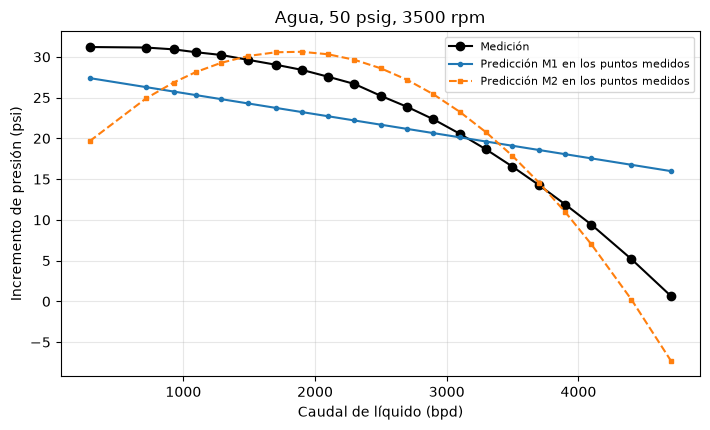

Subidas punto a punto en esa curva. Medición, M1 y M2: 0 0 7


In [17]:
agua = resultado_mapping["fisico"]["agua"]
display(agua)
curva = "50psig|3500|Single Phase"
grupo = resultado_mapping["predicciones"]
grupo = grupo[grupo["curva_id"].eq(curva)].sort_values("abscisa")
fig, eje = plt.subplots(figsize=(7.2, 4.4))
eje.plot(grupo["abscisa"], grupo["medicion"], "o-", color="black", label="Medición")
eje.plot(grupo["abscisa"], grupo["prediccion_m1"], "-o", ms=3, label="Predicción M1 en los puntos medidos")
eje.plot(grupo["abscisa"], grupo["prediccion_m2"], "--s", ms=3, label="Predicción M2 en los puntos medidos")
eje.set_xlabel("Caudal de líquido (bpd)")
eje.set_ylabel("Incremento de presión (psi)")
eje.set_title("Agua, 50 psig, 3500 rpm")
eje.legend(fontsize=8)
eje.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
print(
    "Subidas punto a punto en esa curva. Medición, M1 y M2:",
    int(agua.set_index("curva_id").loc[curva, "subidas_medicion"]),
    int(agua.set_index("curva_id").loc[curva, "subidas_M1"]),
    int(agua.set_index("curva_id").loc[curva, "subidas_M2"]),
)


## 21. Gas a igual caudal

La presión media de una curva mezcla caudales distintos. Para no comparar esos caudales como si fueran el mismo punto, se interpola la medición y las predicciones ya hechas en el centro del caudal común a cada hoja y velocidad. La interpolación no sale del tramo en que todas las curvas del grupo tienen datos. No es una predicción nueva y no entra al entrenamiento. No identifica un régimen.


In [18]:
from esp_datascience.entrenamiento import comparacion_gas_en_soporte_comun, resumen_cancelacion_sesgo

soporte = comparacion_gas_en_soporte_comun(resultado_mapping["predicciones"])
if soporte["es_prediccion_original"].any():
    raise RuntimeError("La interpolación no puede marcarse como predicción del modelo.")
display(soporte)
print("Surging ya mostró la asociación dentro de cada curva. Aquí no se interpola GVF0 entre bloques.")


,hoja,velocidad_rpm,caudal_comun_bpd,ancho_soporte_bpd,qgd,medicion_interpolada_psi,m1_interpolada_psi,m2_interpolada_psi,es_prediccion_original
0,100psig,1800,1328.052743,1858.494372,0.005,6.282807,4.736993,5.849202,False
1,100psig,1800,1328.052743,1858.494372,0.010,5.779564,3.818544,5.286108,False
2,100psig,1800,1328.052743,1858.494372,0.015,5.452335,2.746160,4.898960,False
3,100psig,3500,2554.394175,3484.866457,0.010,23.669429,17.986103,24.170936,False
4,100psig,3500,2554.394175,3484.866457,0.020,23.374283,16.141606,22.762607,False
5,100psig,3500,2554.394175,3484.866457,0.030,22.314188,14.215763,20.630662,False
6,100psig,3500,2554.394175,3484.866457,0.040,18.053166,12.259537,17.981044,False
7,100psig,3500,2554.394175,3484.866457,0.050,14.200976,10.445424,14.846671,False
8,150psig,1800,1323.869317,1846.421219,0.005,6.114690,4.103415,5.773772,False
9,150psig,1800,1323.869317,1846.421219,0.010,5.864685,3.160830,5.555544,False


Surging ya mostró la asociación dentro de cada curva. Aquí no se interpola GVF0 entre bloques.


## 22. Sesgo que se cancela

El sesgo medio por curva puede quedar cerca de cero aunque la mitad de las curvas esté por encima y la otra mitad por debajo. La tabla separa esas dos mitades. No cambia la métrica principal.


In [19]:
for resultado in resultados:
    print(resultado["protocolo"])
    display(resumen_cancelacion_sesgo(resultado["predicciones"]))
print("El desglose por velocidad, presión y condición está en las secciones 10 y 11.")


mapping


,modelo,sesgo_medio_por_curva,curvas_con_sesgo_positivo,curvas_con_sesgo_negativo,media_de_los_sesgos_positivos,media_de_los_sesgos_negativos
0,M1,0.042785,17,13,0.765579,-0.902407
1,M2,0.025131,15,15,0.440187,-0.389925


surging


,modelo,sesgo_medio_por_curva,curvas_con_sesgo_positivo,curvas_con_sesgo_negativo,media_de_los_sesgos_positivos,media_de_los_sesgos_negativos
0,M1,0.135745,6,12,2.369865,-0.981315
1,M2,0.145525,11,7,0.778148,-0.848595


El desglose por velocidad, presión y condición está en las secciones 10 y 11.


## 23. Estado de la fase B

La segunda lectura de las predicciones reproduce el MAE, el RMSE por curva y R² publicados. El RMSE global queda aparte y no sustituye al de la tabla. Las huellas no cambiaron. No se añadió una restricción para impedir predicciones negativas ni para forzar la pendiente de las curvas de agua.

M2 tiene menor error absoluto que M1 en estas particiones. Eso no lo convierte en el modelo de la actividad ni en una descripción física validada. La fase C, con la recta por condición, el bosque y el cociente de agua, no está iniciada.

La fase B queda técnicamente preparada para la revisión de cierre.


## Fase C — Desarrollo de los modelos restantes

La sección 23 cierra la fase B. A partir de aquí empieza la fase C, autorizada después de ese cierre. No se reescriben las salidas anteriores. El protocolo sigue en `2.14-A` y la métrica principal sigue siendo el MAE en psi, con igual peso por curva.

### C.1. Introducción y objetivos

Se estiman tres candidatos que la actividad 2.13 dejó junto a la recta y el polinomio.

- M3 es una regresión lineal distinta para cada condición experimental.
- M4 es un bosque aleatorio de complejidad limitada. La profundidad y el tamaño mínimo de hoja se eligen con las curvas de entrenamiento, no con la prueba externa.
- M5 es el cociente de presión respecto de la curva de agua, solo en mapping y solo donde esa agua está autorizada.

No se declara un ganador. La comparación con incertidumbre queda para la fase D, que no empieza aquí.


### C.2. Hipótesis científicas

Estas hipótesis se formulan antes de leer el error externo. No son conclusiones.

**H3.** Separar la recta por condición experimental puede reducir errores que vienen de mezclar comportamientos distintos. También puede perder generalización cuando una condición tiene pocos experimentos.

**H4.** Un conjunto limitado de árboles puede representar relaciones no lineales e interacciones que M1 y M2 no escriben de forma explícita.

**H5.** En mapping, la degradación de presión respecto de una curva de agua puede describir el efecto del gas si esa referencia está disponible sin mezclar entrenamiento y prueba.

El cociente de H5 no es la presión normalizada de Zhu y Zhang (2018, *Energies*, 11, 180, https://doi.org/10.3390/en11010180). Esa definición multiplica por un cociente de densidades, y estos archivos no traen la densidad de la mezcla.


### C.3. M3: fundamentos matemáticos

Para cada condición c se usa solo el entrenamiento de esa condición. El conjunto J_c reúne los predictores que toman al menos dos valores distintos. En mapping el caudal de líquido tiene que estar en J_c. En surging, GVF0. Si no se cumple, la condición no se estima y no se sustituye por un modelo global.

La predicción es

ŷ = β0,c + Σ βj,c xj, con j en J_c.

En mapping, J_c sale de {caudal en bpd, velocidad en rpm, presión del separador en psig}. Qgd y el indicador de agua son constantes dentro de la condición y no tienen pendiente. En surging, la condición es la fracción de QBEP. GVF0 es el gas continuo, en porcentaje, y no se confunde con esa fracción. El identificador de curva no es un predictor.

Una presión de prueba que no aparece en el entrenamiento de esa condición sigue siendo una predicción de la recta, y queda marcada como extrapolación de la pendiente de presión. No se cambia el pliegue para evitarla.


In [20]:
from esp_datascience.fase_c import factibilidad_m3

print("Python", __import__("sys").version.split()[0])
print("NumPy", np.__version__, "pandas", pd.__version__, "scikit-learn", sklearn.__version__)
print("Semilla", SEMILLA)

def mostrar_factibilidad(tabla, protocolo):
    fac = factibilidad_m3(tabla, protocolo)
    externo = fac[fac["alcance"].eq("externo")].copy()
    interno = fac[fac["alcance"].eq("interno")]
    externo["velocidades"] = externo["velocidades_entrenamiento"].map(lambda xs: ", ".join(map(str, xs)))
    externo["presion_de_prueba_ausente"] = externo["presiones_de_prueba_ausentes"].map(
        lambda xs: ", ".join(str(v) for v in xs) if xs else "ninguna"
    )
    externo["predictores_usados"] = externo["predictores"].map(lambda xs: ", ".join(xs))
    columnas = [
        "pliegue_externo", "condicion", "n_curvas_entrenamiento", "n_filas_entrenamiento",
        "n_curvas_prueba", "velocidades", "presion_de_prueba_ausente", "estimable", "predictores_usados",
    ]
    display(externo[columnas].reset_index(drop=True))
    una_curva = int((interno["n_curvas_entrenamiento"] == 1).sum())
    print(
        protocolo,
        "bloques internos",
        len(interno),
        "con una sola curva de entrenamiento",
        una_curva,
        "no estimables",
        int((~interno["estimable"]).sum()),
    )
    return fac

print("Factibilidad externa de mapping. Cada fila es una condición dentro de un pliegue, antes de ajustar.")
factibilidad_mapping = mostrar_factibilidad(mapping, "mapping")
print("Factibilidad externa de surging. GVF0 no es la condición: la condición es la fracción de QBEP.")
factibilidad_surging = mostrar_factibilidad(surging, "surging")
if not bool(factibilidad_mapping.loc[factibilidad_mapping["alcance"].eq("externo"), "estimable"].all()):
    raise RuntimeError("Una condición externa de mapping no es estimable.")
if not bool(factibilidad_surging.loc[factibilidad_surging["alcance"].eq("externo"), "estimable"].all()):
    raise RuntimeError("Una condición externa de surging no es estimable.")


Python 3.14.8
NumPy 2.5.4 pandas 3.0.6 scikit-learn 1.9.1
Semilla 214
Factibilidad externa de mapping. Cada fila es una condición dentro de un pliegue, antes de ajustar.


,pliegue_externo,condicion,n_curvas_entrenamiento,n_filas_entrenamiento,n_curvas_prueba,velocidades,presion_de_prueba_ausente,estimable,predictores_usados
0,0.0,Qgd=0.005,2,33,1,1800,150.0,True,"ql_bpd, psep_psig"
1,0.0,Qgd=0.01,4,79,2,"1800, 3500",ninguna,True,"ql_bpd, velocidad_rpm, psep_psig"
2,0.0,Qgd=0.015,2,36,1,1800,100.0,True,"ql_bpd, psep_psig"
3,0.0,Qgd=0.02,2,48,1,3500,50.0,True,"ql_bpd, psep_psig"
4,0.0,Qgd=0.03,2,40,1,3500,100.0,True,"ql_bpd, psep_psig"
5,0.0,Qgd=0.04,2,41,1,3500,50.0,True,"ql_bpd, psep_psig"
6,0.0,Qgd=0.05,2,35,1,3500,100.0,True,"ql_bpd, psep_psig"
7,0.0,Single Phase,4,58,2,"1800, 3500",ninguna,True,"ql_bpd, velocidad_rpm, psep_psig"
8,1.0,Qgd=0.005,2,33,1,1800,50.0,True,"ql_bpd, psep_psig"
9,1.0,Qgd=0.01,4,91,2,"1800, 3500",ninguna,True,"ql_bpd, velocidad_rpm, psep_psig"


mapping bloques internos 54 con una sola curva de entrenamiento 36 no estimables 0
Factibilidad externa de surging. GVF0 no es la condición: la condición es la fracción de QBEP.


,pliegue_externo,condicion,n_curvas_entrenamiento,n_filas_entrenamiento,n_curvas_prueba,velocidades,presion_de_prueba_ausente,estimable,predictores_usados
0,0.0,0.75Qbep,4,88,2,"1800, 3500",50.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"
1,0.0,1.25Qbep,4,77,2,"1800, 3500",150.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"
2,0.0,Qbep,4,92,2,"1800, 3500",100.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"
3,1.0,0.75Qbep,4,70,2,"1800, 3500",150.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"
4,1.0,1.25Qbep,4,82,2,"1800, 3500",100.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"
5,1.0,Qbep,4,103,2,"1800, 3500",50.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"
6,2.0,0.75Qbep,4,84,2,"1800, 3500",100.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"
7,2.0,1.25Qbep,4,77,2,"1800, 3500",50.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"
8,2.0,Qbep,4,101,2,"1800, 3500",150.0,True,"gvf0_porcentaje, velocidad_rpm, psep_psig"


surging bloques internos 27 con una sola curva de entrenamiento 0 no estimables 0


### C.4. M3: factibilidad por condición

La tabla anterior cuenta curvas y predictores antes del ajuste. No usa la presión objetivo para decidir si una condición existe.

En mapping, Qgd = 0,01 y el agua tienen las dos velocidades en el entrenamiento. Las demás condiciones de Qgd tienen una sola velocidad, así que esa variable no recibe coeficiente: no sería identificable. En esas condiciones, la presión de la curva de prueba no está entre las presiones de entrenamiento. La recta igual predice, y la fila queda marcada.

En surging las tres fracciones son estimables. Las 18 curvas de prueba piden una presión que esa fracción no vio en el entrenamiento. El anillo interno de mapping deja varios bloques con una sola curva. Siguen siendo estimables por el caudal, y M3 no usa ese anillo para elegir un hiperparámetro.

### C.5. M3: implementación y validación

Cada pliegue reserva sus curvas de prueba, ajusta una recta por condición con el resto y predice solo esas curvas. El error de entrenamiento es el de las mismas curvas con las que se ajustó. No es el criterio de selección: M3 no tiene hiperparámetros que buscar.


In [21]:
from esp_datascience.fase_c import evaluar_m3
from esp_datascience.metricas import error_absoluto_medio, metrica_por_curva

m3_mapping = evaluar_m3(mapping, "mapping")
m3_surging = evaluar_m3(surging, "surging")
for nombre, resultado, n_curvas in (("mapping", m3_mapping, 30), ("surging", m3_surging, 18)):
    cifras = resultado["metricas"]
    print(nombre, {k: round(cifras[k], 3) if isinstance(cifras[k], float) else cifras[k] for k in cifras})
    print(resultado["errores_por_pliegue"].round(3).to_string(index=False))
    if cifras["n_curvas_cubiertas"] != n_curvas:
        raise RuntimeError(nombre)
curvas_extra_m = int(m3_mapping["predicciones"].groupby("curva_id")["extrapolacion_psep_dentro_de_la_condicion"].any().sum())
curvas_extra_s = int(m3_surging["predicciones"].groupby("curva_id")["extrapolacion_psep_dentro_de_la_condicion"].any().sum())
print("Curvas cuya presión de prueba no está en el entrenamiento de su condición.", "mapping", curvas_extra_m, "surging", curvas_extra_s)
if round(resultado_mapping["externo"].set_index("modelo").loc["M1", "mae_curva"], 3) != 3.999:
    raise RuntimeError("M1 de mapping cambió.")
if round(m3_mapping["metricas"]["mae_curva"], 3) != 3.783:
    raise RuntimeError("El MAE de M3 en mapping no es el de esta ejecución.")
if round(m3_surging["metricas"]["mae_curva"], 3) != 2.041:
    raise RuntimeError("El MAE de M3 en surging no es el de esta ejecución.")


mapping {'protocolo': 'mapping', 'modelo': 'M3', 'n_curvas_cubiertas': 30, 'n_curvas_totales': 30, 'n_filas_cubiertas': 570, 'n_filas_totales': 570, 'n_filas_en_el_mae': 570, 'mae_curva': 3.783, 'rmse_curva': 4.488, 'sesgo_curva': -0.153, 'r2_observaciones': 0.591, 'mae_fila': 4.145}
 pliegue  mae_entrenamiento_por_curva  mae_externo_por_curva
       0                        3.693                  3.627
       1                        3.571                  3.826
       2                        3.497                  3.897
surging {'protocolo': 'surging', 'modelo': 'M3', 'n_curvas_cubiertas': 18, 'n_curvas_totales': 18, 'n_filas_cubiertas': 387, 'n_filas_totales': 387, 'n_filas_en_el_mae': 387, 'mae_curva': 2.041, 'rmse_curva': 2.486, 'sesgo_curva': 0.35, 'r2_observaciones': 0.895, 'mae_fila': 2.019}
 pliegue  mae_entrenamiento_por_curva  mae_externo_por_curva
       0                        1.846                  1.916
       1                        1.731                  2.153
     

### C.6. M4: fundamentos de Random Forest

Un árbol parte las entradas en regiones y asigna a cada región un valor constante. Un bosque promedia muchos árboles. Breiman (2001, *Machine Learning*, 45, 5–32, https://doi.org/10.1023/A:1010933404324) muestra que la idea vale para regresión y que el error depende de la fuerza de cada árbol y de la correlación entre ellos. Con 30 o 18 curvas, un árbol profundo puede acercarse a memorizar el entrenamiento. Por eso la profundidad y el tamaño de hoja están limitados.

Que el bosque reproduzca una curva no significa que comprenda la hidráulica de la bomba. Un árbol no extrapola fuera de los valores de entrenamiento que cayeron en sus hojas: la predicción es un promedio de mediciones vistas.

### C.7. M4: hiperparámetros y validación

Antes de consultar el error externo se fijó la rejilla. `n_estimators` queda en 100: en estas tablas, con validación anidada, buscar también 200 árboles alarga el cálculo y no cambia la pregunta. Se buscan `max_depth` en {3, 5, 7} y `min_samples_leaf` en {3, 5, 10}. La semilla es 214. Entran todos los predictores autorizados. El desempate, si el MAE interno difiere en menos de 10⁻⁹ psi, se queda con la menor profundidad y, dentro de ella, con la hoja mínima más grande.

`n_estimators` es el número de árboles promediados. `max_depth` es el máximo de cortes sucesivos. `min_samples_leaf` es el mínimo de observaciones en una hoja.


mapping {'mae_curva': 1.044, 'rmse_curva': 1.546, 'sesgo_curva': -0.007, 'r2_observaciones': 0.937, 'n_curvas_cubiertas': 30}


,pliegue,max_depth,min_samples_leaf,n_estimators,mae_interno_por_curva,mae_entrenamiento_por_curva,mae_externo_por_curva
0,0,7,3,100,1.389,0.811,0.912
1,1,7,3,100,1.258,0.715,1.076
2,2,7,3,100,1.368,0.720,1.143


surging {'mae_curva': 0.754, 'rmse_curva': 0.963, 'sesgo_curva': 0.041, 'r2_observaciones': 0.972, 'n_curvas_cubiertas': 18}


,pliegue,max_depth,min_samples_leaf,n_estimators,mae_interno_por_curva,mae_entrenamiento_por_curva,mae_externo_por_curva
0,0,5,3,100,1.680,0.489,0.626
1,1,7,3,100,0.981,0.337,0.856
2,2,7,3,100,1.669,0.344,0.779


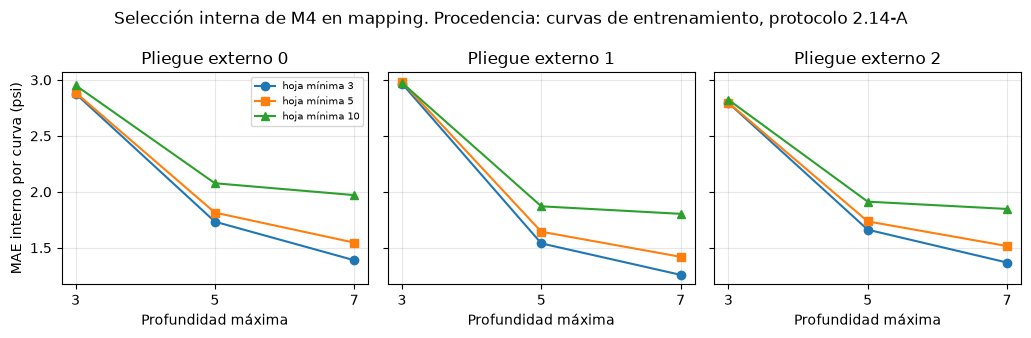

La esquina de profundidad 7 y hoja mínima 3 tiene el menor MAE interno en los tres pliegues de mapping. No se amplió la rejilla después de ver la prueba.


In [22]:
from esp_datascience.fase_c import evaluar_m4

m4_mapping = evaluar_m4(mapping, "mapping")
m4_surging = evaluar_m4(surging, "surging")
for nombre, resultado in (("mapping", m4_mapping), ("surging", m4_surging)):
    print(nombre, {k: round(resultado["metricas"][k], 3) if isinstance(resultado["metricas"][k], float) else resultado["metricas"][k] for k in ("mae_curva", "rmse_curva", "sesgo_curva", "r2_observaciones", "n_curvas_cubiertas")})
    display(resultado["hiperparametros"][["pliegue", "max_depth", "min_samples_leaf", "n_estimators", "mae_interno_por_curva", "mae_entrenamiento_por_curva", "mae_externo_por_curva"]].round(3))
if round(m4_mapping["metricas"]["mae_curva"], 3) != 1.044:
    raise RuntimeError("El MAE de M4 en mapping no es el de esta ejecución.")
if round(m4_surging["metricas"]["mae_curva"], 3) != 0.754:
    raise RuntimeError("El MAE de M4 en surging no es el de esta ejecución.")

busqueda = m4_mapping["busqueda"]
fig, ejes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharey=True)
for eje, pliegue in zip(ejes, (0, 1, 2)):
    sub = busqueda[busqueda["pliegue_externo"].eq(pliegue)]
    for hoja, marca in ((3, "o"), (5, "s"), (10, "^")):
        trozo = sub[sub["min_samples_leaf"].eq(hoja)].sort_values("max_depth")
        eje.plot(trozo["max_depth"], trozo["mae_interno_por_curva"], marca + "-", label=f"hoja mínima {hoja}")
    eje.set_title(f"Pliegue externo {pliegue}")
    eje.set_xlabel("Profundidad máxima")
    eje.set_xticks([3, 5, 7])
    eje.grid(True, alpha=0.3)
ejes[0].set_ylabel("MAE interno por curva (psi)")
ejes[0].legend(fontsize=7)
fig.suptitle("Selección interna de M4 en mapping. Procedencia: curvas de entrenamiento, protocolo 2.14-A")
fig.tight_layout()
plt.show()
print("La esquina de profundidad 7 y hoja mínima 3 tiene el menor MAE interno en los tres pliegues de mapping. No se amplió la rejilla después de ver la prueba.")


### C.8. M5: fundamentos semiempíricos

Para un punto con gas se define, cuando las dos presiones existen a un caudal de líquido comparable y a la misma hoja y velocidad,

R = ΔP_gas / ΔP_agua.

La relación que se ajusta con el entrenamiento autorizado es R̂ = β0 + β1 Qgd. La predicción vuelve a psi al multiplicar R̂ por la presión de agua interpolada. La interpolación se detiene en el menor y el mayor caudal medidos de esa agua. No se extrapola.

### C.9. M5: análisis de disponibilidad y fuga de información

La fase A ya separó, en cada hoja y velocidad, la curva de agua y las curvas con gas en pliegues distintos. Eso permite que el gas de prueba mire un agua de entrenamiento. No permite usar el agua que quedó en la prueba, aunque sea la de la misma velocidad y la misma presión. Tampoco se consulta el incremento de presión medido del gas que se quiere predecir. De las curvas de gas del entrenamiento, solo entran al ajuste las que tienen su agua también en el entrenamiento.


### C.10. M5: implementación

El ajuste es viable en los tres pliegues porque hay más de un Qgd entre los puntos autorizados. La predicción de una curva de prueba usa el agua de entrenamiento de su hoja y su velocidad. Si un caudal cae fuera de ese tramo, el punto queda vacío. El MAE usa solo las curvas sin ningún vacío.


In [23]:
from esp_datascience.fase_c import evaluar_m5, factibilidad_m5, metricas_de_columna

print("Disponibilidad de agua por pliegue, antes de calcular el cociente.")
display(factibilidad_m5(mapping))
m5 = evaluar_m5(mapping)
display(pd.DataFrame(m5["detalle"]).round(4))
print(m5["nota"])
print("Curvas completas", list(m5["mae_por_curva"].index))
print(
    "Filas con algún valor",
    m5["metricas"]["n_filas_cubiertas"],
    "de",
    m5["metricas"]["n_filas_totales"],
    ". Filas que entran al MAE",
    m5["metricas"]["n_filas_en_el_mae"],
)
agua_predicha = int(m5["predicciones"].loc[m5["predicciones"]["condicion"].eq("Single Phase"), "prediccion_m5"].notna().sum())
if agua_predicha != 0:
    raise RuntimeError("M5 predijo una curva de agua.")
if m5["metricas"]["n_curvas_cubiertas"] != 5:
    raise RuntimeError("La cobertura completa de M5 cambió.")


Disponibilidad de agua por pliegue, antes de calcular el cociente.


,pliegue,curvas_gas_de_prueba,su_agua_esta_en_entrenamiento,curvas_gas_de_entrenamiento,agua_tambien_en_entrenamiento,agua_reservada_en_la_prueba,curvas_de_agua_en_la_prueba,m5_no_predice_el_agua_de_prueba
0,0,8,8,16,8,8,2,True
1,1,8,8,16,8,8,2,True
2,2,8,8,16,8,8,2,True


,pliegue,estimable,n_puntos,n_curvas_gas,intercepto,pendiente_por_qgd
0,0,True,139,8,0.9160,-8.1858
1,1,True,148,8,0.9222,-7.4373
2,2,True,140,8,0.8856,-6.8374


M5 no compite en todas las curvas. El MAE usa solo las curvas de gas cuyos caudales caen enteros dentro del agua de entrenamiento.
Curvas completas ['50psig|1800|Qgd=0.01', '50psig|1800|Qgd=0.015', '50psig|3500|Qgd=0.02', '50psig|3500|Qgd=0.04', '50psig|3500|Qgd=0.05']
Filas con algún valor 427 de 570 . Filas que entran al MAE 89


### C.11. Comparación externa de modelos

La tabla principal reúne M1, M2, M3 y M4 sobre todas las curvas externas. M5 no entra en esa tabla: su cobertura es un subconjunto. La segunda tabla repite M1 a M5 en exactamente las curvas que M5 cubre por completo. Una diferencia negativa significa que el candidato tiene menor MAE que la referencia en esa curva.


,protocolo,modelo,mae_curva,rmse_curva,sesgo_curva,r2,cobertura
0,mapping,M1,3.999,4.865,0.043,0.543,30/30
1,mapping,M2,1.364,1.707,0.025,0.940,30/30
2,mapping,M3,3.783,4.488,-0.153,0.591,30/30
3,mapping,M4,1.044,1.546,-0.007,0.937,30/30
4,surging,M1,2.312,2.734,0.136,0.894,18/18
5,surging,M2,1.114,1.353,0.146,0.962,18/18
6,surging,M3,2.041,2.486,0.350,0.895,18/18
7,surging,M4,0.754,0.963,0.041,0.972,18/18


,protocolo,comparacion,media_psi,mediana_psi,curvas_con_menor_mae,curvas
0,mapping,M3 menos M1,-0.215,0.054,12,30
1,mapping,M3 menos M2,2.419,2.163,4,30
2,mapping,M4 menos M1,-2.955,-2.555,30,30
3,mapping,M4 menos M2,-0.321,-0.258,21,30
4,surging,M3 menos M1,-0.271,-0.042,9,18
5,surging,M3 menos M2,0.927,0.818,5,18
6,surging,M4 menos M1,-1.559,-1.368,17,18
7,surging,M4 menos M2,-0.360,-0.391,15,18


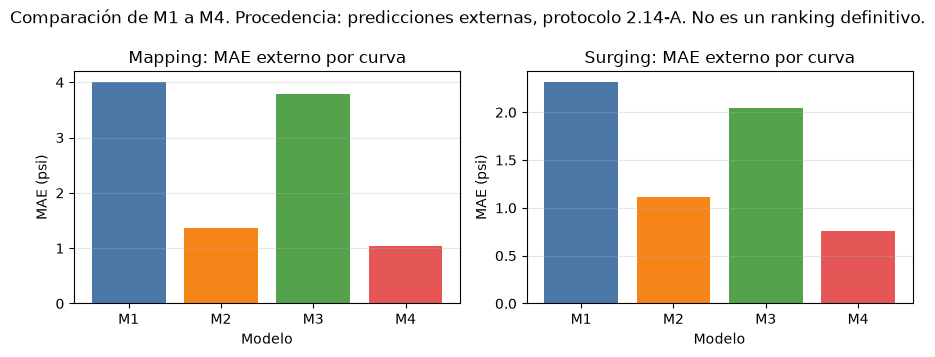

Mismas 5 curvas de M5. Este MAE no se compara con el de las 30 curvas.


,modelo,n_curvas_cubiertas,n_filas_en_el_mae,mae_curva,rmse_curva,sesgo_curva,r2_observaciones
0,M1,5,89,3.0795,3.7341,-0.4233,0.6774
1,M2,5,89,1.0477,1.2895,-0.1013,0.9607
2,M3,5,89,3.3811,4.0434,0.2351,0.6515
3,M4,5,89,1.2065,1.5004,0.6074,0.9504
4,M5,5,89,2.0775,2.8846,0.2037,0.8277


In [24]:
from esp_datascience.fase_c import diferencias_sobre_curvas_comunes, metricas_de_columna

def fila_modelo(resultado_base, modelo, protocolo):
    fila = resultado_base["externo"].set_index("modelo").loc[modelo]
    return {
        "protocolo": protocolo,
        "modelo": modelo,
        "mae_curva": float(fila["mae_curva"]),
        "rmse_curva": float(fila["rmse_curva"]),
        "sesgo_curva": float(fila["sesgo_curva"]),
        "r2": float(fila["r2_observaciones"]),
        "cobertura": "30/30" if protocolo == "mapping" else "18/18",
    }

def fila_nueva(resultado, cobertura):
    cifras = resultado["metricas"]
    return {
        "protocolo": resultado["protocolo"],
        "modelo": resultado["modelo"],
        "mae_curva": cifras["mae_curva"],
        "rmse_curva": cifras["rmse_curva"],
        "sesgo_curva": cifras["sesgo_curva"],
        "r2": cifras["r2_observaciones"],
        "cobertura": cobertura,
    }

comparacion_c = pd.DataFrame(
    [
        fila_modelo(resultado_mapping, "M1", "mapping"),
        fila_modelo(resultado_mapping, "M2", "mapping"),
        fila_nueva(m3_mapping, "30/30"),
        fila_nueva(m4_mapping, "30/30"),
        fila_modelo(resultado_surging, "M1", "surging"),
        fila_modelo(resultado_surging, "M2", "surging"),
        fila_nueva(m3_surging, "18/18"),
        fila_nueva(m4_surging, "18/18"),
    ]
)
display(comparacion_c.round(3))

def mae_de(pred, columna):
    return metrica_por_curva(pred["medicion"], pred[columna], pred["curva_id"], error_absoluto_medio)

pares = []
for protocolo, base, m3, m4 in (
    ("mapping", resultado_mapping, m3_mapping, m4_mapping),
    ("surging", resultado_surging, m3_surging, m4_surging),
):
    mae1 = mae_de(base["predicciones"], "prediccion_m1")
    mae2 = mae_de(base["predicciones"], "prediccion_m2")
    for nombre, serie in (("M3", m3["mae_por_curva"]), ("M4", m4["mae_por_curva"])):
        for referencia, mae_ref in (("M1", mae1), ("M2", mae2)):
            delta = diferencias_sobre_curvas_comunes(mae_ref, serie)
            pares.append(
                {
                    "protocolo": protocolo,
                    "comparacion": f"{nombre} menos {referencia}",
                    "media_psi": float(delta.mean()),
                    "mediana_psi": float(delta.median()),
                    "curvas_con_menor_mae": int((delta < 0).sum()),
                    "curvas": int(len(delta)),
                }
            )
display(pd.DataFrame(pares).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.6), sharey=False)
for eje, protocolo in zip(ejes, ("mapping", "surging")):
    trozo = comparacion_c[comparacion_c["protocolo"].eq(protocolo)]
    eje.bar(trozo["modelo"], trozo["mae_curva"], color=["#4c78a8", "#f58518", "#54a24b", "#e45756"])
    eje.set_title(f"{protocolo.capitalize()}: MAE externo por curva")
    eje.set_ylabel("MAE (psi)")
    eje.set_xlabel("Modelo")
    eje.grid(True, axis="y", alpha=0.3)
fig.suptitle("Comparación de M1 a M4. Procedencia: predicciones externas, protocolo 2.14-A. No es un ranking definitivo.")
fig.tight_layout()
plt.show()

cubiertas = m5["predicciones"]["curva_id"].isin(m5["mae_por_curva"].index)
sub = resultado_mapping["predicciones"].loc[cubiertas].copy()
sub["prediccion_m3"] = m3_mapping["predicciones"].loc[sub.index, "prediccion_m3"]
sub["prediccion_m4"] = m4_mapping["predicciones"].loc[sub.index, "prediccion_m4"]
sub["prediccion_m5"] = m5["predicciones"].loc[sub.index, "prediccion_m5"]
filas_sub = []
for modelo, columna in (
    ("M1", "prediccion_m1"),
    ("M2", "prediccion_m2"),
    ("M3", "prediccion_m3"),
    ("M4", "prediccion_m4"),
    ("M5", "prediccion_m5"),
):
    cifras = metricas_de_columna(sub, columna, "mapping", modelo)
    filas_sub.append(cifras)
print("Mismas 5 curvas de M5. Este MAE no se compara con el de las 30 curvas.")
display(pd.DataFrame(filas_sub)[["modelo", "n_curvas_cubiertas", "n_filas_en_el_mae", "mae_curva", "rmse_curva", "sesgo_curva", "r2_observaciones"]].round(4))


### C.12. Diagnóstico de coherencia física

Se usan los mismos criterios que en la fase B. Una predicción negativa se registra y no se cambia por cero. En una curva de agua se cuentan los pasos que suben al ordenar por caudal. Esa cuenta no es el coeficiente de Spearman. El punto medio del caudal común describe el gas a un caudal interior compartido. No es una predicción nueva y no identifica un régimen.


Predicciones negativas de M3: 31 . M4 en mapping: 0 . M4 en surging: 0
Mínimo de M3 en mapping -1.897 psi. En surging -13.993 psi.
Rango de M4 en mapping 0.451 a 28.706 psi.


protocolo  condicion     velocidad_rpm
mapping    Single Phase  1800              4
surging    0.75Qbep      1800             10
           1.25Qbep      1800              9
           Qbep          1800              8
Name: filas, dtype: int64

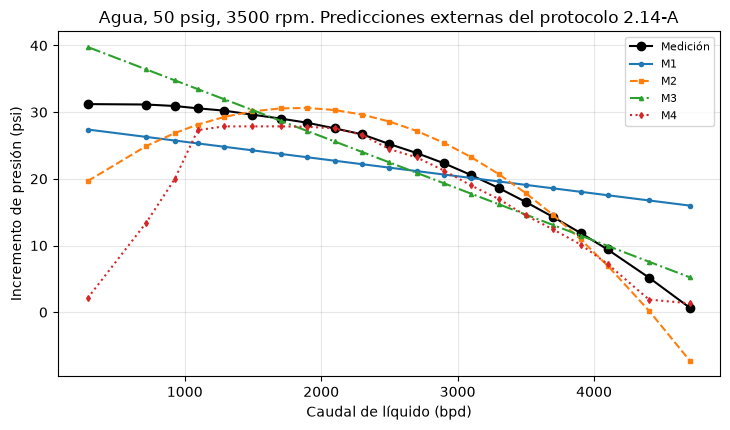

Curvas de agua. Spearman y subidas punto a punto no son la misma pregunta.


,curva_id,spearman_m3,subidas_m3,spearman_m4,subidas_m4
0,100psig|1800|Single Phase,-1.0,0,-0.983,1
1,100psig|3500|Single Phase,-1.0,0,-0.979,1
2,150psig|1800|Single Phase,-1.0,0,-0.806,2
3,150psig|3500|Single Phase,-1.0,0,-0.963,1
4,50psig|1800|Single Phase,-1.0,0,-0.733,2
5,50psig|3500|Single Phase,-1.0,0,-0.549,4


Sesgo medio de M4 en mapping, por velocidad, presión y condición. Un sesgo positivo queda por encima de la medición.


velocidad
1800   -0.046
3500    0.020
Name: sesgo_psi, dtype: float64

presion
50.0    -0.171
100.0    0.289
150.0   -0.138
Name: sesgo_psi, dtype: float64

condicion
Qgd=0.005      -0.072
Qgd=0.01       -0.051
Qgd=0.015       0.381
Qgd=0.02        0.369
Qgd=0.03        0.470
Qgd=0.04       -0.001
Qgd=0.05        1.245
Single Phase   -1.179
Name: sesgo_psi, dtype: float64

Pasos en los que la presión interpolada sube al aumentar Qgd, en el centro del caudal común.
100psig 1800 rpm. Subidas de medición, M3 y M4: [0, 0, 0] de 2
100psig 3500 rpm. Subidas de medición, M3 y M4: [0, 1, 0] de 4
150psig 1800 rpm. Subidas de medición, M3 y M4: [0, 1, 0] de 2
150psig 3500 rpm. Subidas de medición, M3 y M4: [0, 2, 1] de 4
50psig 1800 rpm. Subidas de medición, M3 y M4: [0, 1, 0] de 2
50psig 3500 rpm. Subidas de medición, M3 y M4: [0, 1, 0] de 4
Las huellas de los Excel y de los CSV siguen iguales.


In [25]:
from scipy.stats import spearmanr
from esp_datascience.entrenamiento import guardar_derivado
from esp_datascience.fase_c import filas_negativas
from esp_datascience.metricas import sesgo_medio

negativas_c = pd.concat(
    [
        filas_negativas(m3_mapping["predicciones"], "mapping", "M3", "prediccion_m3"),
        filas_negativas(m3_surging["predicciones"], "surging", "M3", "prediccion_m3"),
    ],
    ignore_index=True,
)
print("Predicciones negativas de M3:", len(negativas_c), ". M4 en mapping:", int((m4_mapping["predicciones"]["prediccion_m4"] < 0).sum()), ". M4 en surging:", int((m4_surging["predicciones"]["prediccion_m4"] < 0).sum()))
print("Mínimo de M3 en mapping", round(float(m3_mapping["predicciones"]["prediccion_m3"].min()), 3), "psi. En surging", round(float(m3_surging["predicciones"]["prediccion_m3"].min()), 3), "psi.")
print("Rango de M4 en mapping", round(float(m4_mapping["predicciones"]["prediccion_m4"].min()), 3), "a", round(float(m4_mapping["predicciones"]["prediccion_m4"].max()), 3), "psi.")
display(negativas_c.groupby(["protocolo", "condicion", "velocidad_rpm"]).size().rename("filas"))
guardar_derivado(negativas_c, RAIZ / "docs" / "derivados" / "predicciones_negativas_fase_c.csv")

curva = "50psig|3500|Single Phase"
grupo = m3_mapping["predicciones"]
grupo = grupo[grupo["curva_id"].eq(curva)].sort_values("abscisa").copy()
grupo["prediccion_m4"] = m4_mapping["predicciones"].loc[grupo.index, "prediccion_m4"]
grupo["prediccion_m1"] = resultado_mapping["predicciones"].loc[grupo.index, "prediccion_m1"]
grupo["prediccion_m2"] = resultado_mapping["predicciones"].loc[grupo.index, "prediccion_m2"]
fig, eje = plt.subplots(figsize=(7.4, 4.4))
eje.plot(grupo["abscisa"], grupo["medicion"], "o-", color="black", label="Medición")
eje.plot(grupo["abscisa"], grupo["prediccion_m1"], "-o", ms=3, label="M1")
eje.plot(grupo["abscisa"], grupo["prediccion_m2"], "--s", ms=3, label="M2")
eje.plot(grupo["abscisa"], grupo["prediccion_m3"], "-.^", ms=3, label="M3")
eje.plot(grupo["abscisa"], grupo["prediccion_m4"], ":d", ms=3, label="M4")
eje.set_xlabel("Caudal de líquido (bpd)")
eje.set_ylabel("Incremento de presión (psi)")
eje.set_title("Agua, 50 psig, 3500 rpm. Predicciones externas del protocolo 2.14-A")
eje.legend(fontsize=8)
eje.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

agua = m4_mapping["predicciones"][m4_mapping["predicciones"]["condicion"].eq("Single Phase")]
filas_agua = []
for identificador, bloque in agua.groupby("curva_id", sort=True):
    m3b = m3_mapping["predicciones"].loc[bloque.index]
    orden = np.argsort(bloque["abscisa"].to_numpy(dtype=float), kind="mergesort")
    sube_m4 = int(np.sum(np.diff(bloque["prediccion_m4"].to_numpy(dtype=float)[orden]) > 0))
    sube_m3 = int(np.sum(np.diff(m3b["prediccion_m3"].to_numpy(dtype=float)[orden]) > 0))
    filas_agua.append(
        {
            "curva_id": identificador,
            "spearman_m3": float(spearmanr(bloque["abscisa"], m3b["prediccion_m3"]).statistic),
            "subidas_m3": sube_m3,
            "spearman_m4": float(spearmanr(bloque["abscisa"], bloque["prediccion_m4"]).statistic),
            "subidas_m4": sube_m4,
        }
    )
print("Curvas de agua. Spearman y subidas punto a punto no son la misma pregunta.")
display(pd.DataFrame(filas_agua).round(3))

def sesgo_por(pred, columna):
    sesgo = metrica_por_curva(pred["medicion"], pred[columna], pred["curva_id"], sesgo_medio)
    meta = pred.groupby("curva_id").agg(velocidad=("velocidad_rpm", "first"), presion=("psep_psig", "first"), condicion=("condicion", "first"))
    meta["sesgo"] = sesgo
    return meta

print("Sesgo medio de M4 en mapping, por velocidad, presión y condición. Un sesgo positivo queda por encima de la medición.")
meta_m4 = sesgo_por(m4_mapping["predicciones"], "prediccion_m4")
display(meta_m4.groupby("velocidad")["sesgo"].mean().round(3).rename("sesgo_psi"))
display(meta_m4.groupby("presion")["sesgo"].mean().round(3).rename("sesgo_psi"))
display(meta_m4.groupby("condicion")["sesgo"].mean().round(3).rename("sesgo_psi"))

gas = m3_mapping["predicciones"][m3_mapping["predicciones"]["condicion"].ne("Single Phase")].copy()
gas["prediccion_m4"] = m4_mapping["predicciones"].loc[gas.index, "prediccion_m4"]
gas["qgd"] = gas["condicion"].str.replace("Qgd=", "", regex=False).astype(float)
print("Pasos en los que la presión interpolada sube al aumentar Qgd, en el centro del caudal común.")
for (hoja, velocidad), bloque in gas.groupby(["hoja", "velocidad_rpm"], sort=True):
    partes = [cg for _, cg in bloque.groupby("condicion", sort=True)]
    inferior = max(float(cg["abscisa"].min()) for cg in partes)
    superior = min(float(cg["abscisa"].max()) for cg in partes)
    caudal = 0.5 * (inferior + superior)
    valores = []
    for cg in sorted(partes, key=lambda x: float(x["qgd"].iloc[0])):
        agregado = cg.groupby("abscisa", as_index=False)[["medicion", "prediccion_m3", "prediccion_m4"]].mean().sort_values("abscisa")
        xs = agregado["abscisa"].to_numpy(dtype=float)
        if caudal < xs[0] or caudal > xs[-1]:
            continue
        valores.append(
            (
                float(np.interp(caudal, xs, agregado["medicion"])),
                float(np.interp(caudal, xs, agregado["prediccion_m3"])),
                float(np.interp(caudal, xs, agregado["prediccion_m4"])),
            )
        )
    suben = [int(np.sum(np.diff([v[i] for v in valores]) > 0)) for i in range(3)]
    print(hoja, int(velocidad), "rpm. Subidas de medición, M3 y M4:", suben, "de", len(valores) - 1)

for relativo, esperada in HUELLAS.items():
    if huella_sha256(RAIZ / relativo) != esperada:
        raise RuntimeError(relativo)
print("Las huellas de los Excel y de los CSV siguen iguales.")


### C.13. Discusión de resultados

H3 no aparece como una ventaja general. El MAE medio de M3 es un poco menor que el de M1, pero la mediana de la diferencia pareada está cerca de cero y M2 tiene menor error en la mayoría de las curvas. La recta especializada, además, predice presiones de separador que esa condición no vio. El error de entrenamiento y el externo quedan cerca: el límite de M3 es la forma de la recta, no una memorización evidente.

H4 sí reduce el MAE externo frente a M1 en casi todas las curvas y frente a M2 en la mayoría. El bosque elegido está en la zona más flexible de la rejilla fijada, salvo el pliegue 0 de surging, que prefirió profundidad 5. El error sobre las curvas de entrenamiento es menor que el externo. Al mismo tiempo, M4 dobla las seis curvas de agua. En agua a 50 psig y 3500 rpm, un paso sube 11,291 psi mientras la medición baja unas centésimas. En ese mismo primer punto, M3 predice 39,769 psi frente a una medición de 31,210 psi. Un MAE más bajo y una curva hidráulicamente irregular pueden ocurrir juntos.

H5 se pudo calcular sin leer el agua de prueba. Solo 5 curvas, todas a 50 psig, tienen el caudal entero dentro del agua autorizada. En esas curvas el MAE de M5 queda entre el de M1 y el de M2. No cubre el resto del ensayo.

La media de las medias por curva distingue 1800 rpm de 3500 rpm en M3 y en M4, con una diferencia del orden de 11 psi en mapping y de 12 psi en surging, parecida a la de la medición. Eso no es una ley de afinidad ni una validación mecánica.

### C.14. Limitaciones

- Dieciocho curvas de mapping y las dieciocho de surging piden, dentro de su condición, una presión de separador que el entrenamiento de esa condición no contiene.
- En el anillo interno de mapping, 36 bloques de condición tienen una sola curva. M3 externo no depende de ese anillo, y el dato muestra lo poco que queda de una condición al apartar otra curva.
- La rejilla de M4 se detuvo en profundidad 7. En mapping, el MAE interno eligió ese borde. No se buscó una profundidad mayor después de ver la prueba.
- M4 no sale del rango de las hojas de entrenamiento. Por eso no alcanza el mínimo medido de surging ni el máximo medido de mapping.
- M5 deja fuera 100 psig, 150 psig, las curvas de agua y los puntos de gas cuyo caudal no cae dentro del agua.
- El sesgo medio pequeño sigue siendo una cancelación entre curvas de signo distinto.
- No hay una prueba de incertidumbre en este protocolo. Por eso no se rechaza ni se acepta un modelo como definitivo.
- Sigue abierta la lectura de `DP2-3` como incremento de la etapa 3, la de `Flow rate` en bpd y el uso de la velocidad asignada por el diseño en las hojas de mapping que no guardan el número.

### C.15. Conclusiones provisionales

M3 cubre todas las curvas externas y no mejora de forma pareja a la recta global. M4 cubre todas las curvas, baja el MAE frente a M1 y, en la mayoría, frente a M2, y presenta subidas locales en el agua. M5 es una referencia parcial de cinco curvas, calculada sin la curva de agua reservada para la prueba. M1 y M2 conservan las cifras de la fase B.

No se nombra un ganador. La fase D, todavía no iniciada, es la comparación que junta precisión, cobertura, estabilidad e irregularidades físicas.

**Fase C preparada para revisión científica de cierre.**


## Fase D — Comparación científica e incertidumbre

Las secciones anteriores dejan estimados M1, M2, M3, M4 y M5. Esta fase no busca otro modelo ni vuelve a elegir hiperparámetros. Compara las predicciones externas ya hechas.

### D.1. Objetivo y metodología

La pregunta no es cuál MAE es menor. Es qué se puede sostener, con estas curvas, sobre precisión, incertidumbre, estabilidad, sesgo, tendencia física, cobertura y lectura del modelo.

La unidad de análisis es la curva completa: hoja, velocidad y condición. Mapping tiene 30 curvas y surging 18. Esas curvas comparten equipo, fluido y procedimiento. Separarlas en el ajuste evita que los puntos de una misma curva entren a la vez en entrenamiento y en prueba. No las convierte en experimentos independientes.

La actividad 2.13 fijó, antes de ver un error, esta regla para llamar superior a un modelo. Tienen que cumplirse juntas:

- MAE y RMSE por curva menores que los de la regresión lineal del mismo protocolo.
- Sesgo que no cambie de signo de forma sistemática entre 1800 y 3500 rpm ni entre 50, 100 y 150 psig.
- El resultado de mapping se mantiene al repetir el ajuste sin las filas de velocidad asignada por el diseño.
- La complejidad adicional estaba declarada antes de ver la prueba.
- Si la diferencia de error es pequeña, se prefiere el modelo más legible.

Los pesos de idoneidad de 2.13 eran 25 % compatibilidad, 25 % fundamento físico, 20 % forma observada, 15 % validación, 10 % interpretabilidad y 5 % simplicidad. Medían si un modelo se podía plantear con estas tablas. No se reescriben con el MAE.

### D.2. Consolidación de predicciones externas

Se reúnen las predicciones que ya calcularon las fases B y C. No se vuelve a ajustar.


In [26]:
from esp_datascience.fase_d import (
    N_REPLICAS,
    SEMILLA_BOOTSTRAP,
    bootstrap_conglomerados,
    bootstrap_media,
    delta_mae,
    dependencia_de_curvas_extremas,
    mae_por_curva,
    meta_de_curvas,
    monotonía_de_agua,
    origen_de_velocidad,
    primeros_por_ponderacion,
    puntuacion_de_agua,
    puntuacion_de_negativas,
    puntuacion_por_spearman,
    puntuacion_por_subidas_de_gas,
    resumen_negativas,
    sesgo_por_curva,
    subidas_en_caudal_comun,
    tabla_por_grupo,
    bonferroni_posterior,
    detalle_de_ponderacion,
    diagnostico_sin_un_conglomerado,
    notas_de_agua_bajo_umbrales,
    notas_de_negativas_bajo_umbrales,
    pesos_efectivos,
    wilcoxon_exploratorio,
)
from esp_datascience.fase_c import metricas_de_columna
from esp_datascience.metricas import raiz_error_cuadratico_medio, media_por_curva
from scipy.stats import spearmanr

print("Semilla del remuestreo", SEMILLA_BOOTSTRAP, ". Réplicas", N_REPLICAS, ". Nivel 0,95.")
print("Python", __import__("sys").version.split()[0], "NumPy", np.__version__)

def unir(base, m3, m4):
    pred = base["predicciones"].copy()
    pred["prediccion_m3"] = m3["predicciones"]["prediccion_m3"]
    pred["prediccion_m4"] = m4["predicciones"]["prediccion_m4"]
    return pred

prediccion_mapping = unir(resultado_mapping, m3_mapping, m4_mapping)
prediccion_surging = unir(resultado_surging, m3_surging, m4_surging)
COLUMNAS = {"M1": "prediccion_m1", "M2": "prediccion_m2", "M3": "prediccion_m3", "M4": "prediccion_m4"}
PARES = (("M2", "M1"), ("M3", "M1"), ("M3", "M2"), ("M4", "M1"), ("M4", "M2"), ("M4", "M3"))

def rmse_por_curva(pred, columna):
    return media_por_curva(pred["medicion"], pred[columna], pred["curva_id"], raiz_error_cuadratico_medio)

controles = {
    ("mapping", "M1"): 3.999,
    ("mapping", "M2"): 1.364,
    ("mapping", "M3"): 3.783,
    ("mapping", "M4"): 1.044,
    ("surging", "M1"): 2.312,
    ("surging", "M2"): 1.114,
    ("surging", "M3"): 2.041,
    ("surging", "M4"): 0.754,
}
for protocolo, pred in (("mapping", prediccion_mapping), ("surging", prediccion_surging)):
    for modelo, columna in COLUMNAS.items():
        cifra = round(float(mae_por_curva(pred, columna).mean()), 3)
        if cifra != controles[(protocolo, modelo)]:
            raise RuntimeError(f"{protocolo} {modelo} {cifra}")
print("Los MAE por curva de M1 a M4 coinciden con el control de reproducibilidad.")


Semilla del remuestreo 214 . Réplicas 10000 . Nivel 0,95.
Python 3.14.8 NumPy 2.5.4
Los MAE por curva de M1 a M4 coinciden con el control de reproducibilidad.


### D.3. Comparación predictiva

El MAE y el RMSE pesan igual cada curva. R² reúne las observaciones y no es la métrica de selección. M5 no entra en esta tabla: solo cubre cinco curvas.


,protocolo,modelo,mae_psi,rmse_psi,n_curvas
0,mapping,M1,3.999,4.865,30
1,mapping,M2,1.364,1.707,30
2,mapping,M3,3.783,4.488,30
3,mapping,M4,1.044,1.546,30
4,surging,M1,2.312,2.734,18
5,surging,M2,1.114,1.353,18
6,surging,M3,2.041,2.486,18
7,surging,M4,0.754,0.963,18


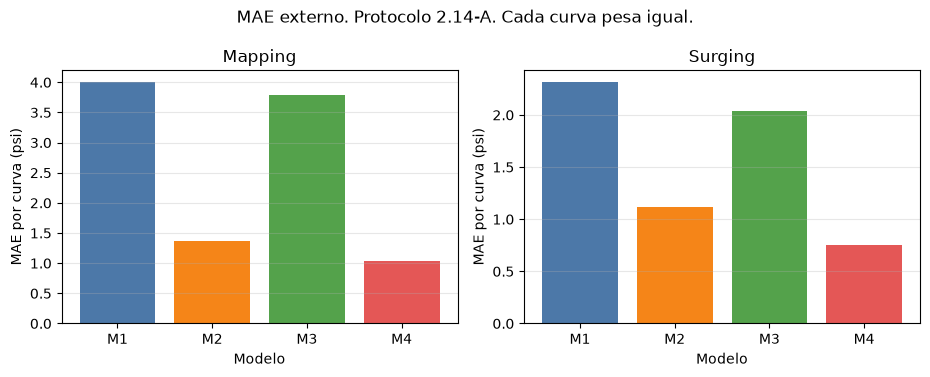

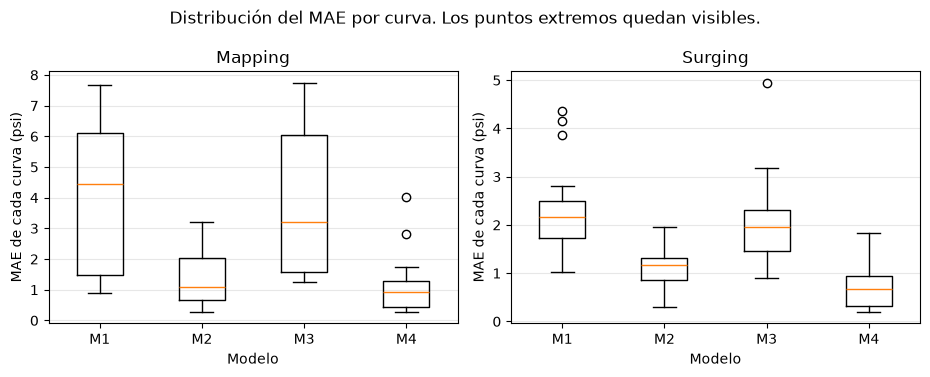

mapping M1 peor curva 150psig|3500|Qgd=0.01 7.666 media sin ella 3.872
mapping M2 peor curva 50psig|3500|Single Phase 3.221 media sin ella 1.3
mapping M3 peor curva 150psig|3500|Qgd=0.01 7.743 media sin ella 3.647
mapping M4 peor curva 50psig|3500|Single Phase 4.023 media sin ella 0.941
surging M1 peor curva 150psig|1800|0.75Qbep 4.354 media sin ella 2.192
surging M2 peor curva 100psig|3500|Qbep 1.952 media sin ella 1.064
surging M3 peor curva 150psig|1800|0.75Qbep 4.946 media sin ella 1.87
surging M4 peor curva 50psig|3500|1.25Qbep 1.837 media sin ella 0.69


In [27]:
filas = []
maes = {}
for protocolo, pred in (("mapping", prediccion_mapping), ("surging", prediccion_surging)):
    maes[protocolo] = {}
    for modelo, columna in COLUMNAS.items():
        serie = mae_por_curva(pred, columna)
        maes[protocolo][modelo] = serie
        filas.append(
            {
                "protocolo": protocolo,
                "modelo": modelo,
                "mae_psi": float(serie.mean()),
                "rmse_psi": rmse_por_curva(pred, columna),
                "n_curvas": int(len(serie)),
            }
        )
tabla_predictiva = pd.DataFrame(filas)
display(tabla_predictiva.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(9.4, 3.8))
for eje, protocolo in zip(ejes, ("mapping", "surging")):
    trozo = tabla_predictiva[tabla_predictiva["protocolo"].eq(protocolo)]
    eje.bar(trozo["modelo"], trozo["mae_psi"], color=["#4c78a8", "#f58518", "#54a24b", "#e45756"])
    eje.set_title(protocolo.capitalize())
    eje.set_ylabel("MAE por curva (psi)")
    eje.set_xlabel("Modelo")
    eje.grid(True, axis="y", alpha=0.3)
fig.suptitle("MAE externo. Protocolo 2.14-A. Cada curva pesa igual.")
fig.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(9.4, 3.8), sharey=False)
for eje, protocolo in zip(ejes, ("mapping", "surging")):
    datos = [maes[protocolo][modelo].to_numpy() for modelo in COLUMNAS]
    eje.boxplot(datos, tick_labels=list(COLUMNAS), showfliers=True)
    eje.set_title(protocolo.capitalize())
    eje.set_ylabel("MAE de cada curva (psi)")
    eje.set_xlabel("Modelo")
    eje.grid(True, axis="y", alpha=0.3)
fig.suptitle("Distribución del MAE por curva. Los puntos extremos quedan visibles.")
fig.tight_layout()
plt.show()
for protocolo in ("mapping", "surging"):
    for modelo, serie in maes[protocolo].items():
        extremo = dependencia_de_curvas_extremas(serie)
        print(protocolo, modelo, "peor curva", extremo["curva_peor"], round(extremo["mae_peor_psi"], 3), "media sin ella", round(extremo["sin_la_peor_psi"], 3))


### D.4. Diferencias pareadas

Para la curva i,

ΔMAE_i = MAE_i(candidato) − MAE_i(referencia).

Un valor negativo quiere decir que el candidato tiene menor error absoluto en esa curva. La media, la mediana y la desviación usan esas diferencias, no las filas.

### D.5. Bootstrap por curvas

Se fijan antes de mirar el intervalo: 10.000 réplicas, semilla 214 y un intervalo percentil del 95 % para la media de ΔMAE. Cada réplica extrae n curvas con reemplazo y conserva el emparejamiento entre modelos. No se remuestrean filas.

El intervalo describe la incertidumbre de remuestrear estas curvas. No cancela que compartan condiciones ni el hecho de que los hiperparámetros ya se eligieron en un anillo interno. No es una prueba causal.

Como sensibilidad se repite el remuestreo por conglomerados de hoja y velocidad. Hay seis conglomerados en cada protocolo. Ese intervalo es más ancho y no sustituye al principal.


,protocolo,comparacion,media_psi,mediana_psi,desviacion_psi,inferior_psi,superior_psi,mejoran,empeoran,n_curvas,fraccion_medias_negativas,p_wilcoxon,cong_inferior_psi,cong_superior_psi
0,mapping,M2 menos M1,-2.634,-2.883,1.745,-3.254,-2.015,29,1,30,1.000,0.000,-3.690,-1.337
1,mapping,M3 menos M1,-0.215,0.054,1.218,-0.676,0.168,12,18,30,0.835,0.715,-0.472,0.083
2,mapping,M3 menos M2,2.419,2.163,1.978,1.733,3.118,4,26,30,0.000,0.000,1.410,3.263
3,mapping,M4 menos M1,-2.955,-2.555,2.068,-3.694,-2.234,30,0,30,1.000,0.000,-4.149,-1.466
4,mapping,M4 menos M2,-0.321,-0.258,0.685,-0.562,-0.081,21,9,30,0.995,0.013,-0.553,-0.067
5,mapping,M4 menos M3,-2.740,-1.657,2.178,-3.513,-1.977,29,1,30,1.000,0.000,-3.713,-1.544
6,surging,M2 menos M1,-1.199,-0.902,1.025,-1.683,-0.768,17,1,18,1.000,0.000,-1.849,-0.550
7,surging,M3 menos M1,-0.271,-0.042,0.911,-0.712,0.103,9,9,18,0.909,0.417,-0.752,0.172
8,surging,M3 menos M2,0.927,0.818,1.048,0.482,1.427,5,13,18,0.000,0.002,0.280,1.702
9,surging,M4 menos M1,-1.559,-1.368,1.214,-2.120,-1.035,17,1,18,1.000,0.000,-2.227,-0.863


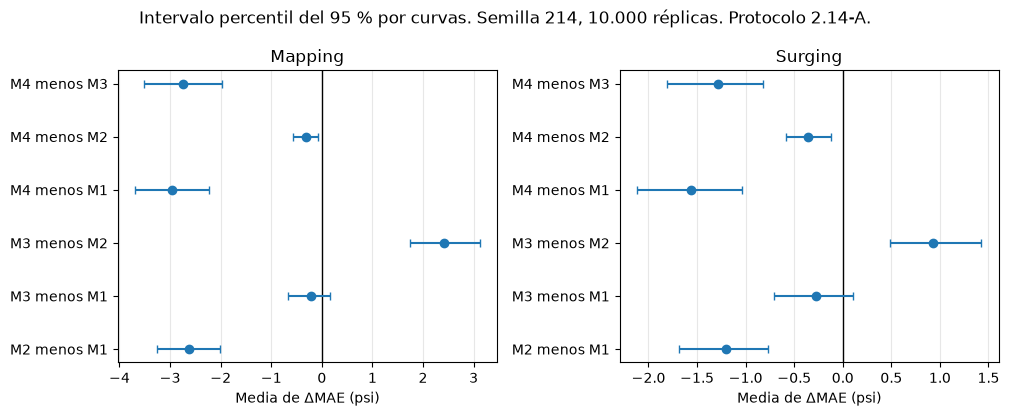

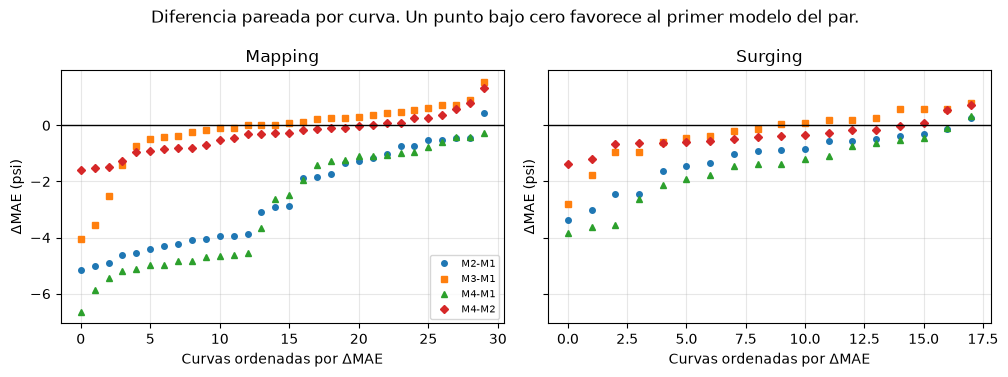

M4 menos M2 queda bajo cero en el intervalo por curvas. M3 menos M1 lo cruza.


In [28]:
filas_boot = []
deltas = {}
for protocolo, pred in (("mapping", prediccion_mapping), ("surging", prediccion_surging)):
    meta = meta_de_curvas(pred)
    conglomerado = meta["hoja"].astype(str) + "|" + meta["velocidad_rpm"].astype(str)
    for candidato, referencia in PARES:
        delta = delta_mae(maes[protocolo][referencia], maes[protocolo][candidato])
        deltas[(protocolo, f"{candidato}-{referencia}")] = delta
        principal = bootstrap_media(delta)
        sensibilidad = bootstrap_conglomerados(delta, conglomerado)
        rangos = wilcoxon_exploratorio(delta)
        filas_boot.append(
            {
                "protocolo": protocolo,
                "comparacion": f"{candidato} menos {referencia}",
                "media_psi": principal["media_psi"],
                "mediana_psi": principal["mediana_psi"],
                "desviacion_psi": principal["desviacion_psi"],
                "inferior_psi": principal["intervalo_inferior_psi"],
                "superior_psi": principal["intervalo_superior_psi"],
                "mejoran": principal["curvas_que_mejoran"],
                "empeoran": principal["curvas_que_empeoran"],
                "n_curvas": principal["n_curvas"],
                "fraccion_medias_negativas": principal["fraccion_de_medias_negativas"],
                "p_wilcoxon": rangos["p"],
                "cong_inferior_psi": sensibilidad["intervalo_inferior_psi"],
                "cong_superior_psi": sensibilidad["intervalo_superior_psi"],
            }
        )
bootstrap = pd.DataFrame(filas_boot)
display(bootstrap.round(3))
from esp_datascience.entrenamiento import guardar_derivado
guardar_derivado(bootstrap, RAIZ / "docs" / "derivados" / "intervalos_bootstrap_fase_d.csv")

fig, ejes = plt.subplots(1, 2, figsize=(10.2, 4.2), sharex=False)
for eje, protocolo in zip(ejes, ("mapping", "surging")):
    trozo = bootstrap[bootstrap["protocolo"].eq(protocolo)].reset_index(drop=True)
    eje.axvline(0, color="black", lw=1)
    eje.errorbar(
        trozo["media_psi"],
        trozo.index,
        xerr=[trozo["media_psi"] - trozo["inferior_psi"], trozo["superior_psi"] - trozo["media_psi"]],
        fmt="o",
        capsize=3,
    )
    eje.set_yticks(trozo.index, trozo["comparacion"])
    eje.set_xlabel("Media de ΔMAE (psi)")
    eje.set_title(protocolo.capitalize())
    eje.grid(True, axis="x", alpha=0.3)
fig.suptitle("Intervalo percentil del 95 % por curvas. Semilla 214, 10.000 réplicas. Protocolo 2.14-A.")
fig.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(10.2, 3.8), sharey=True)
for eje, protocolo in zip(ejes, ("mapping", "surging")):
    for nombre, marca in (("M2-M1", "o"), ("M3-M1", "s"), ("M4-M1", "^"), ("M4-M2", "D")):
        valores = deltas[(protocolo, nombre)].sort_values()
        eje.plot(range(len(valores)), valores.to_numpy(), marca, ms=4, label=nombre)
    eje.axhline(0, color="black", lw=1)
    eje.set_title(protocolo.capitalize())
    eje.set_xlabel("Curvas ordenadas por ΔMAE")
    eje.set_ylabel("ΔMAE (psi)")
    eje.grid(True, alpha=0.3)
ejes[0].legend(fontsize=7)
fig.suptitle("Diferencia pareada por curva. Un punto bajo cero favorece al primer modelo del par.")
fig.tight_layout()
plt.show()

m4_m2 = bootstrap[bootstrap["comparacion"].eq("M4 menos M2")]
m3_m1 = bootstrap[bootstrap["comparacion"].eq("M3 menos M1")]
if not bool((m4_m2["superior_psi"] < 0).all()):
    raise RuntimeError("El intervalo de M4 frente a M2 cambió de signo.")
if not bool((m3_m1["inferior_psi"] < 0).all() and (m3_m1["superior_psi"] > 0).all()):
    raise RuntimeError("El intervalo de M3 frente a M1 ya no cruza el cero.")
print("M4 menos M2 queda bajo cero en el intervalo por curvas. M3 menos M1 lo cruza.")


### D.6. Incertidumbre y supuestos

El intervalo percentil describe la incertidumbre de volver a extraer, con reemplazo, las curvas de este protocolo. Cada curva aporta una sola diferencia de MAE y el emparejamiento entre modelos se conserva. Mapping y surging no se mezclan.

Ese intervalo no demuestra, por sí mismo, independencia estadística completa, generalización a otras bombas o a otras condiciones, un mecanismo físico, ni que la elección interna de hiperparámetros haya sido inocua. Tampoco demuestra una superioridad científica fuera de este experimento.

Conviene separar tres variabilidades. Dentro de una curva, los puntos comparten el mismo ensayo y no son réplicas. Entre curvas cambia la condición, aunque pueden compartir hoja, velocidad y banco. Entre condiciones, la hoja y la velocidad agrupan varias curvas. El bootstrap principal remuestrea curvas. El de conglomerados mira la tercera escala.

En mapping, los conglomerados de 1800 rpm tienen 4 curvas y los de 3500 rpm tienen 6. Al promediar las curvas de los grupos extraídos, 3500 rpm pesa más. En surging cada conglomerado tiene 3 curvas. No se parten condiciones para fabricar más grupos ni un intervalo más estrecho.

**Seis conglomerados constituyen una base limitada para estimar incertidumbre de nivel superior.** El intervalo puede ser inestable y no es evidencia de generalización. Retirar un conglomerado completo es un diagnóstico posterior: no reajusta modelos y no es una validación externa nueva.

### Alcance inferencial y multiplicidad de comparaciones

1. Las hipótesis y los modelos se comparan de manera exploratoria.
2. Hay doce contrastes de Wilcoxon: seis pares en cada protocolo.
3. No existe una corrección confirmatoria de multiplicidad preestablecida.
4. Los valores p no se usan solos para declarar un ganador.
5. La dependencia entre curvas puede alterar la lectura convencional de esos valores.
6. Las comparaciones se limitan a las curvas y al protocolo `2.14-A`.

Las diferencias iguales a cero se excluyen del rango con signo. Como sensibilidad posterior se multiplica cada valor p por 12 y se corta en 1. Esa cuenta no sustituye los valores p originales. En M4 frente a M2, el intervalo por curvas queda bajo cero y el valor p ajustado de esta familia supera 0,05. Las dos lecturas conviven. Ninguna elige un modelo.


In [29]:
print("Diagnóstico posterior: se retira cada conglomerado de hoja y velocidad. No se reajustan modelos.")
for protocolo, pred in (("mapping", prediccion_mapping), ("surging", prediccion_surging)):
    delta = deltas[(protocolo, "M4-M2")]
    meta = meta_de_curvas(pred)
    conglomerado = (meta["hoja"].astype(str) + "|" + meta["velocidad_rpm"].astype(str)).loc[delta.index]
    retiro = diagnostico_sin_un_conglomerado(delta, conglomerado)
    print(
        protocolo,
        "M4 menos M2. El signo se conserva en",
        int(retiro["mismo_signo"].sum()),
        "de",
        len(retiro),
        "conglomerados.",
    )
    display(retiro.round(3))

familia = bootstrap["p_wilcoxon"].tolist()
ajustados = bonferroni_posterior(familia)
print("Bonferroni posterior sobre los", len(familia), "valores p de esta tabla. No es una regla de cierre.")
print(
    pd.Series(ajustados, index=bootstrap["protocolo"].str.cat(bootstrap["comparacion"], sep=" | "))
    .round(4)
    .to_string()
)
originales = bootstrap.loc[bootstrap["comparacion"].eq("M4 menos M2"), "p_wilcoxon"]
print("Los valores p originales de M4 menos M2 se conservan:", [round(float(v), 4) for v in originales])


Diagnóstico posterior: se retira cada conglomerado de hoja y velocidad. No se reajustan modelos.
mapping M4 menos M2. El signo se conserva en 6 de 6 conglomerados.


,conglomerado_retirado,n_curvas_retiradas,n_curvas_restantes,media_restante_psi,mismo_signo,caracter
0,100psig|1800,4,26,-0.358,True,diagnóstico posterior; no es una validación ex...
1,100psig|3500,6,24,-0.232,True,diagnóstico posterior; no es una validación ex...
2,150psig|1800,4,26,-0.307,True,diagnóstico posterior; no es una validación ex...
3,150psig|3500,6,24,-0.251,True,diagnóstico posterior; no es una validación ex...
4,50psig|1800,4,26,-0.353,True,diagnóstico posterior; no es una validación ex...
5,50psig|3500,6,24,-0.418,True,diagnóstico posterior; no es una validación ex...


surging M4 menos M2. El signo se conserva en 6 de 6 conglomerados.


,conglomerado_retirado,n_curvas_retiradas,n_curvas_restantes,media_restante_psi,mismo_signo,caracter
0,100psig|1800,3,15,-0.408,True,diagnóstico posterior; no es una validación ex...
1,100psig|3500,3,15,-0.329,True,diagnóstico posterior; no es una validación ex...
2,150psig|1800,3,15,-0.329,True,diagnóstico posterior; no es una validación ex...
3,150psig|3500,3,15,-0.385,True,diagnóstico posterior; no es una validación ex...
4,50psig|1800,3,15,-0.272,True,diagnóstico posterior; no es una validación ex...
5,50psig|3500,3,15,-0.438,True,diagnóstico posterior; no es una validación ex...


Bonferroni posterior sobre los 12 valores p de esta tabla. No es una regla de cierre.
protocolo
mapping | M2 menos M1    0.0000
mapping | M3 menos M1    1.0000
mapping | M3 menos M2    0.0000
mapping | M4 menos M1    0.0000
mapping | M4 menos M2    0.1540
mapping | M4 menos M3    0.0000
surging | M2 menos M1    0.0003
surging | M3 menos M1    1.0000
surging | M3 menos M2    0.0232
surging | M4 menos M1    0.0003
surging | M4 menos M2    0.1444
surging | M4 menos M3    0.0006
Los valores p originales de M4 menos M2 se conservan: [0.0128, 0.012]


### D.7. Estabilidad entre condiciones

Se tabula el MAE medio de las curvas de cada velocidad, presión, condición y pliegue. Una diferencia entre 1800 y 3500 rpm no se exporta a otra velocidad. Una diferencia entre presiones de mapping está mezclada con la procedencia de la velocidad: 50 psig es la única hoja leída en la celda.


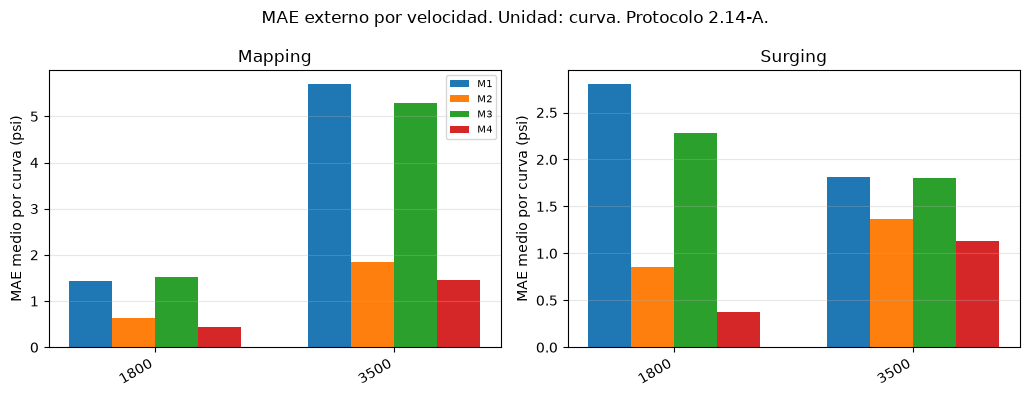

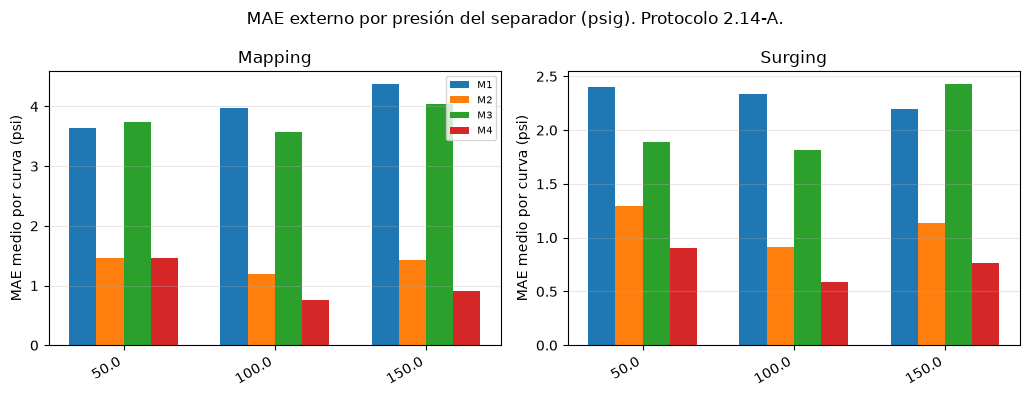

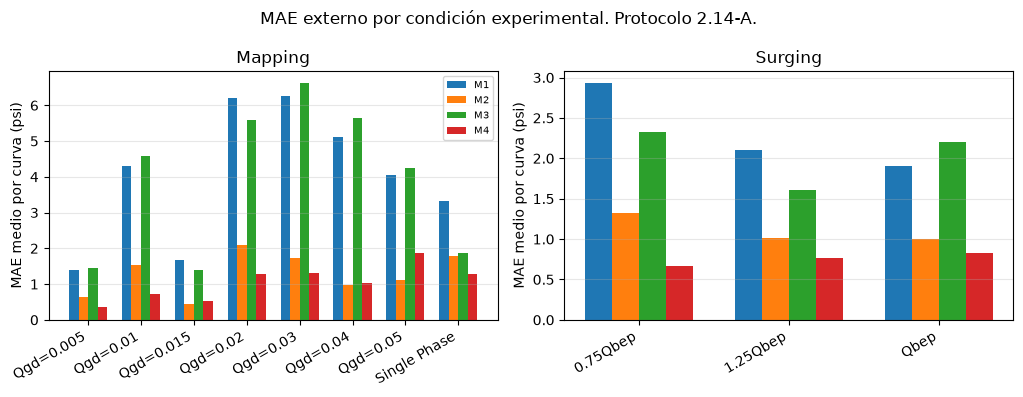

Dónde M2 tiene menor MAE que M4, por condición.
mapping


,n,m2_mejor
condicion,,
Qgd=0.005,3,0
Qgd=0.01,6,0
Qgd=0.015,3,2
Qgd=0.02,3,0
Qgd=0.03,3,1
Qgd=0.04,3,2
Qgd=0.05,3,3
Single Phase,6,1


surging


,n,m2_mejor
condicion,,
0.75Qbep,6,1
1.25Qbep,6,1
Qbep,6,1


In [30]:
def barras_por(columna_grupo, titulo, ylabel="MAE medio por curva (psi)"):
    fig, ejes = plt.subplots(1, 2, figsize=(10.4, 4.0))
    for eje, protocolo, pred in zip(ejes, ("mapping", "surging"), (prediccion_mapping, prediccion_surging)):
        meta = meta_de_curvas(pred)
        ancho = 0.18
        niveles = list(meta[columna_grupo].drop_duplicates().sort_values())
        posiciones = list(range(len(niveles)))
        for i, (modelo, serie) in enumerate(maes[protocolo].items()):
            tabla = tabla_por_grupo(serie, meta, columna_grupo).set_index(columna_grupo)
            valores = [float(tabla.loc[nivel, "mae_medio"]) if nivel in tabla.index else np.nan for nivel in niveles]
            eje.bar([p + (i - 1.5) * ancho for p in posiciones], valores, width=ancho, label=modelo)
        eje.set_xticks(posiciones, [str(nivel) for nivel in niveles], rotation=30, ha="right")
        eje.set_title(protocolo.capitalize())
        eje.set_ylabel(ylabel)
        eje.grid(True, axis="y", alpha=0.3)
    ejes[0].legend(fontsize=7)
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()

barras_por("velocidad_rpm", "MAE externo por velocidad. Unidad: curva. Protocolo 2.14-A.")
barras_por("psep_psig", "MAE externo por presión del separador (psig). Protocolo 2.14-A.")
barras_por("condicion", "MAE externo por condición experimental. Protocolo 2.14-A.")
print("Dónde M2 tiene menor MAE que M4, por condición.")
for protocolo in ("mapping", "surging"):
    delta = delta_mae(maes[protocolo]["M4"], maes[protocolo]["M2"])
    meta = meta_de_curvas(prediccion_mapping if protocolo == "mapping" else prediccion_surging).loc[delta.index].copy()
    meta["m2_mejor"] = delta < 0
    resumen = meta.groupby("condicion").agg(n=("m2_mejor", "size"), m2_mejor=("m2_mejor", "sum"))
    print(protocolo)
    display(resumen)


### D.8. Consistencia física

Una predicción negativa no se declara imposible en toda circunstancia. En este archivo las mediciones son positivas, así que una predicción negativa es un valor que el experimento no mostró. No se sustituye por cero.

### D.9. Diagnóstico de curvas monofásicas

Las seis curvas de agua bajan al ordenarlas por caudal. Spearman igual a −1 dice que el orden de la presión es el inverso del caudal. La subida punto a punto cuenta los pasos que, aun así, aumentan. M5 no predice estas curvas.


Predicciones negativas. El mínimo es el de toda la predicción externa, no solo el de las filas negativas.
mapping


,modelo,n_predicciones,n_curvas,minimo_psi,maximo_psi,medicion_minima_en_filas_negativas_psi,medicion_maxima_en_filas_negativas_psi
0,M1,1,1,-0.207,27.396,0.353,0.353
1,M2,22,21,-7.292,30.624,0.147,1.862
2,M3,4,3,-1.897,39.769,0.345,1.932
3,M4,0,0,0.451,28.706,NaN,NaN


surging


,modelo,n_predicciones,n_curvas,minimo_psi,maximo_psi,medicion_minima_en_filas_negativas_psi,medicion_maxima_en_filas_negativas_psi
0,M1,34,8,-8.184,29.007,0.383,2.290
1,M2,12,5,-6.230,31.908,0.383,2.518
2,M3,27,8,-13.993,30.747,0.383,2.626
3,M4,0,0,1.227,27.474,NaN,NaN


,curva_id,n_puntos,subidas_medicion,subidas_M1,mayor_subida_M1,spearman_M1,subidas_M2,mayor_subida_M2,spearman_M2,subidas_M3,mayor_subida_M3,spearman_M3,subidas_M4,mayor_subida_M4,spearman_M4
0,100psig|1800|Single Phase,9,0,0,-0.489,-1.0,1,0.251,-0.950,0,-1.480,-1.0,1,0.051,-0.983
1,100psig|3500|Single Phase,18,0,0,-0.495,-1.0,3,1.020,-0.913,0,-1.349,-1.0,1,0.759,-0.979
2,150psig|1800|Single Phase,10,0,0,-0.392,-1.0,2,0.441,-0.915,0,-1.070,-1.0,2,2.275,-0.806
3,150psig|3500|Single Phase,19,0,0,-0.340,-1.0,5,1.105,-0.849,0,-1.034,-1.0,1,1.739,-0.963
4,50psig|1800|Single Phase,10,0,0,-0.426,-1.0,2,0.621,-0.842,0,-1.297,-1.0,2,4.054,-0.733
5,50psig|3500|Single Phase,21,0,0,-0.437,-1.0,7,5.248,-0.655,0,-1.323,-1.0,4,11.291,-0.549


M1 nota de subidas de agua 3
M2 nota de subidas de agua 1
M3 nota de subidas de agua 3
M4 nota de subidas de agua 0


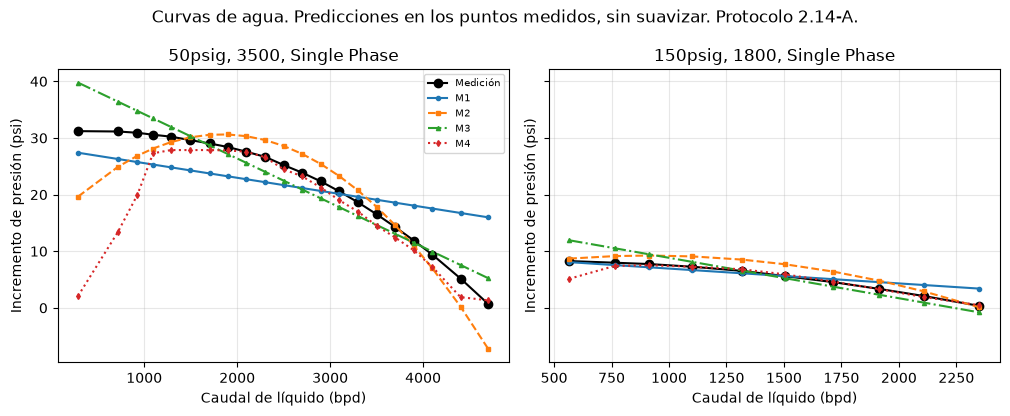

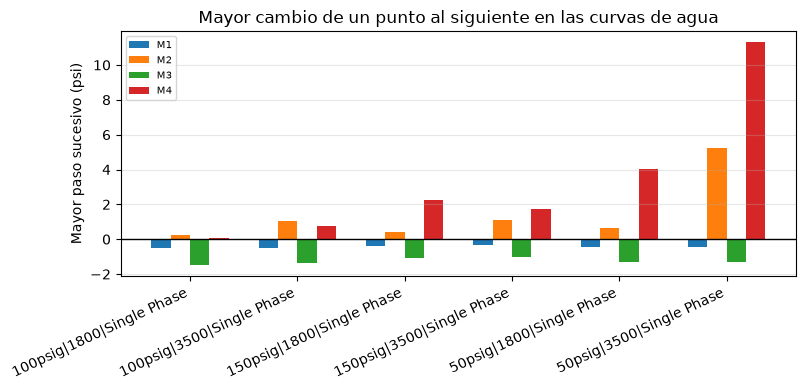

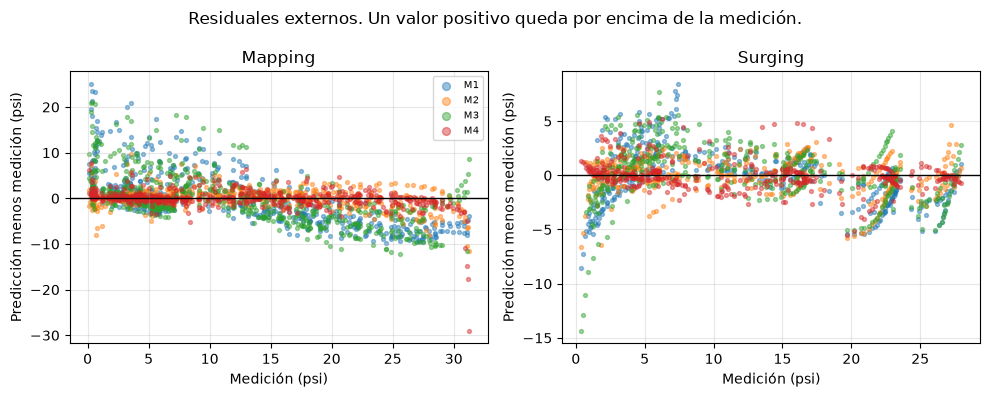

In [31]:
print("Predicciones negativas. El mínimo es el de toda la predicción externa, no solo el de las filas negativas.")
for protocolo, pred in (("mapping", prediccion_mapping), ("surging", prediccion_surging)):
    filas = [resumen_negativas(pred, columna, modelo) for modelo, columna in COLUMNAS.items()]
    print(protocolo)
    display(pd.DataFrame(filas).round(3))

agua = monotonía_de_agua(prediccion_mapping, COLUMNAS)
display(agua.round(3))
for modelo in COLUMNAS:
    print(modelo, "nota de subidas de agua", puntuacion_de_agua(agua, modelo))

fig, ejes = plt.subplots(1, 2, figsize=(10.2, 4.2), sharey=True)
for eje, curva in zip(ejes, ("50psig|3500|Single Phase", "150psig|1800|Single Phase")):
    grupo = prediccion_mapping[prediccion_mapping["curva_id"].eq(curva)].sort_values("abscisa")
    eje.plot(grupo["abscisa"], grupo["medicion"], "o-", color="black", label="Medición")
    for modelo, columna, estilo in (
        ("M1", "prediccion_m1", "-o"),
        ("M2", "prediccion_m2", "--s"),
        ("M3", "prediccion_m3", "-.^"),
        ("M4", "prediccion_m4", ":d"),
    ):
        eje.plot(grupo["abscisa"], grupo[columna], estilo, ms=3, label=modelo)
    eje.set_title(curva.replace("|", ", "))
    eje.set_xlabel("Caudal de líquido (bpd)")
    eje.set_ylabel("Incremento de presión (psi)")
    eje.grid(True, alpha=0.3)
ejes[0].legend(fontsize=7)
fig.suptitle("Curvas de agua. Predicciones en los puntos medidos, sin suavizar. Protocolo 2.14-A.")
fig.tight_layout()
plt.show()

fig, eje = plt.subplots(figsize=(8.2, 4.0))
indice = agua["curva_id"]
ancho = 0.18
for i, modelo in enumerate(COLUMNAS):
    eje.bar([p + (i - 1.5) * ancho for p in range(len(agua))], agua[f"mayor_subida_{modelo}"], width=ancho, label=modelo)
eje.axhline(0, color="black", lw=1)
eje.set_xticks(range(len(agua)), agua["curva_id"], rotation=25, ha="right")
eje.set_ylabel("Mayor paso sucesivo (psi)")
eje.set_title("Mayor cambio de un punto al siguiente en las curvas de agua")
eje.legend(fontsize=7)
eje.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(10.0, 4.0))
for eje, protocolo, pred in zip(ejes, ("mapping", "surging"), (prediccion_mapping, prediccion_surging)):
    for modelo, columna in COLUMNAS.items():
        eje.scatter(pred["medicion"], pred[columna] - pred["medicion"], s=8, alpha=0.45, label=modelo)
    eje.axhline(0, color="black", lw=1)
    eje.set_title(protocolo.capitalize())
    eje.set_xlabel("Medición (psi)")
    eje.set_ylabel("Predicción menos medición (psi)")
    eje.grid(True, alpha=0.3)
ejes[0].legend(fontsize=7, markerscale=2)
fig.suptitle("Residuales externos. Un valor positivo queda por encima de la medición.")
fig.tight_layout()
plt.show()


### D.10. Comportamiento con gas

En mapping se interpola cada curva en el centro del caudal de líquido común a esa hoja y esa velocidad. La interpolación no sale del tramo medido y no entra al ajuste. Si la serie sube al aumentar Qgd, el paso queda contado. No es una ley del gas.

En surging, dentro de cada curva, se mira el Spearman entre GVF0 y el incremento de presión. Un valor de −1 es una caída estricta en el orden. No identifica un régimen.


,hoja,velocidad_rpm,serie,n_pasos,pasos_que_suben,es_prediccion_original
0,100psig,1800,medicion,2,0,False
1,100psig,1800,M1,2,0,False
2,100psig,1800,M2,2,0,False
3,100psig,1800,M3,2,0,False
4,100psig,1800,M4,2,0,False
5,100psig,3500,medicion,4,0,False
6,100psig,3500,M1,4,0,False
7,100psig,3500,M2,4,0,False
8,100psig,3500,M3,4,1,False
9,100psig,3500,M4,4,0,False


Grupos de hoja y velocidad en los que la serie sube al aumentar Qgd:
serie
M1          0
M2          0
M3          5
M4          1
medicion    0


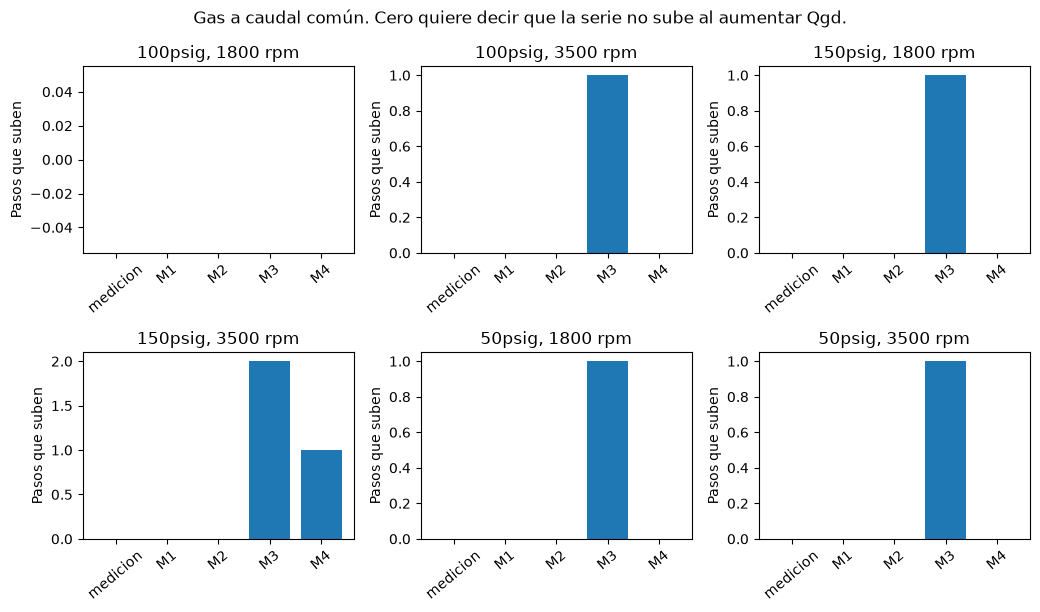

Surging. Peor Spearman de GVF0 con la presión, dentro de cada curva.
M1 peor -1.0 nota 3 curvas bajo −0,99 18
M2 peor -1.0 nota 3 curvas bajo −0,99 18
M3 peor -1.0 nota 3 curvas bajo −0,99 18
M4 peor -0.9766 nota 2 curvas bajo −0,99 15


In [32]:
gas = subidas_en_caudal_comun(prediccion_mapping, COLUMNAS)
display(gas)
conteo = gas.groupby("serie")["pasos_que_suben"].apply(lambda serie: int((serie > 0).sum()))
print("Grupos de hoja y velocidad en los que la serie sube al aumentar Qgd:")
print(conteo.to_string())

fig, ejes = plt.subplots(2, 3, figsize=(10.5, 6.2), sharey=False)
for eje, ((hoja, velocidad), bloque) in zip(ejes.ravel(), gas.groupby(["hoja", "velocidad_rpm"], sort=True)):
    eje.bar(bloque["serie"], bloque["pasos_que_suben"])
    eje.set_title(f"{hoja}, {int(velocidad)} rpm")
    eje.tick_params(axis="x", rotation=40)
    eje.set_ylabel("Pasos que suben")
fig.suptitle("Gas a caudal común. Cero quiere decir que la serie no sube al aumentar Qgd.")
fig.tight_layout()
plt.show()

print("Surging. Peor Spearman de GVF0 con la presión, dentro de cada curva.")
for modelo, columna in COLUMNAS.items():
    valores = [
        float(spearmanr(grupo["abscisa"], grupo[columna]).statistic)
        for _, grupo in prediccion_surging.groupby("curva_id")
    ]
    peor = max(valores)
    print(modelo, "peor", round(peor, 4), "nota", puntuacion_por_spearman(peor), "curvas bajo −0,99", sum(v < -0.99 for v in valores))


### D.11. Sensibilidad al origen de la velocidad

En mapping, `celda` y `diseño_experimental` no se cruzan con la presión. Las 186 filas leídas en la celda son las de 50 psig. Las 384 de diseño son las de 100 y 150 psig. Cada curva tiene una sola procedencia, la de su hoja.

Por eso un MAE distinto entre los dos orígenes es, en estas tablas, el mismo contraste que entre 50 psig y las otras dos presiones. No se puede leer como efecto de haber asignado la velocidad. No se reajusta un modelo solo con 50 psig: esa cuenta cambiaría el dominio del protocolo `2.14-A`, que exige las tres presiones. La tercera condición de la regla de superioridad de 2.13 queda, aquí, como no evaluable.


,hoja,origen_velocidad,psep_psig,n_filas,n_curvas
0,100psig,diseño_experimental,100.0,192,10
1,150psig,diseño_experimental,150.0,192,10
2,50psig,celda,50.0,186,10


MAE por curva según la procedencia. La procedencia coincide con la hoja.
M1


,size,mean,max
origen_velocidad,,,
celda,10,3.644,6.824
diseño_experimental,20,4.176,7.666


M2


,size,mean,max
origen_velocidad,,,
celda,10,1.466,3.221
diseño_experimental,20,1.314,2.527


M3


,size,mean,max
origen_velocidad,,,
celda,10,3.737,7.548
diseño_experimental,20,3.807,7.743


M4


,size,mean,max
origen_velocidad,,,
celda,10,1.463,4.023
diseño_experimental,20,0.834,1.570


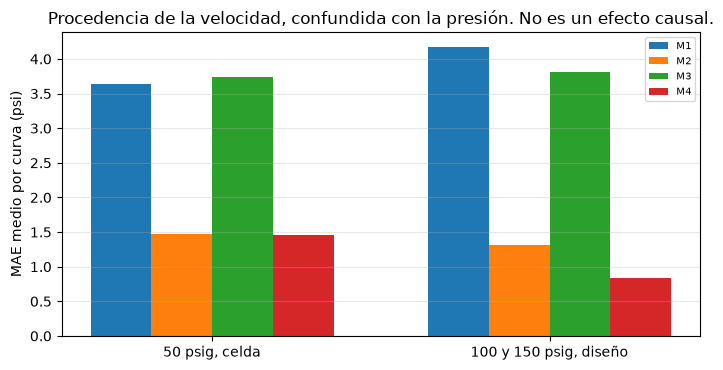

In [33]:
origen = origen_de_velocidad(mapping)
display(origen)
hoja_a_origen = origen.set_index("hoja")["origen_velocidad"]
meta = meta_de_curvas(prediccion_mapping)
meta["origen_velocidad"] = meta["hoja"].map(hoja_a_origen)
print("MAE por curva según la procedencia. La procedencia coincide con la hoja.")
for modelo, serie in maes["mapping"].items():
    marco = meta.loc[serie.index].copy()
    marco["mae"] = serie
    print(modelo)
    display(marco.groupby("origen_velocidad")["mae"].agg(["size", "mean", "max"]).round(3))

fig, eje = plt.subplots(figsize=(7.2, 3.8))
origenes = ["celda", "diseño_experimental"]
ancho = 0.18
for i, (modelo, serie) in enumerate(maes["mapping"].items()):
    marco = meta.loc[serie.index].copy()
    marco["mae"] = serie
    medias = marco.groupby("origen_velocidad")["mae"].mean()
    eje.bar([p + (i - 1.5) * ancho for p in range(2)], [float(medias[nombre]) for nombre in origenes], width=ancho, label=modelo)
eje.set_xticks([0, 1], ["50 psig, celda", "100 y 150 psig, diseño"])
eje.set_ylabel("MAE medio por curva (psi)")
eje.set_title("Procedencia de la velocidad, confundida con la presión. No es un efecto causal.")
eje.legend(fontsize=7)
eje.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()
if set(origen.loc[origen["psep_psig"].eq(50), "origen_velocidad"]) != {"celda"}:
    raise RuntimeError("La hoja de 50 psig ya no es solo velocidad de celda.")


### D.12. Análisis multicriterio

Hay dos instrumentos distintos.

La matriz de 2.13 se escribió antes de entrenar. Sus pesos eran 25 % compatibilidad, 25 % fundamento físico, 20 % forma observada, 15 % validación, 10 % interpretabilidad y 5 % simplicidad de cómputo. Medían si una familia se podía plantear con estas tablas. Con esos pesos no hubo un candidato predictivo principal único. Esos pesos no se reescriben con el MAE.

La matriz de esta sección es una propuesta posterior de la fase D. Sus notas y sus cortes se fijaron después de ver los errores. No estaba registrada en `2.14-A`. Si el primer puesto cambia, la propuesta no elige un modelo.

| Criterio | Qué mide | Por qué importa aquí | Unidad | Cómo pasa a nota | Qué se pierde | Carácter | Cuándo |
|---|---|---|---|---|---|---|---|
| Precisión | Puesto del MAE por curva | Cercanía al incremento medido, en psi | psi, luego puesto 3 a 0 | El menor MAE recibe 3 | El tamaño de la diferencia | Convención sobre una métrica objetiva | Después del error |
| Robustez | Fracción de curvas con menor MAE que M1 | Si la mejora aparece en muchas curvas | Fracción, por 3 | Escala lineal a 03 | La magnitud de cada mejora | Convención | Después del error |
| Agua | Pasos ascendentes y mayor subida local | Las seis curvas de agua medidas bajan con el caudal | psi y número de pasos, luego 0 a 3 | 0 pasos: 3. Subida máxima ? 10 psi: 0. ? 1 psi: 1. Si no: 2 | El valor continuo del paso | Decisión del investigador | Después de ver los pasos |
| Negativas | Cantidad y mínimo de predicciones bajo cero | En estos archivos el incremento medido es positivo | psi, luego 0 a 3 | Ninguna: 3. Mínimo ? ?5 psi: 0. ? ?1 psi: 1. Si no: 2 | Dónde y en qué curva ocurre | Decisión del investigador | Después de ver los mínimos |
| Gas | Subidas al aumentar Qgd, o el peor Spearman con GVF0 | A velocidad y presión fijas, la hipótesis de 2.13 pedía no ver un alza sistemática con el gas | Pasos o Spearman, luego 0 a 3 | Mapping: 0 grupos: 3; uno: 2; hasta tres: 1. Surging: cortes ?0,999, ?0,95 y ?0,90 | La serie continua | Decisión del investigador | Después de ver las series |
| Lectura | Si la ecuación se puede leer | Una recta se explica; un bosque de cortes, no | Nota 0 a 3 fijada por la forma | M1: 3. M3: 2. M2: 1. M4: 0 | No usa el error | Criterio a priori de forma | Por la definición del modelo |
| Simplicidad | Complejidad invertida de esa forma | Menos términos libres, más lectura directa | La misma escala | Igual que la lectura | No usa el error | Criterio a priori de forma | Por la definición del modelo |

Los cortes de 1 psi y de 10 psi no son límites físicos universales. No hay en este estudio una referencia independiente que los fije. El de 10 psi queda entre el paso mayor de M2 (5,248 psi) y el de M4 (11,291 psi). Por eso la nota discreta separa a esos dos modelos. Los escenarios de 5 psi y de 15 psi son análisis posteriores, con cortes redondos, y no sustituyen la subida continua.

En surging no existe la columna de agua. Esos pesos se omiten y el resto se reescala. La suma ya no es la de mapping. Las dos tablas no se leen como si tuvieran la misma ponderación efectiva.


Mapping. Propuesta de la fase D, no regla de 2.13.


,precision,robustez,negativas,gas,lectura,simplicidad,agua
M4,3,3.0,3,2,0,0,0
M2,2,2.9,0,3,1,1,1
M3,1,1.2,1,0,2,2,3
M1,0,0.0,2,3,3,3,3


          ponderacion primero segundo  puntuacion_primero
          equilibrado      M1      M4            2.000000
            precision      M4      M2            2.090909
  tendencia_observada      M1      M3            2.384615
lectura_y_simplicidad      M1      M3            2.461538
Surging. No hay nota de agua: el criterio no existe en ese protocolo.


,precision,robustez,negativas,gas,lectura,simplicidad
M4,3,2.83,3,2,0,0
M2,2,2.83,0,3,1,1
M3,1,1.50,0,3,2,2
M1,0,0.00,0,3,3,3


          ponderacion primero segundo  puntuacion_primero
          equilibrado      M4      M2            1.805556
            precision      M4      M2            2.266667
  tendencia_observada      M4      M2            1.981481
lectura_y_simplicidad      M1      M3            2.250000


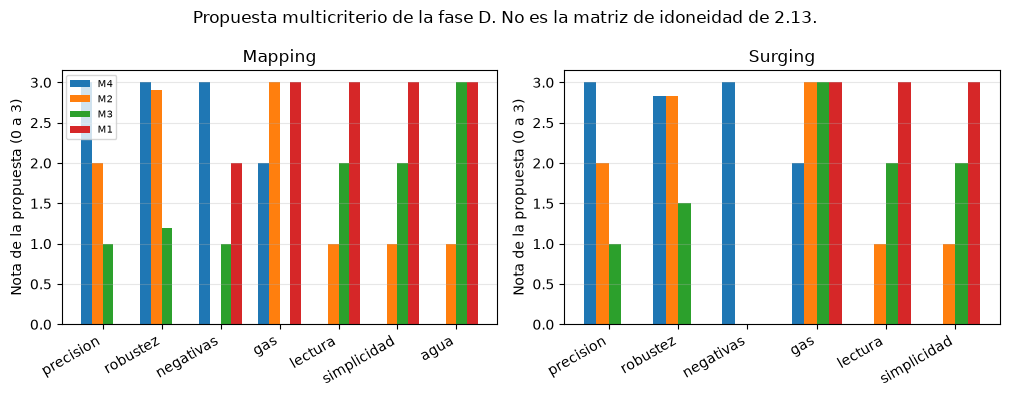

El primer puesto cambia con la ponderación. La propuesta no cierra la selección.
M5, solo en sus cinco curvas completas. No se compara con el MAE de las treinta.


,modelo,n_curvas_cubiertas,n_filas_en_el_mae,mae_curva,rmse_curva,sesgo_curva
0,M1,5,89,3.080,3.734,-0.423
1,M2,5,89,1.048,1.290,-0.101
2,M3,5,89,3.381,4.043,0.235
3,M4,5,89,1.206,1.500,0.607
4,M5,5,89,2.078,2.885,0.204


In [34]:
def notas_de(protocolo, incluir_agua):
    serie_mae = maes[protocolo]
    orden = sorted(serie_mae, key=lambda modelo: float(serie_mae[modelo].mean()))
    precision = {modelo: 3 - puesto for puesto, modelo in enumerate(orden)}
    robustez = {"M1": 0.0}
    for modelo, serie in serie_mae.items():
        if modelo == "M1":
            continue
        delta = delta_mae(serie_mae["M1"], serie)
        robustez[modelo] = 3.0 * float((delta < 0).mean())
    pred = prediccion_mapping if protocolo == "mapping" else prediccion_surging
    negativas = {
        modelo: puntuacion_de_negativas(resumen_negativas(pred, columna, modelo))
        for modelo, columna in COLUMNAS.items()
    }
    if protocolo == "mapping":
        gas = {
            "M1": puntuacion_por_subidas_de_gas(int(conteo["M1"])),
            "M2": puntuacion_por_subidas_de_gas(int(conteo["M2"])),
            "M3": puntuacion_por_subidas_de_gas(int(conteo["M3"])),
            "M4": puntuacion_por_subidas_de_gas(int(conteo["M4"])),
        }
        agua_nota = {modelo: puntuacion_de_agua(agua, modelo) for modelo in COLUMNAS}
    else:
        peores = {}
        for modelo, columna in COLUMNAS.items():
            valores = [
                float(spearmanr(grupo["abscisa"], grupo[columna]).statistic)
                for _, grupo in pred.groupby("curva_id")
            ]
            peores[modelo] = puntuacion_por_spearman(max(valores))
        gas = peores
        agua_nota = None
    from esp_datascience.fase_d import COMPLEJIDAD_INVERTIDA, LECTURA_A_PRIORI
    marco = pd.DataFrame(
        {
            "precision": precision,
            "robustez": robustez,
            "negativas": negativas,
            "gas": gas,
            "lectura": {modelo: LECTURA_A_PRIORI[modelo] for modelo in COLUMNAS},
            "simplicidad": {modelo: COMPLEJIDAD_INVERTIDA[modelo] for modelo in COLUMNAS},
        }
    )
    if incluir_agua:
        marco["agua"] = agua_nota
    return marco

notas_mapping = notas_de("mapping", True)
notas_surging = notas_de("surging", False)
print("Mapping. Propuesta de la fase D, no regla de 2.13.")
display(notas_mapping.round(2))
print(primeros_por_ponderacion(notas_mapping).to_string(index=False))
print("Surging. No hay nota de agua: el criterio no existe en ese protocolo.")
display(notas_surging.round(2))
print(primeros_por_ponderacion(notas_surging).to_string(index=False))

fig, ejes = plt.subplots(1, 2, figsize=(10.2, 4.0))
for eje, notas, titulo in (
    (ejes[0], notas_mapping, "Mapping"),
    (ejes[1], notas_surging, "Surging"),
):
    ancho = 0.18
    criterios = list(notas.columns)
    for i, modelo in enumerate(notas.index):
        eje.bar([p + (i - 1.5) * ancho for p in range(len(criterios))], notas.loc[modelo], width=ancho, label=modelo)
    eje.set_xticks(range(len(criterios)), criterios, rotation=30, ha="right")
    eje.set_ylabel("Nota de la propuesta (0 a 3)")
    eje.set_title(titulo)
    eje.grid(True, axis="y", alpha=0.3)
ejes[0].legend(fontsize=7)
fig.suptitle("Propuesta multicriterio de la fase D. No es la matriz de idoneidad de 2.13.")
fig.tight_layout()
plt.show()
if primeros_por_ponderacion(notas_mapping)["primero"].nunique() < 2:
    raise RuntimeError("En mapping todas las ponderaciones eligieron el mismo modelo.")
if primeros_por_ponderacion(notas_surging)["primero"].nunique() < 2:
    raise RuntimeError("En surging todas las ponderaciones eligieron el mismo modelo.")
print("El primer puesto cambia con la ponderación. La propuesta no cierra la selección.")

curvas_m5 = list(m5["mae_por_curva"].index)
sub = prediccion_mapping[prediccion_mapping["curva_id"].isin(curvas_m5)].copy()
sub["prediccion_m5"] = m5["predicciones"].loc[sub.index, "prediccion_m5"]
print("M5, solo en sus cinco curvas completas. No se compara con el MAE de las treinta.")
display(
    pd.DataFrame(
        [
            metricas_de_columna(sub, columna, "mapping", modelo)
            for modelo, columna in (*COLUMNAS.items(), ("M5", "prediccion_m5"))
        ]
    )[["modelo", "n_curvas_cubiertas", "n_filas_en_el_mae", "mae_curva", "rmse_curva", "sesgo_curva"]].round(3)
)


### D.12.1. Sensibilidad posterior de umbrales y de pesos

Los escenarios siguientes no estaban en el protocolo. Sirven para ver si el primer puesto depende del corte o del peso. La subida en psi, el mínimo negativo y el MAE siguen siendo las cifras continuas.


In [35]:
from esp_datascience.fase_d import (
    CARACTER_DE_LA_PONDERACION,
    CARACTER_DE_LOS_UMBRALES,
    PESOS_SENSIBILIDAD,
    SENTIDO_DE_LAS_PONDERACIONES,
)

print(CARACTER_DE_LOS_UMBRALES)
print("La subida continua no cambia. Cambia solo la nota discreta.")
display(notas_de_agua_bajo_umbrales(agua).pivot(index="modelo", columns="escenario", values="nota"))
resumenes = [resumen_negativas(prediccion_mapping, columna, modelo) for modelo, columna in COLUMNAS.items()]
display(notas_de_negativas_bajo_umbrales(resumenes).pivot(index="modelo", columns="escenario", values="nota"))
print("Gas en mapping. El modo binario, cualquier subida anula la nota alta, es posterior.")
for modelo in COLUMNAS:
    print(
        modelo,
        "escalonado",
        puntuacion_por_subidas_de_gas(int(conteo[modelo])),
        "binario",
        puntuacion_por_subidas_de_gas(int(conteo[modelo]), modo="binario"),
    )

print(CARACTER_DE_LA_PONDERACION)
for nombre, pesos in PESOS_SENSIBILIDAD.items():
    print(nombre + ":", SENTIDO_DE_LAS_PONDERACIONES[nombre])
    print("  pesos escritos", pesos)
    print("  mapping", {k: round(v, 3) for k, v in pesos_efectivos(pesos, notas_mapping.columns)["pesos_renormalizados"].items()})
    sur = pesos_efectivos(pesos, notas_surging.columns)
    print("  surging omite", sur["omitidos"], "y reescala", {k: round(v, 3) for k, v in sur["pesos_renormalizados"].items()})

print("Puestos completos. Mapping.")
display(detalle_de_ponderacion(notas_mapping).round(3))
print("Puestos completos. Surging, sin criterio de agua.")
display(detalle_de_ponderacion(notas_surging).round(3))


def primeros_si_cambia_agua(escenario):
    copia = notas_mapping.copy()
    trozo = notas_de_agua_bajo_umbrales(agua)
    copia["agua"] = trozo[trozo["escenario"].eq(escenario)].set_index("modelo")["nota"]
    return primeros_por_ponderacion(copia)


print("El primer puesto de mapping al mover solo los cortes del agua.")
for escenario in ("publicado", "mas_estricto", "mas_holgado"):
    print(escenario)
    print(primeros_si_cambia_agua(escenario).to_string(index=False))

resumenes_surging = [resumen_negativas(prediccion_surging, columna, modelo) for modelo, columna in COLUMNAS.items()]
notas_neg_surg = notas_de_negativas_bajo_umbrales(resumenes_surging)
print("Notas de predicciones negativas en surging. El corte holgado es posterior y no se adopta.")
display(notas_neg_surg.pivot(index="modelo", columns="escenario", values="nota"))
copia_surg = notas_surging.copy()
copia_surg["negativas"] = notas_neg_surg[notas_neg_surg["escenario"].eq("mas_holgado")].set_index("modelo")["nota"]
from esp_datascience.fase_d import ranking_con_pesos
print("Surging con el corte holgado. Si las dos primeras notas coinciden, no hay un nuevo ganador.")
for nombre, pesos in PESOS_SENSIBILIDAD.items():
    orden = ranking_con_pesos(copia_surg, pesos)
    empate = abs(float(orden.iloc[0]) - float(orden.iloc[1])) < 1e-9
    print(nombre, orden.index[0], round(float(orden.iloc[0]), 6), orden.index[1], round(float(orden.iloc[1]), 6), "empate" if empate else "separados")


análisis posterior; no es un límite físico ni un protocolo preestablecido
La subida continua no cambia. Cambia solo la nota discreta.


escenario,mas_estricto,mas_holgado,publicado
modelo,,,
M1,3,3,3
M2,0,1,1
M3,3,3,3
M4,0,1,0


escenario,mas_estricto,mas_holgado,publicado
modelo,,,
M1,2,2,2
M2,0,1,0
M3,1,2,1
M4,3,3,3


Gas en mapping. El modo binario, cualquier subida anula la nota alta, es posterior.
M1 escalonado 3 binario 3
M2 escalonado 3 binario 3
M3 escalonado 0 binario 0
M4 escalonado 2 binario 0
Propuesta posterior de la fase D. No es la matriz de 2.13 y no cierra la selección.
equilibrado: Cada criterio presente pesa igual.
  pesos escritos {'precision': 1, 'robustez': 1, 'agua': 1, 'negativas': 1, 'gas': 1, 'lectura': 1, 'simplicidad': 1}
  mapping {'precision': 0.143, 'robustez': 0.143, 'agua': 0.143, 'negativas': 0.143, 'gas': 0.143, 'lectura': 0.143, 'simplicidad': 0.143}
  surging omite ['agua'] y reescala {'precision': 0.167, 'robustez': 0.167, 'negativas': 0.167, 'gas': 0.167, 'lectura': 0.167, 'simplicidad': 0.167}
precision: Prioriza el puesto por MAE y, en menor grado, la fracción de curvas que mejoran a M1.
  pesos escritos {'precision': 4, 'robustez': 2, 'agua': 1, 'negativas': 1, 'gas': 1, 'lectura': 1, 'simplicidad': 1}
  mapping {'precision': 0.364, 'robustez': 0.182, 'agua': 

,ponderacion,modelo,puesto,puntuacion,criterios_omitidos,caracter
0,equilibrado,M1,1,2.000,,Propuesta posterior de la fase D. No es la mat...
1,equilibrado,M4,2,1.571,,Propuesta posterior de la fase D. No es la mat...
2,equilibrado,M2,3,1.557,,Propuesta posterior de la fase D. No es la mat...
3,equilibrado,M3,4,1.457,,Propuesta posterior de la fase D. No es la mat...
4,precision,M4,1,2.091,,Propuesta posterior de la fase D. No es la mat...
5,precision,M2,2,1.800,,Propuesta posterior de la fase D. No es la mat...
6,precision,M3,3,1.309,,Propuesta posterior de la fase D. No es la mat...
7,precision,M1,4,1.273,,Propuesta posterior de la fase D. No es la mat...
8,tendencia_observada,M1,1,2.385,,Propuesta posterior de la fase D. No es la mat...
9,tendencia_observada,M3,2,1.554,,Propuesta posterior de la fase D. No es la mat...


Puestos completos. Surging, sin criterio de agua.


,ponderacion,modelo,puesto,puntuacion,criterios_omitidos,caracter
0,equilibrado,M4,1,1.806,agua,Propuesta posterior de la fase D. No es la mat...
1,equilibrado,M2,2,1.639,agua,Propuesta posterior de la fase D. No es la mat...
2,equilibrado,M3,3,1.583,agua,Propuesta posterior de la fase D. No es la mat...
3,equilibrado,M1,4,1.500,agua,Propuesta posterior de la fase D. No es la mat...
4,precision,M4,1,2.267,agua,Propuesta posterior de la fase D. No es la mat...
5,precision,M2,2,1.867,agua,Propuesta posterior de la fase D. No es la mat...
6,precision,M3,3,1.400,agua,Propuesta posterior de la fase D. No es la mat...
7,precision,M1,4,0.900,agua,Propuesta posterior de la fase D. No es la mat...
8,tendencia_observada,M4,1,1.981,agua,Propuesta posterior de la fase D. No es la mat...
9,tendencia_observada,M2,2,1.759,agua,Propuesta posterior de la fase D. No es la mat...


El primer puesto de mapping al mover solo los cortes del agua.
publicado
          ponderacion primero segundo  puntuacion_primero
          equilibrado      M1      M4            2.000000
            precision      M4      M2            2.090909
  tendencia_observada      M1      M3            2.384615
lectura_y_simplicidad      M1      M3            2.461538
mas_estricto
          ponderacion primero segundo  puntuacion_primero
          equilibrado      M1      M4            2.000000
            precision      M4      M2            2.090909
  tendencia_observada      M1      M3            2.384615
lectura_y_simplicidad      M1      M3            2.461538
mas_holgado
          ponderacion primero segundo  puntuacion_primero
          equilibrado      M1      M4            2.000000
            precision      M4      M2            2.181818
  tendencia_observada      M1      M4            2.384615
lectura_y_simplicidad      M1      M3            2.461538
Notas de predicciones negativas 

escenario,mas_estricto,mas_holgado,publicado
modelo,,,
M1,0,1,0
M2,0,1,0
M3,0,0,0
M4,3,3,3


Surging con el corte holgado. Si las dos primeras notas coinciden, no hay un nuevo ganador.
equilibrado M2 1.805556 M4 1.805556 empate
precision M4 2.266667 M2 1.966667 separados
tendencia_observada M4 1.981481 M2 1.981481 empate
lectura_y_simplicidad M1 2.333333 M3 1.791667 separados


### D.13. Discusión

La precisión predictiva y la consistencia con las curvas medidas no eligen al mismo modelo. Tampoco lo hace la lectura matemática. Ninguna de las tres es, por sí sola, validez física ni generalización.

**Precisión.** En este experimento el menor MAE por curva es el de M4: 1,044 psi en mapping y 0,754 psi en surging. La media pareada de M4 menos M2 es ?0,321 psi en mapping y ?0,360 psi en surging. Los intervalos del 95 % por curvas son [?0,562, ?0,081] psi y [?0,588, ?0,124] psi. Describen el remuestreo de estas 30 y 18 curvas. Al retirar cualquiera de los seis conglomerados, esa media sigue bajo cero. Seis conglomerados siguen siendo una base limitada. El valor p original de ese par es del orden de 0,01; multiplicado por las doce comparaciones, supera 0,05. El intervalo y el ajuste posterior no dicen lo mismo, y ninguno identifica un mecanismo.

**Consistencia empírica.** M1 y M3 no tienen pasos ascendentes en las seis curvas de agua. M2 y M4 sí. El paso mayor de M4 es 11,291 psi y el de M2 es 5,248 psi, ambos en agua a 50 psig y 3500 rpm. La nota que da 0 a M4 y 1 a M2 usa un corte de 10 psi situado entre esos dos números. Con un corte holgado de 15 psi los dos reciben 1; con uno estricto de 5 psi los dos reciben 0. En el caudal común, la medición, M1 y M2 no suben al aumentar Qgd. M4 sube en un grupo y M3 en cinco. En surging, M1, M2 y M3 caen de forma estricta con GVF0. M4 queda cerca, con un Spearman peor de ?0,977.

**Interpretabilidad.** M1 es una recta común. M3 es una recta por condición. M2 es un polinomio de grado 2 con cresta. M4 es un promedio de árboles de profundidad limitada. Esa lectura está fijada por la forma del estimador y no por el MAE.

**Validez física.** Reproducir el orden de magnitud entre 1800 y 3500 rpm, no predecir valores negativos o tener menor MAE no demuestra que el modelo represente el flujo bifásico. M4 no sale del rango de sus hojas de entrenamiento. M5 solo cubre cinco curvas de 50 psig y no compite en las treinta.

**Ponderaciones.** En mapping, tres de los cuatro escenarios posteriores ponen primero a M1 y el que carga la precisión pone primero a M4. En surging, al omitir el agua y reescalar, tres ponen primero a M4 y el de lectura pone primero a M1. Un corte más holgado de las predicciones negativas, posterior y no adoptado, deja en surging la misma nota equilibrada para M2 y para M4, y la misma nota de tendencia. Es un empate de la discretización, no un modelo nuevo. La selección discreta es sensible a esas preferencias. No se convierte en la conclusión principal.

La regla de superioridad de 2.13 sigue sin cumplirse: el sesgo cambia de signo y la repetición sin la velocidad de diseño no es evaluable dentro de las tres presiones. No es científicamente defendible nombrar ya un ganador único.

### D.14. Limitaciones

- Treinta y dieciocho curvas no son una muestra de bombas ni de fluidos. El intervalo no cubre otra velocidad, otra presión ni otra máquina.
- Las curvas comparten el banco de ensayo. El bootstrap por curvas es optimista si esa dependencia es fuerte. El de seis conglomerados es una sensibilidad, no una muestra grande, y en mapping los grupos de 3500 rpm tienen más curvas que los de 1800 rpm.
- Los hiperparámetros de M2 y M4 se eligieron con el anillo interno. El intervalo no descuenta por completo esa elección.
- Hay doce contrastes. No se fijó una corrección por multiplicidad. El Bonferroni de esta revisión es posterior.
- Los cortes de 1 psi, 10 psi, ?1 psi y ?5 psi son exploratorios. La evidencia continua son los pasos y los mínimos, no la nota.
- `DP2-3` sigue leído como incremento de la etapa 3, con certeza media. `Flow rate` se lee en bpd.
- No se abrió la fase E. La actividad 2.14 no está cerrada.

### D.15. Conclusiones provisionales

M4 obtiene el mejor desempeño predictivo externo de este experimento, con una ventaja media frente a M2 cuyo intervalo por curvas queda bajo cero y cuya lectura no se extiende a otras bombas. M1 y M3 conservan la caída punto a punto del agua, que M2 y M4 no conservan. M2 mejora con claridad a la recta y muestra subidas locales menores que las de M4, sin ser un modelo del mecanismo. M5 no tiene cobertura para la comparación global.

Falta, para afirmar validez física, un mecanismo que produzca el incremento de presión con las variables medidas, una repetición en otro equipo o fluido, y una forma de separar la procedencia de la velocidad de la presión de separador. Con la evidencia de `2.14-A` no se selecciona un ganador único.

**Fase D técnicamente preparada para revisión de cierre.**
